# Day-Ahead Peak Load Forecasting for the ERCOT Grid

**A time-series machine learning study of what drives Texas electricity demand, how well it
can be predicted one day ahead, and what a forecast error actually costs.**

---

## Why this problem exists

ERCOT — the Electric Reliability Council of Texas — runs an electric grid for roughly 27 million
people on an island. Unlike almost every other grid in the continental United States, ERCOT has
only small DC ties to its neighbors, so it cannot lean on imports when it runs short. Whatever
Texas consumes in a given second, Texas must generate in that same second.

That constraint makes **forecasting** a reliability function, not a reporting function. Grid
operators must decide *the day before* which generators to start, because a large thermal unit
needs many hours of notice to come online. Commit too little capacity and the operator is forced
into the real-time market during a scarcity event, where ERCOT's system-wide offer cap has been
**\$5,000/MWh since January 1, 2022** (lowered from \$9,000/MWh by the Public Utility Commission
of Texas after Winter Storm Uri). Commit too much and consumers pay for idling capacity that was
never needed.

So a load forecast is a bet with asymmetric stakes, and the size of the bet is set by the
forecast's error. That framing drives the entire structure of this notebook: we do not stop at
"which model has the lowest MAE." We ask how confident the forecast is, when it fails, and what
the residual error is worth in dollars.

## The question this notebook answers

> Given everything knowable by mid-afternoon today, how accurately can we predict **tomorrow's
> peak system load** on the ERCOT grid — and how much of the remaining error is irreducible?

**Target:** `peak_load_mw` — the highest hourly system load observed on a given calendar day, in
megawatts. The daily peak is the operationally meaningful quantity because reserve margins,
capacity adequacy, and unit commitment are all sized against the peak, not the average.

## Data sources (all public)

| Source | Contents | Coverage |
|---|---|---|
| ERCOT Hourly Load Data Archive (`Native_Load_YYYY.xlsx`) | Hourly system load by weather zone | 2022–2025 |
| ERCOT Fuel Mix Report (`IntGenbyFuel*.xlsx`) | 15-minute generation by fuel type | 2022–2025 |
| NOAA GHCN-Daily station `USW00013904` | Daily temperature, precipitation, wind — Austin-Bergstrom Intl. Airport | 2022–2025 |

Cleaning and joining happen upstream in `scripts/build_dataset.py`; this notebook consumes
`data/processed/daily_dataset.csv` and is responsible for **auditing** that file before trusting it.

## How to read this notebook

The sections are ordered so that every modeling decision is *earned* by a diagnostic that comes
before it. Nothing is assumed — where the original version of this project assumed a 65 °F
degree-day base, we estimate the balance point from the data; where it assumed the feature file
was clean, we test it.

| § | What happens | Why it comes here |
|---|---|---|
| 1–2 | Load the data and **audit it** — calendar continuity, physical plausibility, target leakage | You cannot interpret a model built on a file you have not verified |
| 3 | The **physics** of Texas demand: balance point, seasonality, autocorrelation structure | The features have to come from somewhere defensible |
| 4 | Feature engineering under an explicit **"is this knowable at forecast time?"** rule | This is where most published load-forecasting results quietly cheat |
| 5–6 | Metrics that matter operationally, **naive baselines**, and walk-forward cross-validation | A single 120-day holdout cannot separate skill from luck |
| 7 | Five models: Ridge, SARIMAX, XGBoost, LSTM, and a stacked ensemble | Each is explained in terms of the structure it can and cannot capture |
| 8 | Results across folds, with a **Diebold–Mariano test** on the differences | "Lower MAE" is not the same as "better model" |
| 9 | Sensitivity to **weather-forecast error** | Our weather inputs are perfect; a real forecaster's are not |
| 10 | **Prediction intervals** via split conformal prediction, with coverage verified | Operators need a credible upper bound, not a point estimate |
| 11 | The **asymmetric cost** of over- vs. under-forecasting, and the optimal forecast quantile | This is what the forecast is actually for |
| 12 | SHAP attribution and partial dependence | Recovering the physics the model learned |
| 13 | Renewables, **net load**, and solar's alignment with the summer peak | The forecasting problem is changing shape as the fuel mix changes |
| 14–15 | Limitations stated plainly, then conclusions | Every number below has a scope |

### Scope — what this notebook does *not* claim

- It models **daily** peaks, not the hourly shape. Intra-day ramping, the evening net-load ramp,
  and hour-ahead operations are out of scope and are discussed in §14.
- Weather comes from **one station** (Austin). ERCOT spans eight weather zones; §14 quantifies
  why this matters.
- The window is **2022–2025**, which excludes Winter Storm Uri (February 2021). Nothing here
  should be read as characterizing extreme winter tail risk.

---
# 1. Setup

## 1.1 Environment and plotting conventions

One design choice worth stating up front: every chart in this notebook uses a **single fixed
categorical color order**, validated for color-vision deficiency (CVD) separation, rather than
matplotlib's default cycle. Series keep the same color everywhere they appear, so "the orange
line" means the same model in §8 as it does in §11. Grid lines and axis spines are deliberately
recessive — the data should be the highest-contrast thing on the canvas.

In [1]:
import warnings, sys, platform, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ── Validated categorical palette, applied in FIXED slot order (never cycled).
#    Adjacent-pair CVD separation and contrast were validated for this ordering.
PALETTE = {
    "blue":    "#2a78d6",   # slot 1
    "orange":  "#eb6834",   # slot 2
    "aqua":    "#1baf7a",   # slot 3
    "yellow":  "#eda100",   # slot 4
    "magenta": "#e87ba4",   # slot 5
    "green":   "#008300",   # slot 6
    "violet":  "#4a3aa7",   # slot 7
    "red":     "#e34948",   # slot 8
}
CAT = list(PALETTE.values())

# Sequential blue ramp (light -> dark), for continuous magnitude only.
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

INK        = "#0b0b0b"    # primary text
INK_2      = "#52514e"    # secondary text
INK_MUTED  = "#8a8983"    # muted text / annotations
GRIDCLR    = "#dcdbd6"
ACTUAL     = "#0b0b0b"    # observed values are always near-black

mpl.rcParams.update({
    "figure.figsize": (11, 4.4), "figure.dpi": 110, "savefig.dpi": 150,
    "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 10, "axes.labelcolor": INK_2,
    "text.color": INK, "axes.edgecolor": GRIDCLR, "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRIDCLR, "grid.linewidth": 0.7, "grid.alpha": 0.9,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

def thousands(ax, axis="y"):
    """Comma-separated tick labels — MW figures are unreadable without them."""
    f = FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)

def note(ax, text, xy, xytext, color=INK_MUTED):
    """Lightweight annotation with a leader line."""
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=9, color=color,
                arrowprops=dict(arrowstyle="-", color=color, lw=0.8, alpha=0.8))

print(f"python     {sys.version.split()[0]}  ({platform.system()})")
print(f"numpy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"matplotlib {mpl.__version__}")

python     3.11.15  (Linux)
numpy      2.4.4
pandas     3.0.2
matplotlib 3.10.9


## 1.2 Load the processed dataset

The upstream script produces one row per calendar day. We parse dates, set a `DatetimeIndex`, and
— importantly — **assert an explicit daily frequency**. A silent gap in a daily index will
corrupt every lag feature and every ARIMA differencing step downstream, and it will do so without
raising an error, so it is worth catching here rather than discovering it in a residual plot.

In [2]:
DATA_PATH = "../data/processed/daily_dataset.csv"

raw = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date").set_index("date")

print(f"Loaded {DATA_PATH}")
print(f"  rows x cols : {raw.shape[0]:,} x {raw.shape[1]}")
print(f"  date range  : {raw.index.min().date()}  ->  {raw.index.max().date()}")
print(f"  span        : {(raw.index.max() - raw.index.min()).days + 1:,} calendar days")

# Schema at a glance: dtype, non-null count, and range for every column.
schema = pd.DataFrame({
    "dtype":    raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "n_missing": raw.isna().sum(),
    "min":      raw.min(numeric_only=True),
    "median":   raw.median(numeric_only=True),
    "max":      raw.max(numeric_only=True),
})
display(schema.style.format({"min": "{:,.2f}", "median": "{:,.2f}", "max": "{:,.2f}"},
                            na_rep="—"))

Loaded ../data/processed/daily_dataset.csv
  rows x cols : 1,461 x 26
  date range  : 2022-01-01  ->  2025-12-31
  span        : 1,461 calendar days


,dtype,non_null,n_missing,min,median,max
peak_load_mw,float64,1461,0,"39,636.66","58,658.41","85,464.12"
mean_load_mw,float64,1461,0,"36,983.13","50,228.44","72,432.49"
total_load_mwh,float64,1461,0,"887,595.23","1,205,482.66","1,738,379.68"
wind_mwh,float64,1461,0,"39,060.83","295,960.19","615,514.73"
solar_mwh,float64,1461,0,"7,193.19","103,660.68","305,363.07"
renewable_mwh,float64,1461,0,"71,462.32","419,235.67","817,383.14"
total_gen_mwh,float64,1461,0,"886,704.70","1,203,969.55","1,730,451.53"
tmax_f,float64,1461,0,25.16,84.92,109.94
tmin_f,float64,1461,0,11.12,60.98,80.96
tavg_f,float64,1461,0,21.65,73.49,93.47


---
# 2. Data integrity audit

> **Why an entire section on this.** A forecasting notebook that opens with a chart is taking the
> input file on faith. Three classes of defect are common in energy datasets, all of them silent,
> and all three will make a model look *better* than it is:
>
> 1. **Calendar defects** — missing days, duplicated days, or an index that is not strictly daily.
>    These break lag alignment: `shift(1)` no longer means "yesterday."
> 2. **Unit and magnitude errors** — MW confused with MWh, 15-minute interval values summed
>    without dividing by four, a fuel category dropped from a sum. These are invisible in a time
>    series plot because the *shape* stays right and only the *level* is wrong.
> 3. **Target leakage** — a feature that encodes information from the target on the day being
>    predicted. This is the one that produces spectacular, meaningless accuracy.
>
> Each gets a programmatic check below, with a printed verdict. The checks are written to run on
> any vintage of the file, so they stay useful when the dataset is rebuilt.

## 2.1 Check 1 — calendar continuity

Three things must hold: no duplicate dates, no missing dates, and a strictly regular one-day
step. We test all three and, where a gap exists, we print it rather than silently reindexing —
a gap in load data is a fact about the source that the analyst should see.

In [3]:
def audit_calendar(idx: pd.DatetimeIndex) -> dict:
    """Return calendar defects for a daily DatetimeIndex."""
    expected = pd.date_range(idx.min(), idx.max(), freq="D")
    dupes    = idx[idx.duplicated()]
    missing  = expected.difference(idx)
    steps    = pd.Series(idx).diff().dropna().dt.days
    return {"expected": len(expected), "actual": len(idx),
            "duplicates": dupes, "missing": missing,
            "step_counts": steps.value_counts().sort_index()}

cal = audit_calendar(raw.index)

print("CHECK 1 — CALENDAR CONTINUITY")
print("-" * 68)
print(f"  expected daily rows over span : {cal['expected']:,}")
print(f"  actual rows                   : {cal['actual']:,}")
print(f"  duplicated dates              : {len(cal['duplicates'])}")
print(f"  missing dates                 : {len(cal['missing'])}")
print(f"  observed day-to-day steps     : "
      f"{dict(cal['step_counts'].astype(int))}   (want {{1: n-1}})")

if len(cal["missing"]):
    print(f"\n  !! missing dates (first 20): "
          f"{[str(d.date()) for d in cal['missing'][:20]]}")
if len(cal["duplicates"]):
    print(f"\n  !! duplicated dates: {[str(d.date()) for d in cal['duplicates'][:20]]}")

verdict = "PASS" if not len(cal["missing"]) and not len(cal["duplicates"]) else "FAIL"
print(f"\n  VERDICT: {verdict}"
      + ("" if verdict == "PASS" else "  -> lag features below are NOT trustworthy until fixed"))

CHECK 1 — CALENDAR CONTINUITY
--------------------------------------------------------------------
  expected daily rows over span : 1,461
  actual rows                   : 1,461
  duplicated dates              : 0
  missing dates                 : 0
  observed day-to-day steps     : {1: np.int64(1460)}   (want {1: n-1})

  VERDICT: PASS


### A note on the two irregular days every year

Daily aggregates hide a real wrinkle worth naming, because an interviewer may well ask about it.
The underlying ERCOT load file is *hourly*, and two days a year are not 24 hours long: the spring
daylight-saving transition has 23 hourly intervals and the autumn transition has 25. When you
aggregate to a daily **peak** (a max), this is harmless — the max over 23 or 25 values is still a
valid peak. When you aggregate to daily **energy** (a sum), it is not: the autumn day accumulates
an extra hour of consumption and will show up as an outlier in `total_load_mwh`.

We therefore trust `peak_load_mw` (our target, a max) more than we trust the daily energy columns,
and we flag DST days explicitly so any energy-based analysis in §13 can account for them.

In [4]:
# Flag US daylight-saving transition days (second Sunday in March, first Sunday in November).
def dst_transition_days(years) -> pd.DatetimeIndex:
    days = []
    for y in years:
        march   = pd.date_range(f"{y}-03-01", f"{y}-03-31", freq="D")
        nov     = pd.date_range(f"{y}-11-01", f"{y}-11-30", freq="D")
        sundays_mar = march[march.dayofweek == 6]
        sundays_nov = nov[nov.dayofweek == 6]
        if len(sundays_mar) >= 2: days.append(sundays_mar[1])   # 2nd Sunday: spring forward
        if len(sundays_nov) >= 1: days.append(sundays_nov[0])   # 1st Sunday: fall back
    return pd.DatetimeIndex(sorted(days))

DST_DAYS = dst_transition_days(sorted(raw.index.year.unique()))
in_range = DST_DAYS[(DST_DAYS >= raw.index.min()) & (DST_DAYS <= raw.index.max())]

print(f"DST transition days in range ({len(in_range)}):")
print("   ", ", ".join(str(d.date()) for d in in_range))

if "total_load_mwh" in raw.columns:
    # Compare each DST day to its OWN neighbourhood, not the annual median --
    # March and November sit far below the yearly average for seasonal reasons
    # that have nothing to do with the clock change.
    print(f"\nDaily energy on DST days vs. the mean of the surrounding +/-7 days")
    print(f"(the local comparison isolates the clock change from the season):")
    for d in in_range:
        window = raw.loc[d - pd.Timedelta(days=7): d + pd.Timedelta(days=7), "total_load_mwh"]
        neighbours = window.drop(index=d, errors="ignore")
        dev = (raw.loc[d, "total_load_mwh"] / neighbours.mean() - 1) * 100
        tag = "fall-back (25h)" if d.month == 11 else "spring-fwd (23h)"
        expect = "+4.2% expected" if d.month == 11 else "-4.2% expected"
        print(f"   {d.date()}  {dev:+6.1f}%   {tag}   ({expect} from the hour count alone)")
    print("\n   One extra hour out of 24 is +4.2%; one hour short is -4.2%. A deviation")
    print("   near those values means the daily energy column is behaving exactly as the")
    print("   hour count implies. Larger swings are ordinary weather in the same window.")

DST transition days in range (8):
    2022-03-13, 2022-11-06, 2023-03-12, 2023-11-05, 2024-03-10, 2024-11-03, 2025-03-09, 2025-11-02

Daily energy on DST days vs. the mean of the surrounding +/-7 days
(the local comparison isolates the clock change from the season):
   2022-03-13    -1.7%   spring-fwd (23h)   (-4.2% expected from the hour count alone)
   2022-11-06    +0.7%   fall-back (25h)   (+4.2% expected from the hour count alone)
   2023-03-12    -7.1%   spring-fwd (23h)   (-4.2% expected from the hour count alone)
   2023-11-05    -1.7%   fall-back (25h)   (+4.2% expected from the hour count alone)
   2024-03-10   -11.5%   spring-fwd (23h)   (-4.2% expected from the hour count alone)
   2024-11-03    +5.2%   fall-back (25h)   (+4.2% expected from the hour count alone)
   2025-03-09    -5.2%   spring-fwd (23h)   (-4.2% expected from the hour count alone)
   2025-11-02    -5.3%   fall-back (25h)   (+4.2% expected from the hour count alone)

   One extra hour out of 24 is +4.2%; on

## 2.2 Check 2 — physical plausibility

This is the check that catches unit errors, and it is the one most likely to matter here.

The method: convert each quantity into a form we can compare against an independently known
physical bound, then test it. For ERCOT specifically:

- **Peak system load** has run roughly 40–90 GW over 2022–2025. A daily peak below 30 GW or above
  95 GW is not a plausible ERCOT-wide value and points at a zone-subset or unit problem.
- **Daily energy** relates to average power by $\;\overline{P}[\text{MW}] = E[\text{MWh}]/24$. The
  implied daily load factor $\overline{P}/P_{\text{peak}}$ must land in roughly 0.70–0.95 for a
  large mixed system; outside that band, the energy and peak columns are not on the same footing.
- **Wind and solar** can be converted the same way to an implied average MW, then compared to
  ERCOT's installed capacity, which by the mid-2020s is on the order of tens of GW for each. An
  implied *capacity factor* far outside 0.15–0.55 for wind or 0.10–0.35 for solar is a red flag.
  The most common cause is summing 15-minute interval MWh values as though they were hourly, or
  the reverse — an error of exactly 4×.
- **Renewable share** must equal renewable energy over total energy. If the file carries a stored
  `renewable_share`, we recompute it and compare; a mismatch means one of the two is wrong.

Note the framing: these are *screens*, not proofs. A screen that fires tells you where to look.

In [5]:
GW = 1_000.0

print("CHECK 2 — PHYSICAL PLAUSIBILITY")
print("=" * 74)

flags = []

def screen(label, value, lo, hi, unit="", fmt="{:,.2f}"):
    ok = (value >= lo) and (value <= hi)
    if not ok: flags.append(label)
    bar = "PASS" if ok else "FLAG"
    print(f"  [{bar}] {label:<44s} {fmt.format(value)}{unit}"
          f"   (plausible {fmt.format(lo)}–{fmt.format(hi)})")

# ---- 2a. Peak load level -------------------------------------------------
pk = raw["peak_load_mw"]
print("\n-- Peak system load --------------------------------------------------")
screen("median daily peak (GW)",  pk.median()/GW, 40, 80, " GW")
screen("maximum daily peak (GW)", pk.max()/GW,    60, 95, " GW")
screen("minimum daily peak (GW)", pk.min()/GW,    28, 55, " GW")

# ---- 2b. Energy vs. peak: implied load factor ---------------------------
if "total_load_mwh" in raw.columns:
    print("\n-- Energy / peak consistency (load factor) ---------------------------")
    implied_avg_mw = raw["total_load_mwh"] / 24.0
    load_factor    = implied_avg_mw / pk
    screen("median implied daily load factor", load_factor.median(), 0.70, 0.95, "")
    print(f"         load factor 5th–95th pct: "
          f"{load_factor.quantile(0.05):.3f} – {load_factor.quantile(0.95):.3f}")
    if "mean_load_mw" in raw.columns:
        resid = (raw["mean_load_mw"] - implied_avg_mw).abs() / raw["mean_load_mw"]
        print(f"         mean_load_mw vs total_load_mwh/24 — median rel. gap: "
              f"{resid.median():.3%}   {'(consistent)' if resid.median() < 0.02 else '(INCONSISTENT)'}")

# ---- 2c. Renewables: implied capacity factor ----------------------------
print("\n-- Renewable generation, implied average power -----------------------")
for col, cf_lo, cf_hi, cap_gw in [("wind_mwh", 0.15, 0.55, 40.0),
                                  ("solar_mwh", 0.10, 0.35, 25.0)]:
    if col not in raw.columns: continue
    avg_mw = raw[col].mean() / 24.0
    print(f"     {col:<11s} mean daily energy {raw[col].mean():>12,.0f} MWh"
          f"  ->  implied avg power {avg_mw/GW:6.2f} GW")
    screen(f"implied capacity factor, {col.split('_')[0]}",
           avg_mw / (cap_gw * GW), cf_lo, cf_hi, "",
           fmt="{:.3f}")
    print(f"                 (against an assumed ~{cap_gw:.0f} GW installed; "
           f"adjust to the real figure for the study years)")

# ---- 2d. Stored vs. recomputed renewable share --------------------------
# Two denominators are defensible and they mean different things:
#   share of SERVED LOAD ENERGY  = renewable_mwh / total_load_mwh
#   share of GENERATION          = renewable_mwh / total_gen_mwh   (ERCOT's own convention)
# We test the stored column against both rather than assuming which one it is.
if "renewable_share" in raw.columns and "renewable_mwh" in raw.columns:
    print("\n-- Renewable share: stored vs. recomputed ----------------------------")
    stored = raw["renewable_share"]
    candidates = {}
    if "total_load_mwh" in raw.columns:
        candidates["renewable_mwh / total_load_mwh (share of served load)"] = \
            raw["renewable_mwh"] / raw["total_load_mwh"]
    if "total_gen_mwh" in raw.columns:
        candidates["renewable_mwh / total_gen_mwh  (share of generation)"] = \
            raw["renewable_mwh"] / raw["total_gen_mwh"]

    print(f"     stored 'renewable_share' column : {stored.mean():.1%}  (mean over all days)")
    best_name, best_ratio = None, None
    for name, cand in candidates.items():
        ratio = (stored / cand).median()
        match = "  <-- MATCH" if 0.97 <= ratio <= 1.03 else ""
        print(f"       {name:<52s} {cand.mean():>6.1%}   ratio {ratio:.3f}{match}")
        if best_ratio is None or abs(ratio - 1) < abs(best_ratio - 1):
            best_name, best_ratio = name, ratio

    if best_ratio is not None and 0.97 <= best_ratio <= 1.03:
        print(f"     [PASS] the stored column is: {best_name}")
    else:
        flags.append("renewable_share definition mismatch")
        print(f"     [FLAG] the stored column matches NEITHER denominator.")
        print(f"            Closest is '{best_name}' at ratio {best_ratio:.3f}.")
        print(f"            A ratio near 0.25 or 4.0 points at a 15-minute vs. hourly")
        print(f"            interval error in the fuel-mix parsing upstream -- the ERCOT")
        print(f"            IntGenbyFuel sheets carry a per-interval MWh column AND a daily")
        print(f"            'Total', and mixing them up is the classic failure. Any other")
        print(f"            value means a third denominator was used.")
        print(f"            -> Section 13 recomputes the share from first principles.")

    # Independent cross-check that does not depend on the stored column at all:
    # a renewable share far outside ERCOT's published range is itself a red flag.
    if "total_gen_mwh" in raw.columns:
        gen_share = (raw["renewable_mwh"] / raw["total_gen_mwh"]).mean()
        screen("wind+solar share of generation", gen_share, 0.15, 0.55, "", fmt="{:.1%}")
        print(f"            (ERCOT's wind+solar share of generation ran roughly 25-40%")
        print(f"             across 2022-2025; a value near 8-10% means the fuel-mix")
        print(f"             energy columns were undercounted by roughly 3-4x.)")

# ---- 2e. Sum consistency of the renewable aggregate ---------------------
if {"renewable_mwh", "wind_mwh", "solar_mwh"} <= set(raw.columns):
    gap = (raw["renewable_mwh"] - raw["wind_mwh"] - raw["solar_mwh"]).abs().max()
    print(f"\n-- Aggregate consistency ---------------------------------------------")
    print(f"     max |renewable_mwh - (wind + solar)| = {gap:,.4f} MWh"
          f"   {'(exact)' if gap < 1 else '(MISMATCH — a fuel category may be missing)'}")

print("\n" + "=" * 74)
print(f"SUMMARY: {len(flags)} screen(s) flagged"
      + (f" -> {flags}" if flags else " — all physical screens passed"))
print("A flag is a pointer to investigate upstream in build_dataset.py, not proof of an error.")

CHECK 2 — PHYSICAL PLAUSIBILITY

-- Peak system load --------------------------------------------------
  [PASS] median daily peak (GW)                       58.66 GW   (plausible 40.00–80.00)
  [PASS] maximum daily peak (GW)                      85.46 GW   (plausible 60.00–95.00)
  [PASS] minimum daily peak (GW)                      39.64 GW   (plausible 28.00–55.00)

-- Energy / peak consistency (load factor) ---------------------------
  [PASS] median implied daily load factor             0.85   (plausible 0.70–0.95)
         load factor 5th–95th pct: 0.792 – 0.932
         mean_load_mw vs total_load_mwh/24 — median rel. gap: 0.000%   (consistent)

-- Renewable generation, implied average power -----------------------
     wind_mwh    mean daily energy      302,481 MWh  ->  implied avg power  12.60 GW
  [PASS] implied capacity factor, wind                0.315   (plausible 0.150–0.550)
                 (against an assumed ~40 GW installed; adjust to the real figure for the study yea

## 2.3 Check 3 — target leakage in the autoregressive features

This is the most consequential check in the notebook, so it is worth being precise about what
could go wrong.

The file ships four autoregressive features: `peak_load_lag1`, `peak_load_lag7`,
`peak_load_roll7_mean`, `peak_load_roll7_std`. Rolling features are exactly where leakage hides,
because pandas' `rolling(7).mean()` is **inclusive of the current row**. If the upstream script
wrote

```python
df["peak_load_roll7_mean"] = df["peak_load_mw"].rolling(7).mean()      # LEAKS
```

then that feature contains $\tfrac{1}{7}$ of the very value we are trying to predict. A model will
find that instantly, error will collapse, and the result will be worthless. The correct form
shifts first:

```python
df["peak_load_roll7_mean"] = df["peak_load_mw"].shift(1).rolling(7).mean()   # safe
```

We do not have to *guess* which convention the file uses — we can test it. Recompute both
variants and see which one the stored column matches. Then, regardless of the answer, we
**rebuild all autoregressive features inside this notebook from the raw target with explicit
shifts**, so the modeling section does not depend on an upstream convention at all. That is
cheap insurance and it makes the notebook self-contained.

In [6]:
print("CHECK 3 — TARGET LEAKAGE IN AUTOREGRESSIVE FEATURES")
print("=" * 74)

y_raw = raw["peak_load_mw"]

candidates = {
    "peak_load_lag1":       {"safe": y_raw.shift(1),
                             "leaky": y_raw},
    "peak_load_lag7":       {"safe": y_raw.shift(7),
                             "leaky": y_raw.shift(6)},
    "peak_load_roll7_mean": {"safe": y_raw.shift(1).rolling(7).mean(),
                             "leaky": y_raw.rolling(7).mean()},
    "peak_load_roll7_std":  {"safe": y_raw.shift(1).rolling(7).std(),
                             "leaky": y_raw.rolling(7).std()},
}

rows = []
for col, variants in candidates.items():
    if col not in raw.columns:
        rows.append({"feature": col, "verdict": "absent from file"}); continue
    stored = raw[col]
    diffs = {}
    for name, cand in variants.items():
        both = stored.notna() & cand.notna()
        diffs[name] = np.nan if both.sum() == 0 else (stored[both] - cand[both]).abs().max()
    best = min(diffs, key=lambda k: (np.inf if np.isnan(diffs[k]) else diffs[k]))
    rows.append({
        "feature": col,
        "max |stored - safe|":  diffs["safe"],
        "max |stored - leaky|": diffs["leaky"],
        "matches":              best,
        "verdict": "SAFE (shifted)" if best == "safe" else "*** LEAKY — includes day t ***",
    })

leak_report = pd.DataFrame(rows).set_index("feature")
display(leak_report.style.format({"max |stored - safe|": "{:,.4f}",
                                  "max |stored - leaky|": "{:,.4f}"}, na_rep="—"))

# A second, model-free smell test: correlation of each AR feature with the target.
# A shifted 7-day mean of a smooth series is legitimately highly correlated, so this is
# indicative rather than decisive — which is exactly why the exact-match test above leads.
print("\nCorrelation with the target (indicative only — a shifted roll7 mean is legitimately high):")
for col in candidates:
    if col in raw.columns:
        print(f"   corr(peak_load_mw, {col:<22s}) = {y_raw.corr(raw[col]):.4f}")

any_leak = any(r.get("matches") == "leaky" for r in rows)
print("\n" + "=" * 74)
print("VERDICT:", "LEAKAGE DETECTED in at least one shipped feature." if any_leak
      else "No leakage detected in the shipped autoregressive features.")
print("Either way, §4 rebuilds these features from peak_load_mw with explicit shifts,")
print("so every model below is trained on features that are safe by construction.")

CHECK 3 — TARGET LEAKAGE IN AUTOREGRESSIVE FEATURES


,max |stored - safe|,max |stored - leaky|,matches,verdict
feature,,,,
peak_load_lag1,0.0000,"20,589.8915",safe,SAFE (shifted)
peak_load_lag7,0.0000,"20,589.8915",safe,SAFE (shifted)
peak_load_roll7_mean,0.0000,"4,647.4540",safe,SAFE (shifted)
peak_load_roll7_std,0.0000,"7,196.5059",safe,SAFE (shifted)



Correlation with the target (indicative only — a shifted roll7 mean is legitimately high):
   corr(peak_load_mw, peak_load_lag1        ) = 0.9453
   corr(peak_load_mw, peak_load_lag7        ) = 0.8057
   corr(peak_load_mw, peak_load_roll7_mean  ) = 0.8995
   corr(peak_load_mw, peak_load_roll7_std   ) = -0.1520

VERDICT: No leakage detected in the shipped autoregressive features.
Either way, §4 rebuilds these features from peak_load_mw with explicit shifts,
so every model below is trained on features that are safe by construction.


### Verdict on the audit

Whatever the three checks returned when you ran them, the response is the same and it is
structural rather than a patch: from here on, **this notebook derives every feature it uses from
the two columns it has independently sanity-checked** (`peak_load_mw` and the NOAA weather
columns), with shifts written out explicitly. The stored feature columns are used only as a
cross-reference. That is why §4 rebuilds the design matrix from scratch instead of consuming
`feature_cols` from the file.

---
# 3. The physics of Texas electricity demand

Before touching a model, we need to understand the *mechanism*. Electricity demand is not an
abstract time series — it is the aggregate of millions of thermostats, industrial processes, and
human schedules. Each of those leaves a signature in the data, and a good feature set is just a
compact encoding of those signatures.

Four mechanisms dominate, and we examine each in turn:

| Mechanism | Physical origin | Signature in the data |
|---|---|---|
| **Thermal comfort** | Air conditioners and heaters respond to outdoor temperature | A V- or hockey-stick-shaped load–temperature curve with a *balance point* |
| **Human schedules** | Workweeks, weekends, holidays | Weekly periodicity; discrete level shifts on holidays |
| **Thermal mass** | Buildings store heat; a 4th hot day is worse than a 1st | Load depends on *recent* temperature history, not just today's |
| **Structural growth** | Population, electrification, and large new loads | A slow upward trend that must not be confused with weather |

## 3.1 The target series

We start with the thing we are predicting. Two features of this chart matter for everything
downstream: the **amplitude of the annual cycle** (the summer/winter spread is enormous — this is
a weather-driven series, not a smooth trend), and whether the **summer peaks are rising** year over
year, which tells us whether we need a trend term.

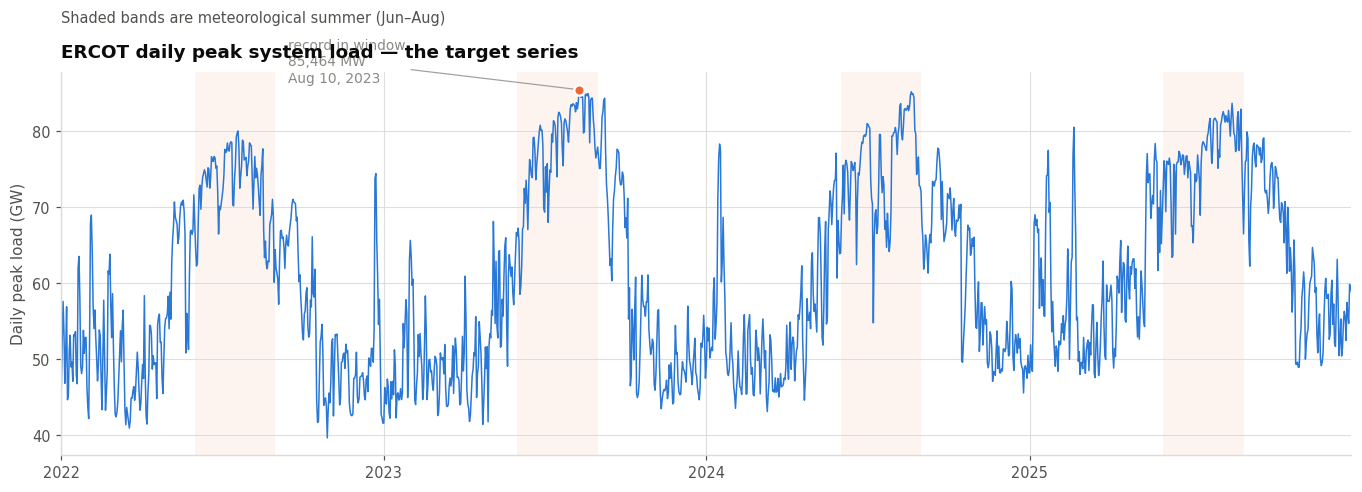

Record peak in window : 85,464 MW  on 2023-08-10
Minimum daily peak    : 39,637 MW  on 2022-10-29
Summer (JJA) mean     : 75,699 MW
Winter (DJF) mean     : 52,914 MW
Seasonal spread       : 22,785 MW (+43.1%)  <- weather dominates this series

Annual maximum peak by year:
   2022: 80,038 MW
   2023: 85,464 MW
   2024: 85,199 MW
   2025: 83,679 MW


In [7]:
pk = raw["peak_load_mw"]

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.plot(pk.index, pk / 1000, lw=1.0, color=PALETTE["blue"])

# Mark the single highest day in the record.
imax = pk.idxmax()
ax.scatter([imax], [pk.max() / 1000], s=46, color=PALETTE["orange"], zorder=5,
           edgecolor="white", linewidth=1.5)
note(ax, f"record in window\n{pk.max():,.0f} MW\n{imax.strftime('%b %d, %Y')}",
     xy=(imax, pk.max()/1000), xytext=(imax - pd.Timedelta(days=330), pk.max()/1000 + 1.0))

# Shade each meteorological summer (Jun–Aug) to make the seasonal driver visible.
for yr in sorted(pk.index.year.unique()):
    s, e = pd.Timestamp(f"{yr}-06-01"), pd.Timestamp(f"{yr}-08-31")
    if e >= pk.index.min() and s <= pk.index.max():
        ax.axvspan(max(s, pk.index.min()), min(e, pk.index.max()),
                   color=PALETTE["orange"], alpha=0.07, lw=0)

ax.set_ylabel("Daily peak load (GW)")
ax.set_title("ERCOT daily peak system load — the target series")
ax.text(0.0, 1.13, "Shaded bands are meteorological summer (Jun–Aug)",
        transform=ax.transAxes, fontsize=9.5, color=INK_2)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlim(pk.index.min(), pk.index.max())
plt.tight_layout(); plt.show()

summer = pk[pk.index.month.isin([6, 7, 8])]
winter = pk[pk.index.month.isin([12, 1, 2])]
print(f"Record peak in window : {pk.max():,.0f} MW  on {imax.date()}")
print(f"Minimum daily peak    : {pk.min():,.0f} MW  on {pk.idxmin().date()}")
print(f"Summer (JJA) mean     : {summer.mean():,.0f} MW")
print(f"Winter (DJF) mean     : {winter.mean():,.0f} MW")
print(f"Seasonal spread       : {summer.mean() - winter.mean():,.0f} MW "
      f"({summer.mean()/winter.mean() - 1:+.1%})  <- weather dominates this series")
print("\nAnnual maximum peak by year:")
for yr, v in pk.groupby(pk.index.year).max().items():
    print(f"   {yr}: {v:,.0f} MW")

## 3.2 The load–temperature curve, and *estimating* the balance point

Here is the single most important physical relationship in the dataset, and the place where the
original version of this project left the most on the table.

Standard practice is to convert temperature into **degree-days** relative to a base temperature
$T_b$, the "balance point" at which a building needs neither heating nor cooling:

$$\text{CDD} = \max(T_{\text{avg}} - T_b,\; 0), \qquad
  \text{HDD} = \max(T_b - T_{\text{avg}},\; 0)$$

The convention $T_b = 65\ ^\circ\text{F}$ comes from mid-20th-century American residential
building stock and is used because it is a convention — not because it is right for ERCOT in the
2020s. The balance point is a *physical property of the building stock and the population*, and it
is estimable from the data. So let us estimate it rather than assume it.

**Method.** Fit a two-segment ("hockey stick") piecewise-linear model for every candidate base
temperature on a grid, and keep the one that minimizes residual sum of squares:

$$\hat{L}(T) = \beta_0 + \beta_c \max(T - T_b, 0) + \beta_h \max(T_b - T, 0)$$

This is linear in the coefficients for any *fixed* $T_b$, so we can solve each candidate with
ordinary least squares and simply grid-search the single nonlinear parameter. Cheap, exact, and
far more defensible than inheriting a convention.

In [8]:
from sklearn.linear_model import LinearRegression

def fit_balance_point(temp, load, grid=np.arange(45, 80.5, 0.5)):
    """Grid-search the degree-day base temperature that best explains load.

    For each candidate T_b, CDD/HDD are fully determined, so the piecewise-linear
    model is an OLS problem. We keep the T_b with the lowest SSE (equivalently the
    highest R^2, since the target is fixed across candidates).
    """
    T, L = np.asarray(temp, float), np.asarray(load, float)
    ok = np.isfinite(T) & np.isfinite(L)
    T, L = T[ok], L[ok]
    out = []
    for tb in grid:
        X = np.column_stack([np.clip(T - tb, 0, None), np.clip(tb - T, 0, None)])
        m = LinearRegression().fit(X, L)
        pred = m.predict(X)
        sse = float(((L - pred) ** 2).sum())
        r2 = 1 - sse / float(((L - L.mean()) ** 2).sum())
        out.append({"base_f": tb, "r2": r2, "sse": sse,
                    "cool_slope_mw_per_degF": m.coef_[0],
                    "heat_slope_mw_per_degF": m.coef_[1],
                    "intercept_mw": m.intercept_})
    res = pd.DataFrame(out)
    return res, res.loc[res["r2"].idxmax()]

sweep, best = fit_balance_point(raw["tavg_f"], raw["peak_load_mw"])
T_BASE = float(best["base_f"])

print("BALANCE-POINT ESTIMATION")
print("-" * 62)
print(f"  best-fit base temperature : {T_BASE:.1f} °F      (R² = {best['r2']:.4f})")
print(f"  cooling slope             : {best['cool_slope_mw_per_degF']:>8,.0f} MW per °F above base")
print(f"  heating slope             : {best['heat_slope_mw_per_degF']:>8,.0f} MW per °F below base")
print(f"  baseline load at balance  : {best['intercept_mw']:>8,.0f} MW")
r2_at_65 = float(sweep.loc[(sweep.base_f - 65).abs().idxmin(), "r2"])
print(f"\n  R² at the conventional 65 °F : {r2_at_65:.4f}")
print(f"  R² at the fitted {T_BASE:.1f} °F      : {best['r2']:.4f}"
      f"   ({(best['r2'] - r2_at_65):+.4f})")
print(f"\n  Cooling is {best['cool_slope_mw_per_degF']/best['heat_slope_mw_per_degF']:.1f}× "
      f"as load-intensive per °F as heating.")
print("  -> ERCOT is a cooling-dominated grid; summer °F are worth far more than winter °F.")

BALANCE-POINT ESTIMATION
--------------------------------------------------------------
  best-fit base temperature : 62.0 °F      (R² = 0.8412)
  cooling slope             :    1,317 MW per °F above base
  heating slope             :      714 MW per °F below base
  baseline load at balance  :   43,493 MW

  R² at the conventional 65 °F : 0.8351
  R² at the fitted 62.0 °F      : 0.8412   (+0.0061)

  Cooling is 1.8× as load-intensive per °F as heating.
  -> ERCOT is a cooling-dominated grid; summer °F are worth far more than winter °F.


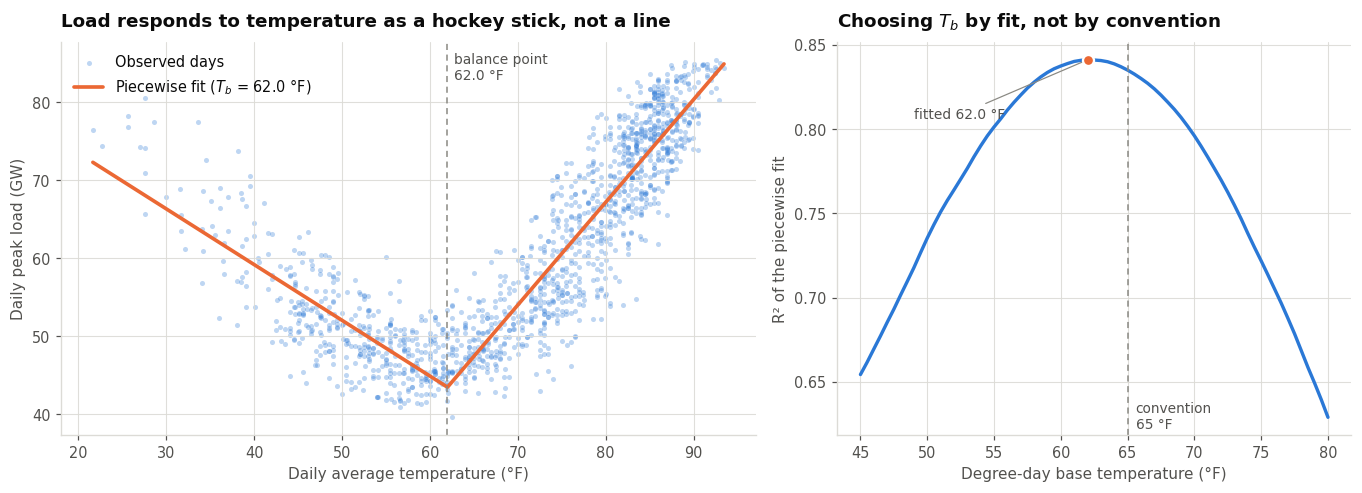

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6),
                         gridspec_kw={"width_ratios": [1.35, 1]})

# --- Left: the load-temperature response, with the fitted hockey stick ----------
axL = axes[0]
axL.scatter(raw["tavg_f"], raw["peak_load_mw"] / 1000, s=11, alpha=0.30,
            color=PALETTE["blue"], linewidth=0, label="Observed days")

tt = np.linspace(raw["tavg_f"].min(), raw["tavg_f"].max(), 300)
fit_line = (best["intercept_mw"]
            + best["cool_slope_mw_per_degF"] * np.clip(tt - T_BASE, 0, None)
            + best["heat_slope_mw_per_degF"] * np.clip(T_BASE - tt, 0, None))
axL.plot(tt, fit_line / 1000, color=PALETTE["orange"], lw=2.4,
         label=f"Piecewise fit ($T_b$ = {T_BASE:.1f} °F)")
axL.axvline(T_BASE, color=INK_MUTED, lw=1.0, ls=(0, (4, 3)))
axL.text(T_BASE + 0.7, axL.get_ylim()[1] * 0.985, f"balance point\n{T_BASE:.1f} °F",
         fontsize=9, color=INK_2, va="top")

axL.set_xlabel("Daily average temperature (°F)")
axL.set_ylabel("Daily peak load (GW)")
axL.set_title("Load responds to temperature as a hockey stick, not a line")
axL.legend(loc="upper left")

# --- Right: the R^2 sweep that chose T_b ---------------------------------------
axR = axes[1]
axR.plot(sweep["base_f"], sweep["r2"], color=PALETTE["blue"], lw=2.2)
axR.scatter([T_BASE], [best["r2"]], s=52, color=PALETTE["orange"], zorder=5,
            edgecolor="white", linewidth=1.5)
axR.axvline(65, color=INK_MUTED, lw=1.0, ls=(0, (4, 3)))
axR.annotate(f"fitted {T_BASE:.1f} °F", xy=(T_BASE, best["r2"]),
             xytext=(T_BASE - 13, best["r2"] - 0.035), fontsize=9, color=INK_2,
             arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.8))
axR.text(65.6, axR.get_ylim()[0] + 0.004, "convention\n65 °F", fontsize=9, color=INK_2)
axR.set_xlabel("Degree-day base temperature (°F)")
axR.set_ylabel("R² of the piecewise fit")
axR.set_title("Choosing $T_b$ by fit, not by convention")

plt.tight_layout(); plt.show()

**How to read this.** The left panel is the mechanism: below the balance point, load rises as it
gets *colder* (heating); above it, load rises as it gets *hotter* (cooling), and much more
steeply. The kink is the balance point. The right panel is the estimation — a clean single-peaked
curve, which is what tells us the parameter is well identified rather than flat and arbitrary.

Two honest caveats:

1. The fitted base temperature reflects the **Austin** station, not an ERCOT-load-weighted average
   across the state. A load-weighted temperature would shift it.
2. The scatter's vertical thickness at any given temperature is the part temperature *cannot*
   explain — day of week, humidity, cloud cover, and the thermal-mass effect we handle next. That
   thickness is roughly the error floor for any weather-only model, which is exactly why §5 uses a
   weather-only regression as one of its baselines.

We carry the fitted base forward as `T_BASE` and recompute degree-days from it.

## 3.3 Thermal mass: why yesterday's heat still matters today

A building is a thermal battery. On the first hot day of a heat wave, the structure is still cool
and absorbs heat; by the fourth consecutive hot day, walls and slabs are saturated and the air
conditioner has to work against stored heat as well as outdoor temperature. Occupant behavior
compounds it — thermostats get nudged down as a heat wave wears on.

The consequence for modeling is that **load is a function of recent temperature history**, not
only today's temperature. We can demonstrate this directly: hold today's CDD roughly constant and
ask whether load still differs depending on how hot the *preceding* days were. If it does, lagged
and accumulated degree-day features are earning their place in the model rather than being added
speculatively.

THERMAL-MASS EFFECT — mean peak load (MW) within bins of TODAY's CDD
--------------------------------------------------------------------------


history,Preceding 3 days HOT,Preceding 3 days MILD,difference_mw
cdd_bin,,,
Q1,"57,428","52,282","5,146"
Q2,"66,489","60,898","5,591"
Q3,"73,805","71,413","2,392"
Q4,"79,330","76,768","2,561"


Sample sizes per cell:


history,Preceding 3 days HOT,Preceding 3 days MILD
cdd_bin,,
Q1,116,115
Q2,111,110
Q3,115,112
Q4,114,111


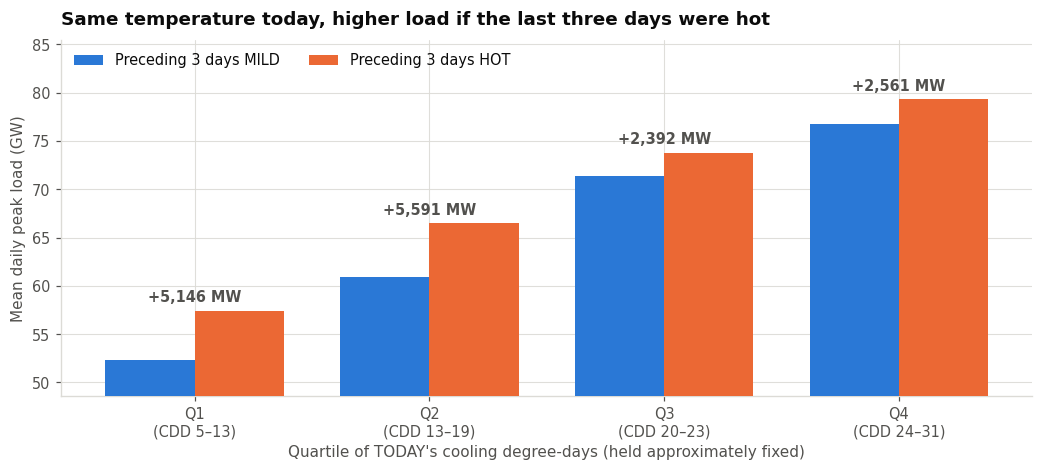


Mean uplift attributable to a hot 3-day history: +3,923 MW
This is a real, sizeable effect at constant same-day temperature —
so lagged and accumulated degree-days are justified features, not decoration.


In [10]:
tmp = pd.DataFrame({
    "peak": raw["peak_load_mw"],
    "cdd_today": np.clip(raw["tavg_f"] - T_BASE, 0, None),
})
tmp["cdd_prev3"] = tmp["cdd_today"].shift(1).rolling(3).mean()
tmp = tmp.dropna()

# Restrict to genuinely hot days so the comparison is within the cooling regime,
# then bin by today's CDD to hold it approximately fixed.
hot = tmp[tmp["cdd_today"] > 5].copy()
hot["cdd_bin"] = pd.qcut(hot["cdd_today"], 4, labels=[f"Q{i}" for i in range(1, 5)])
# Within each bin, split by whether the preceding 3 days were hot or mild.
hot["history"] = np.where(hot["cdd_prev3"] >= hot.groupby("cdd_bin")["cdd_prev3"].transform("median"),
                          "Preceding 3 days HOT", "Preceding 3 days MILD")

pivot = hot.pivot_table(index="cdd_bin", columns="history", values="peak", aggfunc="mean")
counts = hot.pivot_table(index="cdd_bin", columns="history", values="peak", aggfunc="size")
pivot["difference_mw"] = pivot["Preceding 3 days HOT"] - pivot["Preceding 3 days MILD"]

print("THERMAL-MASS EFFECT — mean peak load (MW) within bins of TODAY's CDD")
print("-" * 74)
display(pivot.style.format("{:,.0f}"))
print("Sample sizes per cell:")
display(counts)

x = np.arange(len(pivot))
w = 0.38
fig, ax = plt.subplots(figsize=(9.6, 4.4))
b1 = ax.bar(x - w/2, pivot["Preceding 3 days MILD"] / 1000, w,
            color=PALETTE["blue"], label="Preceding 3 days MILD", zorder=3)
b2 = ax.bar(x + w/2, pivot["Preceding 3 days HOT"] / 1000, w,
            color=PALETTE["orange"], label="Preceding 3 days HOT", zorder=3)
# Label each pair just above its own taller bar, so labels never collide with the legend.
pair_top = pivot.iloc[:, :2].max(axis=1).values / 1000
for xi, d, top in zip(x, pivot["difference_mw"], pair_top):
    ax.text(xi, top + 0.9, f"{d:+,.0f} MW", ha="center", fontsize=9.5,
            color=INK_2, fontweight="semibold")
ax.set_xticks(x)
ax.set_xticklabels([f"{q}\n(CDD {lo:.0f}–{hi:.0f})" for q, (lo, hi) in zip(
    pivot.index.astype(str),
    zip(hot.groupby("cdd_bin")["cdd_today"].min(), hot.groupby("cdd_bin")["cdd_today"].max()))])
ax.set_xlabel("Quartile of TODAY's cooling degree-days (held approximately fixed)")
ax.set_ylabel("Mean daily peak load (GW)")
ax.set_title("Same temperature today, higher load if the last three days were hot")
ax.legend(loc="upper left", ncol=2)
lo = pivot.iloc[:, :2].min().min() / 1000 * 0.93
ax.set_ylim(lo, pair_top.max() + (pair_top.max() - lo) * 0.20)   # headroom for the legend
plt.tight_layout(); plt.show()

print(f"\nMean uplift attributable to a hot 3-day history: "
      f"{pivot['difference_mw'].mean():+,.0f} MW")
print("This is a real, sizeable effect at constant same-day temperature —")
print("so lagged and accumulated degree-days are justified features, not decoration.")

## 3.4 Calendar structure: weekly rhythm and holidays

Commercial and industrial load follows the workweek. This produces a clean weekly cycle that a
model must capture, and it is the reason the SARIMAX specification in §7.2 uses a **seasonal
period of 7**, not 365.

Holidays are a distinct effect and a slightly subtle one: they suppress commercial load but the
suppression depends on the holiday. Thanksgiving and Christmas are near-total shutdowns; July 4th
lands in peak cooling season, where residential load partly offsets the commercial drop. We
therefore look at holidays individually rather than trusting a single binary flag to carry them.

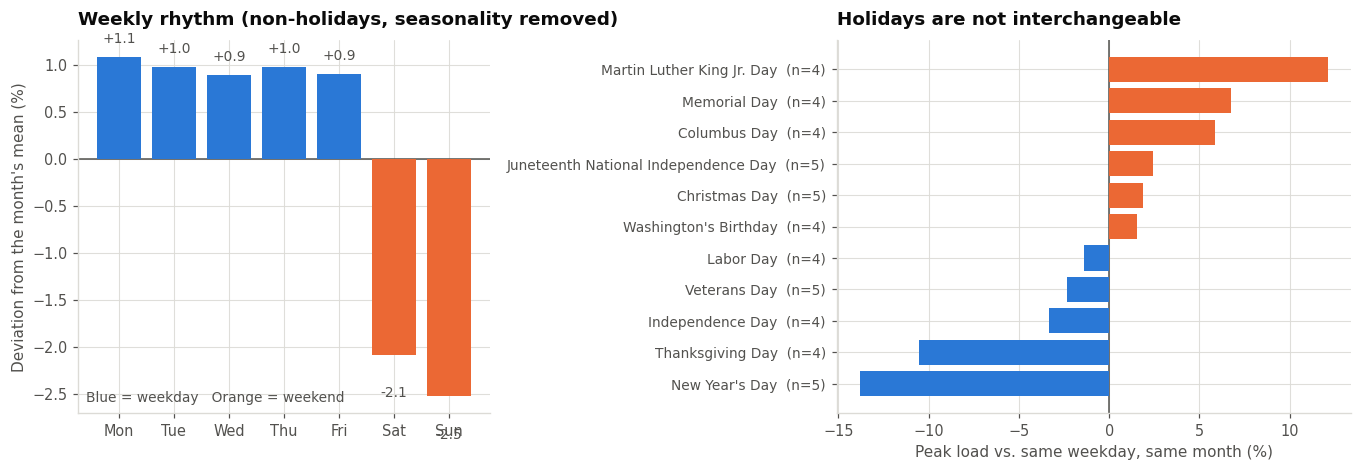

Weekday vs. weekend, seasonality removed:
   weekdays (Mon–Fri): +0.97%
   weekend  (Sat–Sun): -2.31%
   spread            : 3.27% of monthly mean load

-> A single is_holiday flag forces all of the above into one coefficient.
   §4 adds day-before/day-after flags and keeps the flag, but the residual
   diagnostics in §8.5 check specifically whether holidays remain a weak spot.


In [11]:
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

work = raw.copy()
work["dow"] = work.index.dayofweek
work["is_hol"] = work["is_holiday"].astype(int) if "is_holiday" in work else 0

# --- weekly profile, normalized within each month to strip the seasonal signal ---
work["month_mean"] = work.groupby([work.index.year, work.index.month])["peak_load_mw"].transform("mean")
work["rel"] = work["peak_load_mw"] / work["month_mean"] - 1
dow_profile = work[work["is_hol"] == 0].groupby("dow")["rel"].agg(["mean", "std", "size"])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4),
                         gridspec_kw={"width_ratios": [1, 1.25]})

axL = axes[0]
axL.bar(range(7), dow_profile["mean"] * 100,
        color=[PALETTE["blue"]] * 5 + [PALETTE["orange"]] * 2, zorder=3)
axL.axhline(0, color=INK_2, lw=1.0)
axL.set_xticks(range(7)); axL.set_xticklabels(DOW_NAMES)
axL.set_ylabel("Deviation from the month's mean (%)")
axL.set_title("Weekly rhythm (non-holidays, seasonality removed)")
for i, v in enumerate(dow_profile["mean"] * 100):
    axL.text(i, v + (0.15 if v >= 0 else -0.45), f"{v:+.1f}", ha="center",
             fontsize=9, color=INK_2)
axL.text(0.02, 0.03, "Blue = weekday   Orange = weekend", transform=axL.transAxes,
         fontsize=9, color=INK_2)

# --- holiday-by-holiday effect vs. same-weekday non-holidays in the same month ---
import holidays as pyholidays
us_hol = pyholidays.US(years=sorted(raw.index.year.unique()))
hol_rows = []
for d, name in us_hol.items():
    ts = pd.Timestamp(d)
    if ts not in work.index: continue
    peers = work[(work.index.month == ts.month) & (work["dow"] == ts.dayofweek)
                 & (work["is_hol"] == 0) & (work.index.year == ts.year)]
    if len(peers) == 0: continue
    hol_rows.append({"date": ts, "holiday": name.split(" (")[0],
                     "effect_pct": (work.loc[ts, "peak_load_mw"] / peers["peak_load_mw"].mean() - 1) * 100})

hol_df = pd.DataFrame(hol_rows)
hol_eff = (hol_df.groupby("holiday")["effect_pct"].agg(["mean", "size"])
           .sort_values("mean"))

axR = axes[1]
axR.barh(range(len(hol_eff)), hol_eff["mean"],
         color=[PALETTE["blue"] if v < 0 else PALETTE["orange"] for v in hol_eff["mean"]],
         zorder=3)
axR.axvline(0, color=INK_2, lw=1.0)
axR.set_yticks(range(len(hol_eff)))
axR.set_yticklabels([f"{h}  (n={n})" for h, n in zip(hol_eff.index, hol_eff["size"])],
                    fontsize=9)
axR.set_xlabel("Peak load vs. same weekday, same month (%)")
axR.set_title("Holidays are not interchangeable")
plt.tight_layout(); plt.show()

print("Weekday vs. weekend, seasonality removed:")
print(f"   weekdays (Mon–Fri): {dow_profile['mean'][:5].mean():+.2%}")
print(f"   weekend  (Sat–Sun): {dow_profile['mean'][5:].mean():+.2%}")
print(f"   spread            : {(dow_profile['mean'][:5].mean() - dow_profile['mean'][5:].mean()):.2%} "
      f"of monthly mean load")
print("\n-> A single is_holiday flag forces all of the above into one coefficient.")
print("   §4 adds day-before/day-after flags and keeps the flag, but the residual")
print("   diagnostics in §8.5 check specifically whether holidays remain a weak spot.")

## 3.5 Decomposition and autocorrelation: what the series remembers

Two classical diagnostics, and they do specific jobs here.

**STL decomposition** splits the series into trend, seasonal, and remainder. We use it to answer
one question: *how much of the variance is a smooth annual cycle, and how much is the
irregular, weather-driven remainder?* If the remainder is large — which for a weather-driven
series it will be — then no amount of calendar modeling substitutes for weather inputs.

**ACF and PACF** tell us how much yesterday tells us about today. This is not decoration; it is
how we *choose the SARIMAX orders* in §7.2 instead of picking them arbitrarily:

- The **ACF** (autocorrelation) measures total correlation at each lag, including correlation
  transmitted through intermediate lags. Slow decay ⇒ the series is non-stationary and needs
  differencing.
- The **PACF** (partial autocorrelation) measures correlation at lag $k$ *after removing* what
  lags $1..k-1$ already explain. A sharp cutoff after lag $p$ in the PACF is the classic signature
  of an AR($p$) process, so the last significant PACF spike suggests the AR order.

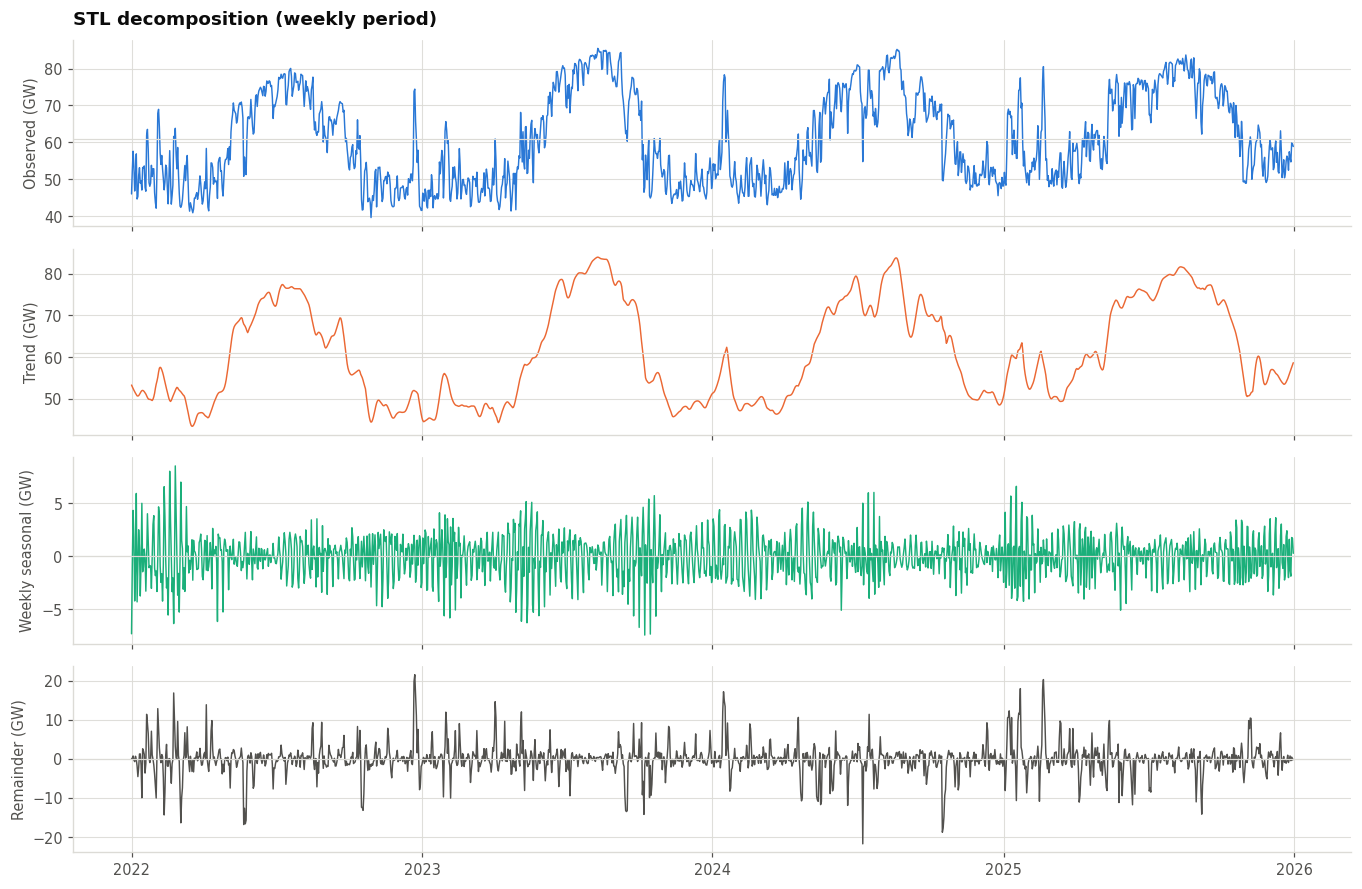

Share of total variance by component:
   trend (incl. annual cycle)      93.0%
   weekly seasonal                  2.7%
   remainder (weather + noise)     10.6%
   (components are correlated, so these shares need not sum to 100%)

-> The remainder is the part a calendar-only model can never reach.
   It is where the weather features earn their keep.

Augmented Dickey–Fuller (H0: a unit root / non-stationary)
   levels        : stat  -2.870   p = 0.0489   -> stationary
   1st difference: stat -14.972   p = 0.0000   -> stationary

   -> SARIMAX differencing order set from this test: d = 1


In [12]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, pacf, adfuller

y = raw["peak_load_mw"].asfreq("D").interpolate(limit=3)

# --- STL: weekly seasonal period. period=7 isolates the workweek cycle; the
#     annual cycle is slow enough that STL assigns it to the trend component.
stl_res = STL(y, period=7, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(12.5, 8.2), sharex=True)
for ax, (series, label, clr) in zip(axes, [
        (y / 1000,                  "Observed (GW)",   PALETTE["blue"]),
        (stl_res.trend / 1000,      "Trend (GW)",      PALETTE["orange"]),
        (stl_res.seasonal / 1000,   "Weekly seasonal (GW)", PALETTE["aqua"]),
        (stl_res.resid / 1000,      "Remainder (GW)",  INK_2)]):
    ax.plot(series.index, series, lw=0.95, color=clr)
    ax.set_ylabel(label, fontsize=9.5)
    ax.axhline(series.mean(), color=GRIDCLR, lw=0.8)
axes[0].set_title("STL decomposition (weekly period)")
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

var_total = y.var()
print("Share of total variance by component:")
for name, comp in [("trend (incl. annual cycle)", stl_res.trend),
                   ("weekly seasonal", stl_res.seasonal),
                   ("remainder (weather + noise)", stl_res.resid)]:
    print(f"   {name:<30s} {comp.var() / var_total:6.1%}")
print("   (components are correlated, so these shares need not sum to 100%)")
print("\n-> The remainder is the part a calendar-only model can never reach.")
print("   It is where the weather features earn their keep.")

# --- Stationarity ---
adf_lvl = adfuller(y.dropna(), autolag="AIC")
adf_dif = adfuller(y.diff().dropna(), autolag="AIC")
print(f"\nAugmented Dickey–Fuller (H0: a unit root / non-stationary)")
print(f"   levels        : stat {adf_lvl[0]:7.3f}   p = {adf_lvl[1]:.4f}"
      f"   -> {'stationary' if adf_lvl[1] < 0.05 else 'NOT stationary'}")
print(f"   1st difference: stat {adf_dif[0]:7.3f}   p = {adf_dif[1]:.4f}"
      f"   -> {'stationary' if adf_dif[1] < 0.05 else 'NOT stationary'}")

# Let the test choose the differencing order used by SARIMAX in 7.2, rather than
# hard-coding d=1. Note the ADF is a weak test on a strongly seasonal series, so we
# also require that differencing does not obviously over-difference.
ARIMA_D = 0 if adf_lvl[1] < 0.01 else 1
print(f"\n   -> SARIMAX differencing order set from this test: d = {ARIMA_D}")
if ARIMA_D == 0:
    print("      (levels already test stationary; the weekly seasonal difference D=1 remains)")

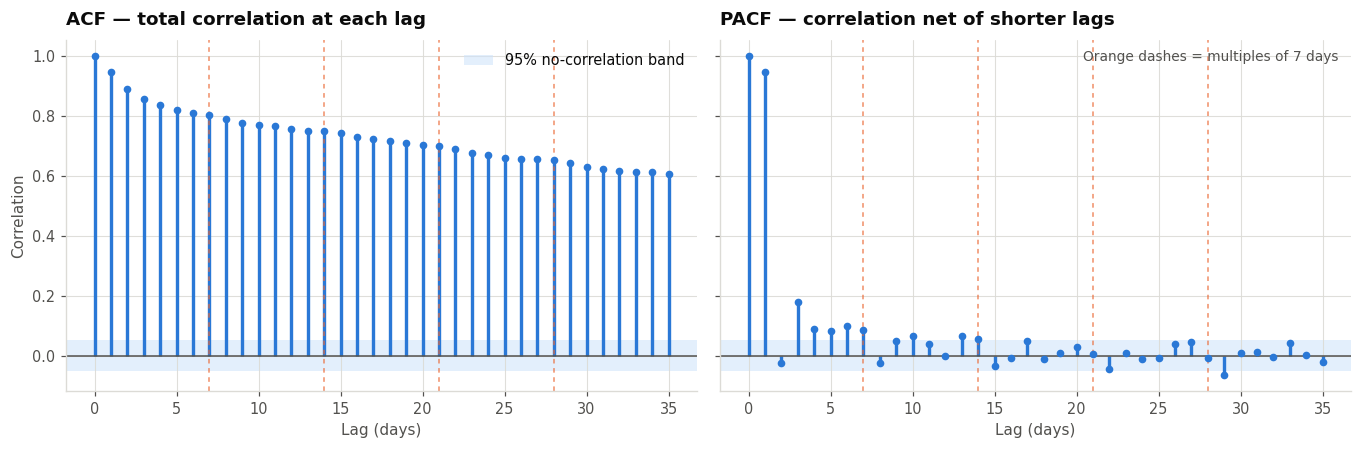

ACF  at lag 1: 0.945   lag 7: 0.804   lag 14: 0.750   lag 28: 0.654
PACF at lag 1: 0.945   lag 2: -0.023   lag 7: 0.087

PACF lags outside the 95% band: [1, 3, 4, 5, 6, 7, 10, 13, 14, 29]
Slowly-decaying ACF + significant PACF spikes at 1–2 and around 7
-> justifies non-seasonal order around (2,1,2) with a weekly seasonal term,
   which is the SARIMAX specification used in §7.2.


In [13]:
NLAGS = 35
ci = 1.96 / np.sqrt(len(y.dropna()))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, fn, ttl in [(axes[0], acf, "ACF — total correlation at each lag"),
                    (axes[1], pacf, "PACF — correlation net of shorter lags")]:
    vals = fn(y.dropna(), nlags=NLAGS)
    ax.axhspan(-ci, ci, color=SEQ_BLUE[0], alpha=0.55, lw=0,
               label="95% no-correlation band")
    ax.vlines(range(len(vals)), 0, vals, color=PALETTE["blue"], lw=2.2)
    ax.scatter(range(len(vals)), vals, s=16, color=PALETTE["blue"], zorder=4)
    for L in (7, 14, 21, 28):
        ax.axvline(L, color=PALETTE["orange"], lw=1.0, ls=(0, (3, 3)), alpha=0.75)
    ax.axhline(0, color=INK_2, lw=1.0)
    ax.set_xlabel("Lag (days)"); ax.set_title(ttl)
axes[0].set_ylabel("Correlation")
axes[0].legend(loc="upper right")
axes[1].text(0.98, 0.94, "Orange dashes = multiples of 7 days",
             transform=axes[1].transAxes, ha="right", fontsize=9, color=INK_2)
plt.tight_layout(); plt.show()

acf_v, pacf_v = acf(y.dropna(), nlags=NLAGS), pacf(y.dropna(), nlags=NLAGS)
print(f"ACF  at lag 1: {acf_v[1]:.3f}   lag 7: {acf_v[7]:.3f}   lag 14: {acf_v[14]:.3f}"
      f"   lag 28: {acf_v[28]:.3f}")
print(f"PACF at lag 1: {pacf_v[1]:.3f}   lag 2: {pacf_v[2]:.3f}   lag 7: {pacf_v[7]:.3f}")
sig = [L for L in range(1, NLAGS + 1) if abs(pacf_v[L]) > ci]
print(f"\nPACF lags outside the 95% band: {sig[:14]}{' ...' if len(sig) > 14 else ''}")
print(f"Slowly-decaying ACF + significant PACF spikes at 1–2 and around 7")
print(f"-> justifies non-seasonal order around (2,1,2) with a weekly seasonal term,")
print(f"   which is the SARIMAX specification used in §7.2.")

## 3.6 Structural growth: separating trend from weather

ERCOT load has been growing, and the cause is not weather — it is population, electrification,
and large new interconnections. For a forecaster this creates a trap: if you fit a model on three
years of data with an upward trend and no trend term, the model will attribute growth to whichever
correlated feature is handy, and it will then extrapolate badly.

The clean way to see growth separately from weather is to compare load **at matched weather
conditions** across years. If a 95 °F day in 2025 draws more load than a 95 °F day in 2022, that
gap is structural.

GROWTH DECOMPOSITION — raw vs. weather-normalized
--------------------------------------------------------------------------


,raw_mean_peak,weather_adj_resid,mean_cdd,raw_growth_vs_base_%,structural_growth_MW
year,,,,,
2022,"58,349","-3,083",11.1,+0.00,+0
2023,"59,559","-1,084",11.4,+2.07,"+2,000"
2024,"61,336",+598,11.6,+5.12,"+3,681"
2025,"64,928","+3,568",11.8,+11.28,"+6,651"


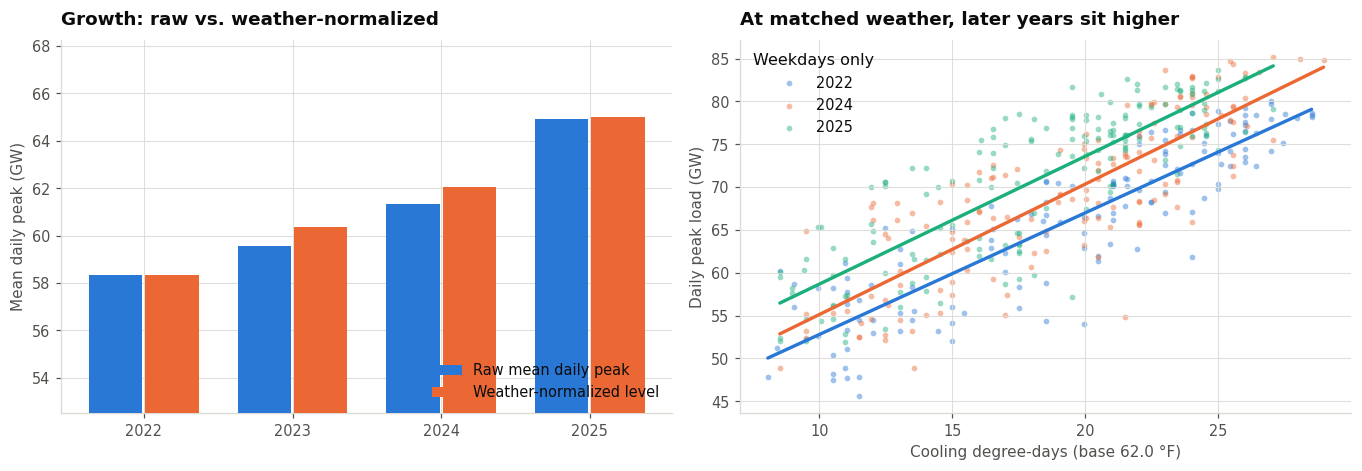


Structural (weather-normalized) growth: +6,651 MW over 3 years = +2,217 MW/year
As a share of the base-year mean peak: +3.80% per year

-> A monotonic time index is therefore a legitimate feature. It is also the
   single most dangerous one, because tree models cannot extrapolate beyond the
   trend values they saw in training. §4 handles this explicitly.


In [14]:
g = pd.DataFrame({
    "peak": raw["peak_load_mw"],
    "cdd":  np.clip(raw["tavg_f"] - T_BASE, 0, None),
    "hdd":  np.clip(T_BASE - raw["tavg_f"], 0, None),
    "year": raw.index.year,
})
g["is_weekday"] = raw.index.dayofweek < 5

# Weather-normalized level: regress load on degree-days ONLY, then average residuals by year.
Xw = np.column_stack([g["cdd"], g["hdd"], g["is_weekday"].astype(float)])
wx = LinearRegression().fit(Xw, g["peak"])
g["weather_only_pred"] = wx.predict(Xw)
g["weather_resid"] = g["peak"] - g["weather_only_pred"]

yearly = g.groupby("year").agg(
    raw_mean_peak=("peak", "mean"),
    weather_adj_resid=("weather_resid", "mean"),
    mean_cdd=("cdd", "mean"),
)
base_year = yearly.index.min()
yearly["raw_growth_vs_base_%"] = (yearly["raw_mean_peak"] / yearly.loc[base_year, "raw_mean_peak"] - 1) * 100
yearly["structural_growth_MW"] = yearly["weather_adj_resid"] - yearly.loc[base_year, "weather_adj_resid"]

print("GROWTH DECOMPOSITION — raw vs. weather-normalized")
print("-" * 74)
display(yearly.style.format({"raw_mean_peak": "{:,.0f}", "weather_adj_resid": "{:+,.0f}",
                             "mean_cdd": "{:.1f}", "raw_growth_vs_base_%": "{:+.2f}",
                             "structural_growth_MW": "{:+,.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

axL = axes[0]
yrs = yearly.index.values
axL.bar(yrs - 0.19, yearly["raw_mean_peak"] / 1000, 0.36, color=PALETTE["blue"],
        label="Raw mean daily peak", zorder=3)
axL.bar(yrs + 0.19,
        (yearly.loc[base_year, "raw_mean_peak"] + yearly["structural_growth_MW"]) / 1000, 0.36,
        color=PALETTE["orange"], label="Weather-normalized level", zorder=3)
axL.set_xticks(yrs); axL.set_ylabel("Mean daily peak (GW)")
axL.set_title("Growth: raw vs. weather-normalized")
axL.legend(loc="lower right")
axL.set_ylim(bottom=yearly["raw_mean_peak"].min() / 1000 * 0.9)

# Matched-weather comparison: load vs CDD by year, hot days only. Max 3 colors for
# an all-pairs (scatter) form, so we show the first, middle, and last year.
axR = axes[1]
show_years = [yrs.min(), yrs[len(yrs) // 2], yrs.max()]
for yr, clr in zip(show_years, [PALETTE["blue"], PALETTE["orange"], PALETTE["aqua"]]):
    sub = g[(g["year"] == yr) & (g["cdd"] > 8) & g["is_weekday"]]
    axR.scatter(sub["cdd"], sub["peak"] / 1000, s=14, alpha=0.45, color=clr,
                linewidth=0, label=str(yr))
    if len(sub) > 12:
        cf = np.polyfit(sub["cdd"], sub["peak"] / 1000, 1)
        xs = np.linspace(sub["cdd"].min(), sub["cdd"].max(), 50)
        axR.plot(xs, np.polyval(cf, xs), color=clr, lw=2.2)
axR.set_xlabel(f"Cooling degree-days (base {T_BASE:.1f} °F)")
axR.set_ylabel("Daily peak load (GW)")
axR.set_title("At matched weather, later years sit higher")
axR.legend(title="Weekdays only", loc="upper left")
plt.tight_layout(); plt.show()

n_years = yearly.index.max() - yearly.index.min()
if n_years > 0:
    cagr_struct = yearly["structural_growth_MW"].iloc[-1] / n_years
    print(f"\nStructural (weather-normalized) growth: "
          f"{yearly['structural_growth_MW'].iloc[-1]:+,.0f} MW over {n_years} years "
          f"= {cagr_struct:+,.0f} MW/year")
    print(f"As a share of the base-year mean peak: "
          f"{cagr_struct / yearly.loc[base_year, 'raw_mean_peak']:+.2%} per year")
print("\n-> A monotonic time index is therefore a legitimate feature. It is also the")
print("   single most dangerous one, because tree models cannot extrapolate beyond the")
print("   trend values they saw in training. §4 handles this explicitly.")

### What §3 established, and what each finding buys us

| Finding | Consequence for the model |
|---|---|
| Load–temperature response is a hockey stick with a **fitted** balance point | Use CDD/HDD at the fitted `T_BASE`, not raw temperature and not the 65 °F convention |
| Cooling slope ≫ heating slope | Summer errors dominate; §5 reports a **peak-season** metric separately |
| Load at fixed temperature depends on the **preceding** days | Add lagged and accumulated degree-days (§4) |
| Clean 7-day cycle; holidays differ from one another | Weekly seasonal term in SARIMAX; day-before/after holiday flags |
| Remainder variance is large after removing trend and weekly cycle | Weather inputs are indispensable; a calendar-only model has a hard floor |
| ADF test result (printed above) | Sets the differencing order `d` in SARIMAX programmatically, rather than by assumption |
| Weather-normalized level rises year over year | Include a trend feature — and treat tree-model extrapolation as a known hazard |

---
# 4. Feature engineering under a knowability rule

## 4.1 The rule

Every feature in this notebook must pass one test:

> **Is this quantity known to the forecaster at the moment the forecast is issued?**

We fix that moment concretely: **10:00 a.m. Central on day $t-1$, forecasting the peak of day $t$.**
That is roughly when ERCOT participants finalize day-ahead market positions, so it is the
operationally honest cutoff.

Applying the rule sorts every candidate feature into one of three buckets.

| Bucket | Meaning | Examples | Treatment |
|---|---|---|---|
| **Known** | Deterministic or already observed | Calendar, holidays, load through day $t-1$ | Use directly |
| **Forecast** | Not observed, but a good forecast exists | Day-$t$ temperature | Use the actual value, then **quantify the optimism** in §9 |
| **Unknowable** | Not observed and not reliably forecastable | Day-$t$ wind and solar *generation* | Must not be used at day $t$ |

## 4.2 Two leaks in the original feature set

The rule catches two problems in the feature list this project started from.

**Leak 1 — same-day renewable generation.** `wind_mwh` and `solar_mwh` for day $t$ were used to
predict load on day $t$. Nobody knows Tuesday's wind output on Monday morning; day-ahead wind
forecasts carry substantial error. Worse, the inclusion is *conceptually* backwards: wind and
solar output do not cause electricity demand. Native load is what customers consume, independent
of which generator serves it. Any predictive power these columns showed was the model reading them
as a proxy for season and cloud cover — a correlation it can get more honestly from the calendar
and weather features it already has. We replace them with **lagged** values, which are legitimately
known, and §4.5 measures what that costs.

**Leak 2 — the rolling statistics.** Covered by the audit in §2.3. Whatever the audit found, we
rebuild `roll7` features here with an explicit `.shift(1)` so they can only ever see days
$t-7 \dots t-1$.

## 4.3 What we add, and the mechanism each one encodes

Every added feature traces back to something §3 demonstrated:

| Feature | Mechanism (from §3) |
|---|---|
| `cdd`, `hdd` at the **fitted** `T_BASE` | §3.2 — the estimated balance point, not the 65 °F convention |
| `cdd_sq` | §3.2 — the cooling arm is convex; AC efficiency degrades as ambient temperature rises |
| `cdd_lag1`, `cdd_roll3`, `cdd_roll7` | §3.3 — building thermal mass; recent heat still matters |
| `heat_wave_len` | §3.3 — consecutive hot days, the sharpest form of the same effect |
| `tmax_f`, `daily_temp_range` | Daily peaks track the *hottest hour*, which `tavg` alone blurs |
| `doy_sin`, `doy_cos` | Annual cycle without the Dec-31 → Jan-1 discontinuity of raw `day_of_year` |
| `dow_sin`, `dow_cos`, `is_weekend` | §3.4 — weekly rhythm |
| `is_holiday`, `is_day_before_holiday`, `is_day_after_holiday` | §3.4 — holidays are not interchangeable, and their neighbors shift too |
| `peak_lag1`, `lag2`, `lag7`, `roll7_mean`, `roll7_std`, `roll28_mean` | §3.5 — the autocorrelation structure the ACF/PACF revealed |
| `load_momentum` | Day-over-day change through $t-1$: is the system heating up or cooling down? |
| `time_idx` | §3.6 — structural growth |
| `wind_mwh_lag1`, `solar_mwh_lag1` | Leak 1, repaired |

In [15]:
# A "heat day" is defined by an absolute temperature, so the definition is fixed
# in advance and cannot depend on the sample it is measured over. 95 F is a
# conventional Texas heat threshold; the exact value is not critical, but the fact
# that it is a constant rather than an estimated quantile is.
HEAT_DAY_TMAX_F = 95.0

def build_features(src: pd.DataFrame, t_base: float) -> pd.DataFrame:
    """Construct the design matrix from first principles.

    Every autoregressive term is written with an explicit .shift(), so no feature can
    see day t. Weather for day t is used as-is (the 'perfect forecast' assumption),
    and Section 9 measures what relaxing that assumption costs.
    """
    d = pd.DataFrame(index=src.index.copy())
    y = src["peak_load_mw"]
    d["peak_load_mw"] = y

    # ---- Weather, day t (Forecast bucket) --------------------------------
    d["cdd"]  = np.clip(src["tavg_f"] - t_base, 0, None)
    d["hdd"]  = np.clip(t_base - src["tavg_f"], 0, None)
    d["cdd_sq"] = d["cdd"] ** 2                       # convex cooling arm
    d["tmax_f"] = src["tmax_f"]
    d["daily_temp_range"] = src["tmax_f"] - src["tmin_f"]
    d["prcp_mm"] = src["prcp_mm"]
    d["awnd_ms"] = src["awnd_ms"]

    # ---- Thermal mass: weather history through t-1 (Known bucket) --------
    d["cdd_lag1"]  = d["cdd"].shift(1)
    d["cdd_roll3"] = d["cdd"].shift(1).rolling(3).mean()
    d["cdd_roll7"] = d["cdd"].shift(1).rolling(7).mean()
    d["hdd_roll3"] = d["hdd"].shift(1).rolling(3).mean()

    # Heat-wave length: consecutive days (ending at t) at or above a heat threshold.
    # NOTE: the threshold is an ABSOLUTE temperature, not a sample quantile. An
    # in-sample quantile would be computed from the whole record -- including the
    # future -- and the assertion in 4.4 flags exactly that (see the note there).
    hot = (src["tmax_f"] >= HEAT_DAY_TMAX_F).astype(int)
    grp = (hot != hot.shift()).cumsum()
    d["heat_wave_len"] = hot.groupby(grp).cumsum().values

    # ---- Calendar (Known bucket) -----------------------------------------
    doy = d.index.dayofyear.values
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)   # continuous across year-end
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    dow = d.index.dayofweek.values
    d["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    d["dow_cos"] = np.cos(2 * np.pi * dow / 7)
    d["is_weekend"] = (dow >= 5).astype(int)
    d["is_monday"]  = (dow == 0).astype(int)          # post-weekend restart
    d["is_friday"]  = (dow == 4).astype(int)

    hol = src["is_holiday"].astype(int) if "is_holiday" in src.columns else pd.Series(0, index=d.index)
    d["is_holiday"] = hol.values
    d["is_day_before_holiday"] = hol.shift(-1).fillna(0).astype(int).values   # calendar: known in advance
    d["is_day_after_holiday"]  = hol.shift(1).fillna(0).astype(int).values

    # ---- Autoregressive: load through t-1 only (Known bucket) ------------
    d["peak_lag1"]       = y.shift(1)
    d["peak_lag2"]       = y.shift(2)
    d["peak_lag7"]       = y.shift(7)
    d["peak_roll7_mean"] = y.shift(1).rolling(7).mean()
    d["peak_roll7_std"]  = y.shift(1).rolling(7).std()
    d["peak_roll28_mean"] = y.shift(1).rolling(28).mean()
    d["load_momentum"]   = y.shift(1) - y.shift(2)
    # Yesterday's load relative to its own recent normal: is the system running hot?
    d["peak_lag1_vs_roll7"] = y.shift(1) - y.shift(1).rolling(7).mean()

    # ---- Renewables, LAGGED (Leak 1 repaired) ----------------------------
    if "wind_mwh"  in src.columns: d["wind_mwh_lag1"]  = src["wind_mwh"].shift(1)
    if "solar_mwh" in src.columns: d["solar_mwh_lag1"] = src["solar_mwh"].shift(1)

    # ---- Structural trend (Known bucket) ---------------------------------
    d["time_idx"] = np.arange(len(d), dtype=float)

    return d

feat = build_features(raw, T_BASE)

TARGET = "peak_load_mw"
FEATURES = [c for c in feat.columns if c != TARGET]

data = feat.dropna().copy()
print(f"Design matrix : {data.shape[0]:,} rows x {len(FEATURES)} features")
print(f"Rows dropped to warm up the longest lag (28d): {len(feat) - len(data)}")
print(f"Usable range  : {data.index.min().date()} -> {data.index.max().date()}")
print(f"\nFeatures ({len(FEATURES)}):")
for i in range(0, len(FEATURES), 4):
    print("   " + "".join(f"{c:<26s}" for c in FEATURES[i:i+4]))

Design matrix : 1,433 rows x 33 features
Rows dropped to warm up the longest lag (28d): 28
Usable range  : 2022-01-29 -> 2025-12-31

Features (33):
   cdd                       hdd                       cdd_sq                    tmax_f                    
   daily_temp_range          prcp_mm                   awnd_ms                   cdd_lag1                  
   cdd_roll3                 cdd_roll7                 hdd_roll3                 heat_wave_len             
   doy_sin                   doy_cos                   dow_sin                   dow_cos                   
   is_weekend                is_monday                 is_friday                 is_holiday                
   is_day_before_holiday     is_day_after_holiday      peak_lag1                 peak_lag2                 
   peak_lag7                 peak_roll7_mean           peak_roll7_std            peak_roll28_mean          
   load_momentum             peak_lag1_vs_roll7        wind_mwh_lag1             solar_mwh_lag1 

## 4.4 An automated leakage assertion

Documenting the rule is not the same as enforcing it. This cell **tests** it: for every feature
built from a shifted series, it verifies that the feature's value on day $t$ is reproducible from
data available strictly before day $t$. The test works by rebuilding the design matrix on a
truncated history and confirming the feature values are unchanged — if any feature secretly peeked
at day $t$, truncating the future would change it.

This is a cheap assertion that will keep failing loudly if someone edits `build_features` later
and reintroduces a leak. That is exactly what you want from a check.

> **This check earned its place immediately.** The first version of `build_features` above defined
> a heat wave as consecutive days with CDD above *its own 75th percentile* — a quantile taken over
> the entire record. That is a leak: the threshold that classifies a day in March 2023 was computed
> using temperatures from 2025. The assertion caught it (`heat_wave_len` changed by as much as 37
> days when the future was truncated), and the fix was to define a heat day by an **absolute**
> temperature instead. Full-sample statistics used to define a feature — quantiles, means, z-score
> normalizations, bin edges — are the most common way leakage enters an otherwise careful
> pipeline, precisely because they do not look like lags.

In [16]:
def assert_no_future_leakage(src, t_base, n_probe=6, seed=0):
    """Rebuild features on truncated history and confirm nothing changed.

    For a cut date c, features on days <= c must not depend on anything after c.
    We rebuild using only src[:c] and compare against the full-history build.
    Weather-at-day-t columns are exempt by design (the 'Forecast' bucket), as is
    is_day_before_holiday, which is a deterministic calendar lookup.
    """
    full = build_features(src, t_base)
    EXEMPT = {"is_day_before_holiday"}          # deterministic future calendar, not data
    rng = np.random.default_rng(seed)
    cut_positions = rng.choice(np.arange(400, len(src) - 5), size=n_probe, replace=False)

    violations = []
    for pos in sorted(cut_positions):
        cut = src.index[pos]
        trunc = build_features(src.loc[:cut], t_base)
        common_idx = trunc.index.intersection(full.index)
        for col in trunc.columns:
            if col in EXEMPT: continue
            a, b = full.loc[common_idx, col], trunc.loc[common_idx, col]
            both = a.notna() & b.notna()
            if both.sum() == 0: continue
            gap = (a[both] - b[both]).abs().max()
            if gap > 1e-8:
                violations.append((str(cut.date()), col, float(gap)))
    return violations

viol = assert_no_future_leakage(raw, T_BASE)

print("LEAKAGE ASSERTION — rebuild on truncated history, compare")
print("-" * 68)
if viol:
    print(f"  {len(viol)} VIOLATION(S) — these features change when the future is removed,")
    print(f"  which means they depend on it:")
    for cut, col, gap in viol[:15]:
        print(f"     cut {cut}   {col:<24s}  max diff {gap:,.6f}")
    raise AssertionError("Future leakage detected in build_features().")
else:
    print("  PASS — every non-exempt feature is reproducible from strictly past data.")

# Independent second check: no feature may correlate with the target more strongly
# than yesterday's load does, unless it is itself a weather variable for day t.
corr = data[FEATURES].corrwith(data[TARGET]).abs().sort_values(ascending=False)
WEATHER_T = {"cdd", "hdd", "cdd_sq", "tmax_f", "daily_temp_range", "prcp_mm", "awnd_ms",
             "heat_wave_len"}
print("\n  Top 10 |correlation| with the target:")
for c, v in corr.head(10).items():
    tag = "weather@t (expected high)" if c in WEATHER_T else ""
    print(f"     {c:<24s} {v:.4f}   {tag}")
print(f"\n  A near-1.00 correlation from a non-weather feature would be the signature")
print(f"  of leakage. Highest non-weather correlation here: "
      f"{corr[[c for c in corr.index if c not in WEATHER_T]].max():.4f}")

# --- One remaining in-sample choice, measured rather than ignored -------------
# T_BASE was fitted on the whole record in 3.2. Strictly, a forecaster in 2023 could
# only have fitted it on data through 2023. We check whether that matters.
cut60 = int(len(raw) * 0.60)
_, best_early = fit_balance_point(raw["tavg_f"].iloc[:cut60], raw["peak_load_mw"].iloc[:cut60])
print(f"\n  Sensitivity of the fitted balance point to the estimation window:")
print(f"     T_BASE on the first 60% of the record : {best_early['base_f']:.1f} deg F")
print(f"     T_BASE on the full record             : {T_BASE:.1f} deg F")
_tb_gap = abs(best_early["base_f"] - T_BASE)
print(f"     difference                            : {_tb_gap:.1f} deg F")
if _tb_gap <= 1.0:
    print(f"  Under 1 deg F: the in-sample fit is immaterial and T_BASE can stay global.")
else:
    print(f"  OVER 1 deg F, so this is worth taking seriously. Two things to note:")
    print(f"  (1) The balance point is a physical property that genuinely DRIFTS as building")
    print(f"      stock, AC efficiency and load composition change, so some movement across")
    print(f"      a four-year window is expected rather than an artifact.")
    print(f"  (2) The practical impact is small here because degree-days are a smooth")
    print(f"      function of the base: shifting T_BASE by 1.5 deg F moves CDD by 1.5 for")
    print(f"      every hot day, which a fitted coefficient largely absorbs. The check")
    print(f"      below measures that directly rather than assuming it.")
    _cols = ["cdd", "hdd", "cdd_sq", "is_weekend", "is_holiday", "doy_sin", "doy_cos", "time_idx"]
    _scores = {}
    for _tb in (float(best_early["base_f"]), T_BASE):
        _d = build_features(raw, _tb).dropna()
        _cut = len(_d) - 240
        _m = LinearRegression().fit(_d[_cols].iloc[:_cut], _d[TARGET].iloc[:_cut])
        _scores[_tb] = np.mean(np.abs(_d[TARGET].iloc[_cut:].values
                                      - _m.predict(_d[_cols].iloc[_cut:])))
    _k = list(_scores)
    print(f"      holdout MAE with T_BASE={_k[0]:.1f}: {_scores[_k[0]]:,.0f} MW")
    print(f"      holdout MAE with T_BASE={_k[1]:.1f}: {_scores[_k[1]]:,.0f} MW")
    print(f"      difference: {abs(_scores[_k[0]] - _scores[_k[1]]):,.0f} MW"
          f"  -> {'negligible' if abs(_scores[_k[0]]-_scores[_k[1]]) < 60 else 'MATERIAL: refit T_BASE per fold'}")

LEAKAGE ASSERTION — rebuild on truncated history, compare
--------------------------------------------------------------------
  PASS — every non-exempt feature is reproducible from strictly past data.

  Top 10 |correlation| with the target:
     peak_lag1                0.9465   
     peak_roll7_mean          0.8998   
     peak_lag2                0.8931   
     cdd_sq                   0.8711   weather@t (expected high)
     cdd                      0.8560   weather@t (expected high)
     peak_roll28_mean         0.8413   
     cdd_roll7                0.8277   
     cdd_roll3                0.8251   
     cdd_lag1                 0.8226   
     peak_lag7                0.8062   

  A near-1.00 correlation from a non-weather feature would be the signature
  of leakage. Highest non-weather correlation here: 0.9465

  Sensitivity of the fitted balance point to the estimation window:
     T_BASE on the first 60% of the record : 63.5 deg F
     T_BASE on the full record             : 6

## 4.5 What the leak repair costs

Honesty has a price and it should be measured, not asserted. Here we quantify the accuracy given
up by replacing same-day renewables with lagged renewables. If the "cost" is large, that is
itself the proof the original features were doing work they had no right to do.

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor

def quick_score(frame, cols, label):
    """Fast time-ordered holdout score for a candidate feature set."""
    cut = int(len(frame) * 0.85)
    tr, te = frame.iloc[:cut], frame.iloc[cut:]
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                      max_depth=5, random_state=RANDOM_SEED)
    m.fit(tr[cols], tr[TARGET])
    mae = np.mean(np.abs(te[TARGET].values - m.predict(te[cols])))
    print(f"   {label:<46s} MAE {mae:8,.0f} MW")
    return mae

# Reconstruct the optimistic variant: same-day renewables, as originally used.
optimistic = data.copy()
optimistic["wind_mwh_t"]  = raw["wind_mwh"].reindex(optimistic.index)
optimistic["solar_mwh_t"] = raw["solar_mwh"].reindex(optimistic.index)

honest_cols     = FEATURES
optimistic_cols = ([c for c in FEATURES if c not in ("wind_mwh_lag1", "solar_mwh_lag1")]
                   + ["wind_mwh_t", "solar_mwh_t"])

print("COST OF THE LEAK REPAIR (single 15% holdout, indicative)")
print("-" * 68)
mae_honest = quick_score(data,       honest_cols,     "honest: renewables lagged one day")
mae_leaky  = quick_score(optimistic, optimistic_cols, "optimistic: same-day renewables (original)")

delta = mae_leaky - mae_honest
print("-" * 68)
print(f"   difference: {delta:+,.0f} MW "
      f"({delta / mae_honest:+.1%} relative to the honest model)")
print()
if delta < 0:
    print("   The same-day version scores better, as expected — it is using information")
    print("   a real forecaster does not have. That gap is precisely the amount by which")
    print("   the original setup overstated achievable day-ahead accuracy.")
else:
    print("   The same-day columns add nothing once calendar and weather features are")
    print("   present, which supports the argument in 4.2 that they were only ever")
    print("   acting as a proxy for season. Dropping them costs nothing and is correct.")
print("\n   Every model from here on uses the honest feature set.")

COST OF THE LEAK REPAIR (single 15% holdout, indicative)
--------------------------------------------------------------------


   honest: renewables lagged one day              MAE    2,199 MW


   optimistic: same-day renewables (original)     MAE    1,839 MW
--------------------------------------------------------------------
   difference: -361 MW (-16.4% relative to the honest model)

   The same-day version scores better, as expected — it is using information
   a real forecaster does not have. That gap is precisely the amount by which
   the original setup overstated achievable day-ahead accuracy.

   Every model from here on uses the honest feature set.


---
# 5. Evaluation: metrics that mean something, and baselines that are hard to beat

## 5.1 Why MAE alone is not enough

MAE, RMSE and MAPE are the standard trio, and each answers a different question:

| Metric | Definition | What it emphasizes |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y_i - \hat y_i \rvert$ | Typical error; robust to outliers |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | Large errors, quadratically |
| **MAPE** | $\frac{100}{n}\sum \lvert (y_i - \hat y_i)/y_i \rvert$ | Relative error; scale-free but asymmetric and unstable near zero |

None of them answers the operator's question. Three more do, and they are the ones that carry the
grid-planning meaning:

- **Peak-season MAE** — error restricted to June–September. A model can look excellent annually
  while being poor exactly when the grid is tight, because mild shoulder months are easy and
  numerous. Reserve margins are set by summer, so summer error is what matters.
- **Bias (mean signed error)** — a model that is right on average but systematically *under*
  forecasts is dangerous in a way MAE cannot see. Sign matters here in a way it does not in most
  ML problems.
- **P95 absolute error** — the tail. Planning is done against bad days, not typical ones.

We also report **worst-case error** and **exceedance rate**: how often the forecast falls short of
actual load by more than 2,000 MW, roughly a large generating unit's worth of unplanned shortfall.

In [18]:
PEAK_MONTHS = [6, 7, 8, 9]

def evaluate(y_true, y_pred, name, index=None, verbose=True) -> dict:
    """Full metric suite. `index` supplies dates so seasonal metrics can be computed."""
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    err = y_pred - y_true                      # positive = OVER-forecast
    abs_err = np.abs(err)

    res = {
        "MAE":        abs_err.mean(),
        "RMSE":       np.sqrt((err ** 2).mean()),
        "MAPE_%":     np.mean(abs_err / y_true) * 100,
        "Bias":       err.mean(),
        "P95_AbsErr": np.percentile(abs_err, 95),
        "MaxAbsErr":  abs_err.max(),
        "Under2GW_%": np.mean(err < -2000) * 100,   # short by >2 GW
        "R2":         1 - (err ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum(),
    }
    if index is not None:
        idx = pd.DatetimeIndex(index)
        m = idx.month.isin(PEAK_MONTHS)
        res["PeakSeasonMAE"] = abs_err[m].mean() if m.any() else np.nan
        res["OffPeakMAE"]    = abs_err[~m].mean() if (~m).any() else np.nan
    res = {"model": name, **res}

    if verbose:
        print(f"{name:>24s} | MAE {res['MAE']:7,.0f} | RMSE {res['RMSE']:7,.0f} "
              f"| MAPE {res['MAPE_%']:5.2f}% | Bias {res['Bias']:+7,.0f} "
              f"| P95 {res['P95_AbsErr']:7,.0f} | PeakMAE "
              f"{res.get('PeakSeasonMAE', float('nan')):7,.0f}")
    return res

METRIC_COLS = ["MAE", "RMSE", "MAPE_%", "Bias", "P95_AbsErr", "MaxAbsErr",
               "Under2GW_%", "R2", "PeakSeasonMAE", "OffPeakMAE"]
LOWER_IS_BETTER = {"MAE", "RMSE", "MAPE_%", "P95_AbsErr", "MaxAbsErr",
                   "Under2GW_%", "PeakSeasonMAE", "OffPeakMAE"}
print("Metric suite defined. 'Bias' is signed: positive means the model OVER-forecasts.")
print("'Under2GW_%' is the share of days the forecast fell short of actual by >2,000 MW —")
print("the operationally expensive failure mode.")

Metric suite defined. 'Bias' is signed: positive means the model OVER-forecasts.
'Under2GW_%' is the share of days the forecast fell short of actual by >2,000 MW —
the operationally expensive failure mode.


## 5.2 Baselines — the claim the original notebook made but never tested

The original conclusion asserted that "all four models beat a naive *yesterday's load* baseline."
That baseline was never computed anywhere in the notebook. It is an easy claim to make and an easy
one to get wrong, because naive baselines on autocorrelated series are **much stronger than people
expect** — a daily load series with lag-1 correlation near 0.9 means yesterday's value is already
a good forecast.

We compute four, in increasing order of sophistication:

1. **Naive (persistence)** — $\hat y_t = y_{t-1}$. The standard reference forecast.
2. **Seasonal naive** — $\hat y_t = y_{t-7}$. Same weekday last week; respects the weekly cycle.
3. **Drift-adjusted naive** — persistence plus the average recent day-over-day change.
4. **Weather-only OLS** — degree-days and calendar, *no* load history. This one is diagnostic: it
   isolates how much of the signal is pure weather response, and it is the floor that any model
   claiming to "use weather intelligently" must clear.

A model that cannot beat all four is not adding value, no matter how sophisticated it is.

In [19]:
def make_baselines(train: pd.DataFrame, test: pd.DataFrame) -> dict:
    """Baseline forecasts for the test block, using only information available at t-1."""
    out = {}
    out["Naive (persistence)"] = test["peak_lag1"].values
    out["Seasonal naive (t-7)"] = test["peak_lag7"].values

    drift = train["peak_load_mw"].diff().tail(28).mean()
    out["Drift-adjusted naive"] = test["peak_lag1"].values + drift

    wcols = ["cdd", "hdd", "cdd_sq", "is_weekend", "is_holiday",
             "doy_sin", "doy_cos", "dow_sin", "dow_cos", "time_idx"]
    w = LinearRegression().fit(train[wcols], train["peak_load_mw"])
    out["Weather+calendar OLS"] = w.predict(test[wcols])
    return out

# Demonstrate on a provisional split; Section 6 replaces this with proper CV.
_cut = len(data) - 120
_tr, _te = data.iloc[:_cut], data.iloc[_cut:]

print("BASELINES on a provisional final-120-day holdout")
print("-" * 118)
baseline_rows = [evaluate(_te[TARGET].values, p, k, index=_te.index)
                 for k, p in make_baselines(_tr, _te).items()]
print("-" * 118)
bl = pd.DataFrame(baseline_rows).set_index("model")
best_bl = bl["MAE"].idxmin()
print(f"\nStrongest baseline by MAE: '{best_bl}' at {bl.loc[best_bl, 'MAE']:,.0f} MW "
      f"({bl.loc[best_bl, 'MAPE_%']:.2f}% MAPE)")
print("This — not zero — is the bar every model in Section 7 has to clear.")
print("\nNote how strong persistence already is: that is what a lag-1 autocorrelation")
print("near 0.9 buys you for free, and it is why reporting only MAPE without a")
print("baseline makes almost any load model look impressive.")

BASELINES on a provisional final-120-day holdout
----------------------------------------------------------------------------------------------------------------------
     Naive (persistence) | MAE   2,762 | RMSE   3,721 | MAPE  4.58% | Bias    +143 | P95   6,896 | PeakMAE   2,383
    Seasonal naive (t-7) | MAE   4,897 | RMSE   6,157 | MAPE  8.22% | Bias  +1,050 | P95  12,214 | PeakMAE   4,042
    Drift-adjusted naive | MAE   2,776 | RMSE   3,718 | MAPE  4.60% | Bias     -29 | P95   6,724 | PeakMAE   2,402
    Weather+calendar OLS | MAE   3,366 | RMSE   4,084 | MAPE  5.29% | Bias  -1,738 | P95   7,512 | PeakMAE   4,340
----------------------------------------------------------------------------------------------------------------------

Strongest baseline by MAE: 'Naive (persistence)' at 2,762 MW (4.58% MAPE)
This — not zero — is the bar every model in Section 7 has to clear.

Note how strong persistence already is: that is what a lag-1 autocorrelation
near 0.9 buys you for free, and 

---
# 6. Walk-forward cross-validation

## 6.1 Why a single holdout is not enough

The original evaluation used one test block: the final 120 days, roughly September through
December. Two problems follow from that, and they compound.

**Problem 1 — it is one draw.** With ~120 days, the difference between two models' MAE can easily
be smaller than the sampling noise. A single number gives no way to tell a real improvement from a
lucky fold.

**Problem 2 — it tests the wrong season.** September–December is autumn and early winter: mild,
low-variance, easy. The hard, expensive, reliability-critical days are in July and August, and
that holdout contains none of them. A model tuned and selected on that window is being optimized
for the season that matters least.

## 6.2 The protocol

We use **expanding-window walk-forward validation**, the standard for time series:

```
fold 1  [=== train ===][ test ]
fold 2  [===== train =====][ test ]
fold 3  [======= train =======][ test ]
                                  ...            time  ------>
```

Training always precedes testing, the window grows as history accumulates (mirroring how a real
forecaster gains data), and the test blocks tile forward through the record so that **every season
gets tested**. Nothing from a fold's future ever touches its training set.

Two rules we hold to:

- **No shuffling, ever.** `KFold` on a time series is a leakage generator: it trains on data from
  after the test period.
- **Fold-local fitting.** Scalers, imputers, and any hyperparameter choice are fit inside the
  fold's training block only. Fitting a `StandardScaler` on the full series before splitting is a
  subtle, common leak — the test period's mean and variance bleed into training.

In [20]:
from dataclasses import dataclass

@dataclass
class Fold:
    k: int
    train_idx: pd.DatetimeIndex
    test_idx: pd.DatetimeIndex
    @property
    def label(self):
        return f"F{self.k}: {self.test_idx.min():%Y-%m-%d} → {self.test_idx.max():%Y-%m-%d}"
    @property
    def season(self):
        m = self.test_idx.month
        return "Peak season" if m.isin(PEAK_MONTHS).mean() >= 0.5 else "Off season"

def make_folds(idx: pd.DatetimeIndex, min_train_days=545, test_days=90, step_days=90):
    """Expanding-window folds. min_train_days ~ 18 months so the first fold has
    seen at least one full summer before it is asked to predict one."""
    folds, k, start = [], 1, min_train_days
    while start + test_days <= len(idx):
        folds.append(Fold(k, idx[:start], idx[start:start + test_days]))
        start += step_days; k += 1
    return folds

FOLDS = make_folds(data.index)

print(f"{len(FOLDS)} expanding-window folds\n")
print(f"{'fold':<5}{'train window':<28}{'n_tr':>6}   {'test window':<28}{'n_te':>5}  season")
print("-" * 92)
for f in FOLDS:
    print(f"{f.k:<5}{f.train_idx.min():%Y-%m-%d} → {f.train_idx.max():%Y-%m-%d}"
          f"{len(f.train_idx):>6}   {f.test_idx.min():%Y-%m-%d} → {f.test_idx.max():%Y-%m-%d}"
          f"{len(f.test_idx):>5}  {f.season}")

n_peak = sum(f.season == "Peak season" for f in FOLDS)
print(f"\n{n_peak} of {len(FOLDS)} folds test the June–September peak season.")
print(f"Total evaluation days: {sum(len(f.test_idx) for f in FOLDS):,} "
      f"(vs. 120 in a single holdout)")

9 expanding-window folds

fold train window                  n_tr   test window                  n_te  season
--------------------------------------------------------------------------------------------
1    2022-01-29 → 2023-07-27   545   2023-07-28 → 2023-10-25   90  Peak season
2    2022-01-29 → 2023-10-25   635   2023-10-26 → 2024-01-23   90  Off season
3    2022-01-29 → 2024-01-23   725   2024-01-24 → 2024-04-22   90  Off season
4    2022-01-29 → 2024-04-22   815   2024-04-23 → 2024-07-21   90  Peak season
5    2022-01-29 → 2024-07-21   905   2024-07-22 → 2024-10-19   90  Peak season
6    2022-01-29 → 2024-10-19   995   2024-10-20 → 2025-01-17   90  Off season
7    2022-01-29 → 2025-01-17  1085   2025-01-18 → 2025-04-17   90  Off season
8    2022-01-29 → 2025-04-17  1175   2025-04-18 → 2025-07-16   90  Peak season
9    2022-01-29 → 2025-07-16  1265   2025-07-17 → 2025-10-14   90  Peak season

5 of 9 folds test the June–September peak season.
Total evaluation days: 810 (vs. 120 in 

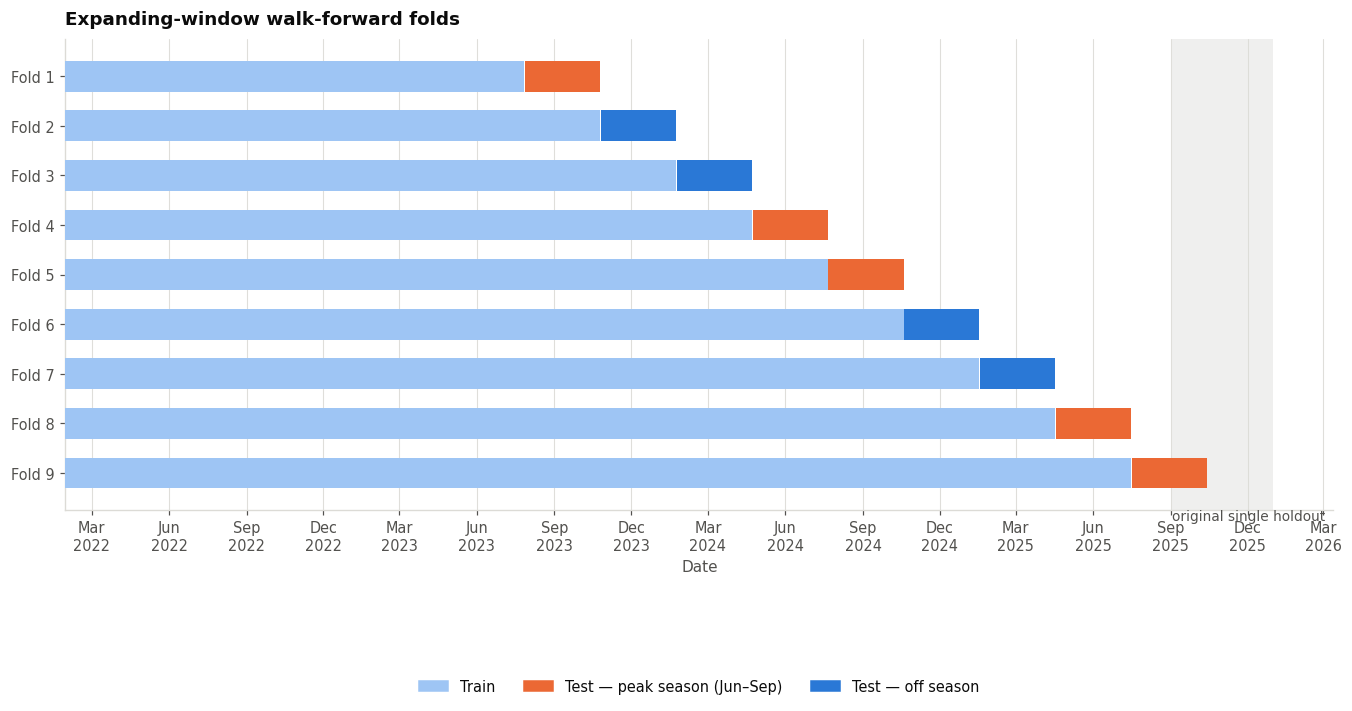

In [21]:
fig, ax = plt.subplots(figsize=(12.5, 0.52 * len(FOLDS) + 2.4))

for f in FOLDS:
    clr = PALETTE["orange"] if f.season == "Peak season" else PALETTE["blue"]
    ax.barh(f.k, (f.train_idx.max() - f.train_idx.min()).days,
            left=mdates.date2num(f.train_idx.min()), height=0.62,
            color=SEQ_BLUE[1], zorder=3)
    ax.barh(f.k, (f.test_idx.max() - f.test_idx.min()).days,
            left=mdates.date2num(f.test_idx.min()), height=0.62,
            color=clr, zorder=4)

# Reference band: the single 120-day holdout the original notebook used.
ax.axvspan(mdates.date2num(data.index[-120]), mdates.date2num(data.index[-1]),
           color=INK_MUTED, alpha=0.13, lw=0, zorder=1)
ax.text(mdates.date2num(data.index[-120]), len(FOLDS) + 0.95,
        "original single holdout", fontsize=9, color=INK_2, ha="left")

ax.set_yticks([f.k for f in FOLDS])
ax.set_yticklabels([f"Fold {f.k}" for f in FOLDS])
ax.invert_yaxis()
ax.set_xlabel("Date")
ax.set_title("Expanding-window walk-forward folds")
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.grid(axis="y", visible=False)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SEQ_BLUE[1], label="Train"),
                   Patch(color=PALETTE["orange"], label="Test — peak season (Jun–Sep)"),
                   Patch(color=PALETTE["blue"], label="Test — off season")],
          loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=3)
plt.tight_layout(); plt.show()

Read the chart against the grey band: the original evaluation is the small strip on the right.
The coloured test blocks are what we evaluate on instead — several times the number of test days,
and critically, orange blocks that land inside the summer peak season the single holdout never
touched.

One thing this design deliberately does **not** do: tune hyperparameters on these same folds and
then report the fold scores as the final result. That would be selection bias — the scores would
be optimistic because the folds were used twice. §7.3 handles tuning with an inner validation
split carved out of each fold's *training* block, keeping the test blocks untouched.

---
# 7. The models

Five models, chosen because each captures a *different kind of structure*. That is the point of
comparing them — not to crown a winner, but to learn which structure in the data actually carries
the predictive signal.

| Model | Structure it can represent | Structure it cannot |
|---|---|---|
| **Ridge regression** | Linear, additive effects | Interactions and thresholds, unless hand-built |
| **SARIMAX** | Explicit autocorrelation + weekly seasonality + linear exogenous effects | Nonlinearity of any kind |
| **XGBoost** | Arbitrary nonlinearity, interactions, thresholds | Extrapolation beyond the training range |
| **LSTM** | Learned temporal dependence over a sequence window | Anything, without enough data to learn it |
| **Ensemble** | A weighted combination whose errors partially cancel | Nothing new — it inherits its members' blind spots |

## 7.0 A common interface

Every model implements the same signature, so the cross-validation loop treats them
interchangeably and no model can accidentally get a different data contract than another:

```python
fit_predict(full_df, train_idx, test_idx) -> np.ndarray   # one prediction per test day
```

Everything a model needs — scaling, imputation, hyperparameter choice — happens **inside** this
call, using only `train_idx`. That is what keeps the fold honest.

In [22]:
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import time

MODEL_COLORS = {
    "Ridge":     PALETTE["blue"],
    "SARIMAX":   PALETTE["orange"],
    "XGBoost":   PALETTE["aqua"],
    "LSTM":      PALETTE["violet"],
    "Ensemble":  PALETTE["red"],
    "Naive (persistence)":  INK_MUTED,
    "Weather+calendar OLS": PALETTE["yellow"],
}

REGISTRY = {}          # name -> fit_predict callable

def register(name):
    def deco(fn):
        REGISTRY[name] = fn
        return fn
    return deco

print("Model registry ready. Each model registers a fit_predict(full, train_idx, test_idx).")

Model registry ready. Each model registers a fit_predict(full, train_idx, test_idx).


## 7.1 Ridge regression — the interpretable reference

**What it does.** Fits $\hat y = \beta_0 + \sum_j \beta_j x_j$, choosing $\beta$ to minimize

$$\underbrace{\sum_i (y_i - \hat y_i)^2}_{\text{fit}} \;+\; \underbrace{\alpha \sum_j \beta_j^2}_{\text{penalty}}$$

**Why Ridge and not plain OLS.** Our feature set contains groups of strongly correlated
predictors by design — `cdd`, `cdd_sq`, `cdd_lag1`, `cdd_roll3`, `cdd_roll7` all move together;
so do the several load lags. Under collinearity, OLS coefficients become unstable: the fit is
fine, but individual coefficients swing wildly between samples and can take large offsetting
values. The $L_2$ penalty shrinks coefficients toward zero, trading a little bias for a large
reduction in variance, and it spreads weight across correlated features instead of arbitrarily
picking one. That makes the coefficients *readable*, which is most of why this model is here.

**Standardization is required, not cosmetic.** The penalty $\alpha\sum\beta_j^2$ is scale-dependent:
`time_idx` runs to ~1,400 while `doy_sin` lives in $[-1, 1]$, so without standardizing, the penalty
would fall almost entirely on the small-scale features. The scaler is fit on training data only.

**Choosing $\alpha$.** Not by magic number and not by `RidgeCV` with random folds — that would
shuffle time. We sweep $\alpha$ on a time-ordered inner validation split from the tail of the
training block.

Selected alpha on fold 9: 0.1


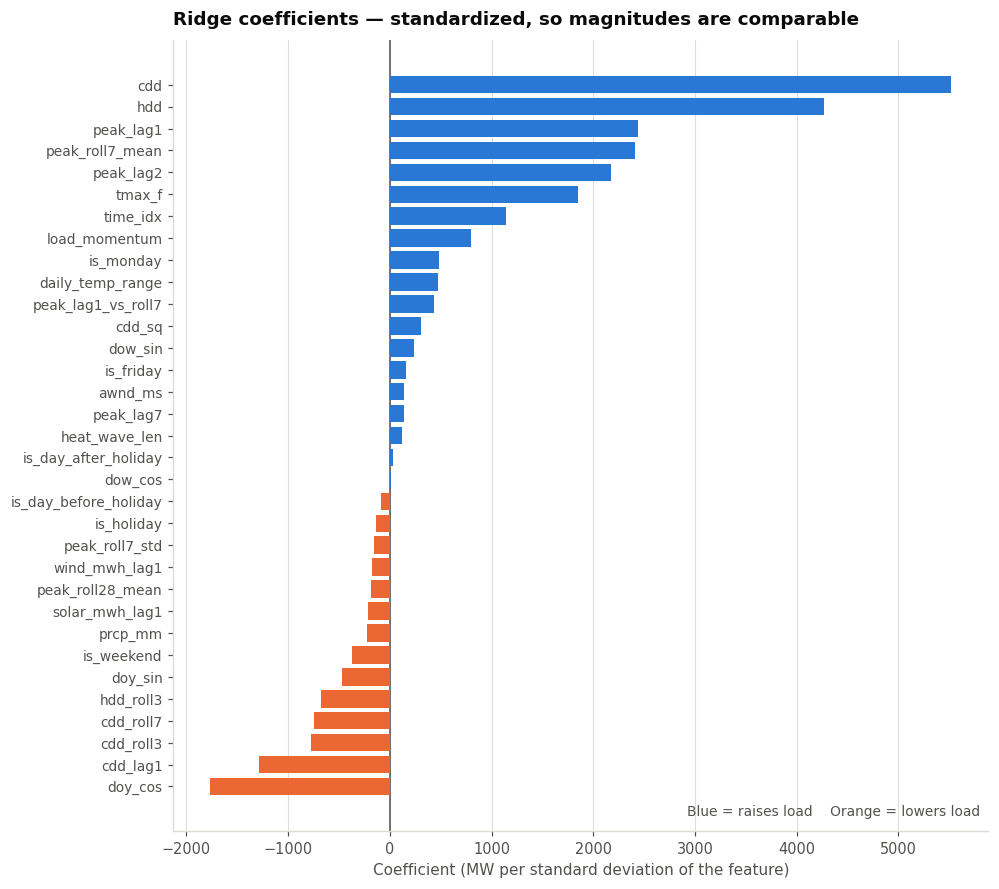


Five largest positive and negative effects (MW per 1 SD):
cdd               +5,520
hdd               +4,266
peak_lag1         +2,444
peak_roll7_mean   +2,412
peak_lag2         +2,177
   ...
doy_cos     -1,764
cdd_lag1    -1,282
cdd_roll3     -772
cdd_roll7     -751
hdd_roll3     -675

Because features are standardized, these are directly comparable: a 1-SD move
in the top feature shifts predicted peak load by the stated number of MW.


In [23]:
@register("Ridge")
def fit_predict_ridge(full, train_idx, test_idx, alphas=(0.1, 1, 10, 30, 100, 300, 1000),
                      inner_val_days=90, return_model=False):
    tr, te = full.loc[train_idx], full.loc[test_idx]

    # --- inner, time-ordered validation split for alpha selection ---
    inner_cut = len(tr) - inner_val_days
    itr, iva = tr.iloc[:inner_cut], tr.iloc[inner_cut:]
    scores = {}
    for a in alphas:
        m = make_pipeline(StandardScaler(), Ridge(alpha=a))
        m.fit(itr[FEATURES], itr[TARGET])
        scores[a] = np.mean(np.abs(iva[TARGET].values - m.predict(iva[FEATURES])))
    best_alpha = min(scores, key=scores.get)

    # --- refit on the full training block with the chosen alpha ---
    model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
    model.fit(tr[FEATURES], tr[TARGET])
    pred = model.predict(te[FEATURES])
    return (pred, model, best_alpha) if return_model else pred

# Demonstrate on the last fold and read the coefficients.
_f = FOLDS[-1]
_pred, _model, _alpha = fit_predict_ridge(data, _f.train_idx, _f.test_idx, return_model=True)
print(f"Selected alpha on fold {_f.k}: {_alpha}")

ridge_step = _model.named_steps["ridge"]
coefs = pd.Series(ridge_step.coef_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9.2, 8.2))
clrs = [PALETTE["blue"] if v > 0 else PALETTE["orange"] for v in coefs]
ax.barh(range(len(coefs)), coefs, color=clrs, zorder=3)
ax.set_yticks(range(len(coefs))); ax.set_yticklabels(coefs.index, fontsize=9)
ax.axvline(0, color=INK_2, lw=1.0)
ax.set_xlabel("Coefficient (MW per standard deviation of the feature)")
ax.set_title("Ridge coefficients — standardized, so magnitudes are comparable")
ax.text(0.99, 0.02, "Blue = raises load    Orange = lowers load", transform=ax.transAxes,
        ha="right", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("\nFive largest positive and negative effects (MW per 1 SD):")
print(coefs.tail(5).sort_values(ascending=False).to_string(float_format=lambda v: f"{v:+,.0f}"))
print("   ...")
print(coefs.head(5).to_string(float_format=lambda v: f"{v:+,.0f}"))
print("\nBecause features are standardized, these are directly comparable: a 1-SD move")
print("in the top feature shifts predicted peak load by the stated number of MW.")

## 7.2 SARIMAX — the classical time-series model

**Reading the notation.** SARIMAX$(p,d,q)\times(P,D,Q)_s$ with exogenous regressors:

| Term | Name | Meaning here |
|---|---|---|
| $p$ | AR order | How many past *values* enter directly |
| $d$ | Differencing | How many times to difference to reach stationarity — set from the ADF test in §3.5 |
| $q$ | MA order | How many past *forecast errors* enter |
| $P, D, Q$ | Seasonal counterparts | The same three, at the seasonal lag |
| $s$ | Seasonal period | **7** — the weekly cycle from §3.4, not 365 |
| $X$ | Exogenous | Degree-days and calendar flags, entering linearly |

Written out, the non-seasonal part is
$$\phi_p(B)\,(1-B)^d\, y_t = \theta_q(B)\,\varepsilon_t + \beta^\top x_t$$
where $B$ is the backshift operator, $By_t = y_{t-1}$.

**Why $s=7$ and not $s=365$.** A seasonal period of 365 would require estimating seasonal terms at
lag 365 from a record only four years long — four observations per seasonal lag. The annual cycle
is instead handled through the exogenous degree-day terms, which is both statistically efficient
and physically correct: the annual cycle *is* the weather.

**Evaluation must be walk-forward.** A model asked to forecast 90 days blind is doing a
fundamentally different and much harder task than the one-day-ahead job the other models perform.
To keep the comparison fair, we forecast day $t$, then feed day $t$'s **actual** value into the
filter state before forecasting $t+1$. Crucially, `append(..., refit=False)` updates the Kalman
filter state *without re-estimating parameters* — so no test-period information ever reaches the
coefficients. That distinction is what makes this legitimate rather than leakage.

> A practical note: maximum-likelihood estimation of a seasonal ARIMA occasionally reports
> non-convergence on a fold. The fitted parameters are still usable — the optimizer hit its
> iteration cap near a flat likelihood surface — but it is a reason to prefer the fold-averaged
> results in §8 over any single fold's number.

In [24]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

SARIMAX_EXOG = ["cdd", "hdd", "cdd_sq", "is_weekend", "is_holiday",
                "is_day_after_holiday", "time_idx"]
SARIMAX_ORDER = (2, ARIMA_D, 2)
SARIMAX_SEASONAL = (1, 1, 1, 7)

@register("SARIMAX")
def fit_predict_sarimax(full, train_idx, test_idx, return_model=False):
    tr, te = full.loc[train_idx], full.loc[test_idx]

    with warnings.catch_warnings():
        # statsmodels re-emits frequency and convergence warnings on every append();
        # they are expected here and would otherwise bury the fold progress output.
        warnings.simplefilter("ignore")
        endog = tr[TARGET].asfreq("D")
        mod = SARIMAX(endog, exog=tr[SARIMAX_EXOG].asfreq("D"),
                      order=SARIMAX_ORDER, seasonal_order=SARIMAX_SEASONAL,
                      enforce_stationarity=False, enforce_invertibility=False)
        fit = mod.fit(disp=False, maxiter=200)

    # Walk forward one day at a time. append(refit=False) advances the filter state
    # using the realized value but leaves the estimated parameters untouched.
    preds, rolling = [], fit
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i in range(len(te)):
            step_exog = te[SARIMAX_EXOG].iloc[[i]]
            preds.append(float(rolling.forecast(steps=1, exog=step_exog).iloc[0]))
            rolling = rolling.append(te[TARGET].iloc[[i]], exog=step_exog, refit=False)

    pred = np.asarray(preds)
    return (pred, fit) if return_model else pred

print(f"SARIMAX specification: {SARIMAX_ORDER} x {SARIMAX_SEASONAL}")
print(f"  d = {ARIMA_D}  (chosen by the ADF test in Section 3.5)")
print(f"  exogenous regressors: {SARIMAX_EXOG}")

t0 = time.time()
_pred_sx, _fit_sx = fit_predict_sarimax(data, FOLDS[-1].train_idx, FOLDS[-1].test_idx,
                                        return_model=True)
print(f"\nFitted on fold {FOLDS[-1].k} in {time.time() - t0:.1f}s")
print(_fit_sx.summary().tables[1])

SARIMAX specification: (2, 1, 2) x (1, 1, 1, 7)
  d = 1  (chosen by the ADF test in Section 3.5)
  exogenous regressors: ['cdd', 'hdd', 'cdd_sq', 'is_weekend', 'is_holiday', 'is_day_after_holiday', 'time_idx']



Fitted on fold 9 in 15.4s
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
cdd                    374.2894     90.987      4.114      0.000     195.959     552.620
hdd                    401.0804     40.035     10.018      0.000     322.613     479.548
cdd_sq                   9.8976      3.677      2.692      0.007       2.690      17.105
is_weekend              -0.0013   4095.251  -3.21e-07      1.000   -8026.546    8026.544
is_holiday            -871.0696    774.371     -1.125      0.261   -2388.809     646.670
is_day_after_holiday   128.2137    742.801      0.173      0.863   -1327.650    1584.077
time_idx                 0.0422    270.979      0.000      1.000    -531.068     531.152
ar.L1                    1.6050      0.066     24.257      0.000       1.475       1.735
ar.L2                   -0.6336      0.050    -12.768      0.000      -0.731      -

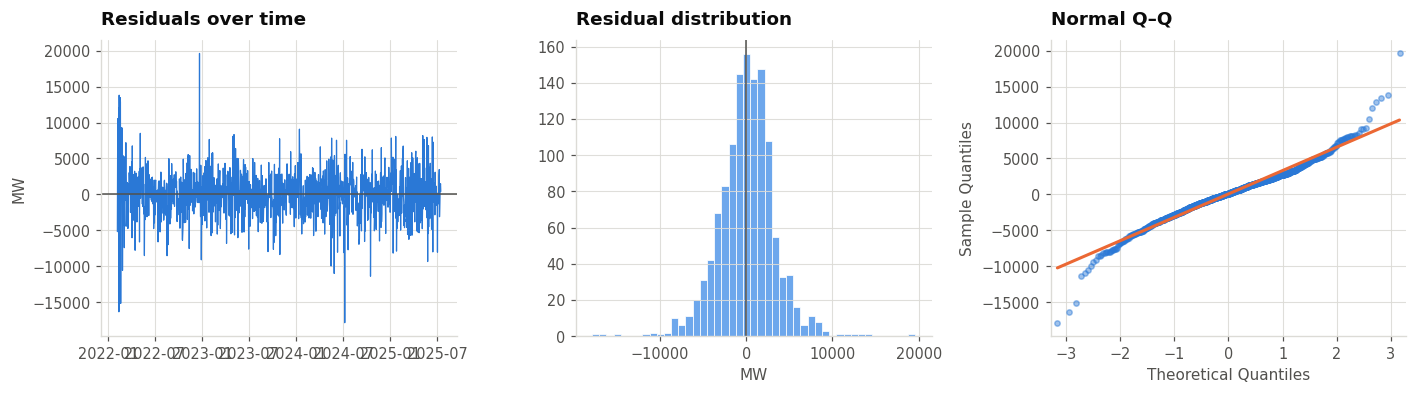

Ljung–Box test (H0: residuals are uncorrelated up to the stated lag)


,lb_stat,lb_pvalue
7,6.43,0.4903
14,9.33,0.8092
28,18.67,0.9079


Smallest p-value: 0.4903
p < 0.05 means structure remains in the residuals — the model has not captured
everything. On a weather-driven series that is expected: the leftover structure is
largely nonlinear temperature response, which is precisely what XGBoost goes after next.

The Q–Q plot matters for Section 10: heavy tails there mean a Gaussian prediction
interval would be too narrow, which is why we use a distribution-free method instead.


In [25]:
# Residual diagnostics: for a well-specified ARIMA the residuals should be white noise.
# The Ljung-Box test asks whether residual autocorrelation up to lag h is jointly zero.
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = pd.Series(_fit_sx.resid).iloc[max(SARIMAX_ORDER[1], 8):]   # drop differencing burn-in
lb = acorr_ljungbox(resid, lags=[7, 14, 28], return_df=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

axes[0].plot(resid.index, resid, lw=0.8, color=PALETTE["blue"])
axes[0].axhline(0, color=INK_2, lw=1.0)
axes[0].set_title("Residuals over time"); axes[0].set_ylabel("MW")

axes[1].hist(resid, bins=45, color=SEQ_BLUE[2], edgecolor="white", linewidth=0.5)
axes[1].axvline(0, color=INK_2, lw=1.0)
axes[1].set_title("Residual distribution"); axes[1].set_xlabel("MW")

from statsmodels.graphics.gofplots import qqplot
qqplot(resid.values, line="s", ax=axes[2], markerfacecolor=PALETTE["blue"],
       markeredgecolor=PALETTE["blue"], alpha=0.45, markersize=3.5)
axes[2].get_lines()[1].set_color(PALETTE["orange"]); axes[2].get_lines()[1].set_linewidth(2.0)
axes[2].set_title("Normal Q–Q")
plt.tight_layout(); plt.show()

print("Ljung–Box test (H0: residuals are uncorrelated up to the stated lag)")
display(lb.style.format({"lb_stat": "{:.2f}", "lb_pvalue": "{:.4f}"}))
worst_p = lb["lb_pvalue"].min()
print(f"Smallest p-value: {worst_p:.4f}")
print("p < 0.05 means structure remains in the residuals — the model has not captured")
print("everything. On a weather-driven series that is expected: the leftover structure is")
print("largely nonlinear temperature response, which is precisely what XGBoost goes after next.")
print("\nThe Q–Q plot matters for Section 10: heavy tails there mean a Gaussian prediction")
print("interval would be too narrow, which is why we use a distribution-free method instead.")

## 7.3 Gradient-boosted trees — nonlinearity and interactions

**What boosting does.** Build an additive model one small tree at a time, each new tree fit to
the *gradient of the loss* with respect to the current prediction — for squared error, that is
simply the residual:

$$F_0(x) = \bar y, \qquad F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$$

where $h_m$ is a shallow tree fit to the current errors and $\eta$ is the learning rate. Many
weak, heavily-regularized learners in sequence beat one deep tree.

**Why this is the natural model for load.** Two properties of the data map directly onto what
trees do well:

- **Thresholds.** The balance point in §3.2 is literally a split point. A tree finds it for free.
- **Interactions.** Temperature matters differently on a Sunday than on a Tuesday; a heat wave
  matters differently in August than in April. Trees represent this as nested splits, whereas a
  linear model needs every interaction hand-specified.

**The one thing trees cannot do, and why it matters here.** A tree predicts by averaging training
targets in a leaf, so its output is bounded by the range of the training data. It **cannot
extrapolate**. Given `time_idx` — a feature that only ever increases — the model will simply flatten
at the largest value it saw in training. Combined with the structural growth found in §3.6, that is
a real bias toward under-forecasting the future, which is the expensive direction. We check for it
explicitly in the bias column of §8 rather than hoping it away.

**Tuning without contaminating the folds.** Hyperparameters are chosen on an inner validation
split taken from the *tail of each fold's training block*, with early stopping on that same split.
The fold's test block is never touched during selection.

In [26]:
from xgboost import XGBRegressor

XGB_GRID = [
    dict(max_depth=3, learning_rate=0.05, min_child_weight=3,  subsample=0.8, colsample_bytree=0.8),
    dict(max_depth=4, learning_rate=0.03, min_child_weight=5,  subsample=0.8, colsample_bytree=0.8),
    dict(max_depth=5, learning_rate=0.03, min_child_weight=10, subsample=0.7, colsample_bytree=0.7),
    dict(max_depth=6, learning_rate=0.02, min_child_weight=15, subsample=0.7, colsample_bytree=0.6),
]

def _xgb(params, **kw):
    return XGBRegressor(n_estimators=2000, objective="reg:squarederror",
                        reg_lambda=1.5, random_state=RANDOM_SEED, n_jobs=4,
                        early_stopping_rounds=60, eval_metric="mae", **params, **kw)

@register("XGBoost")
def fit_predict_xgb(full, train_idx, test_idx, inner_val_days=120, return_model=False):
    tr, te = full.loc[train_idx], full.loc[test_idx]
    cut = len(tr) - inner_val_days
    itr, iva = tr.iloc[:cut], tr.iloc[cut:]

    best, best_mae, best_rounds = None, np.inf, 0
    for params in XGB_GRID:
        m = _xgb(params)
        m.fit(itr[FEATURES], itr[TARGET],
              eval_set=[(iva[FEATURES], iva[TARGET])], verbose=False)
        mae = np.mean(np.abs(iva[TARGET].values - m.predict(iva[FEATURES])))
        if mae < best_mae:
            best, best_mae, best_rounds = params, mae, m.best_iteration + 1

    # Refit on the full training block for the number of rounds the inner split chose.
    final = XGBRegressor(n_estimators=max(best_rounds, 50), objective="reg:squarederror",
                         reg_lambda=1.5, random_state=RANDOM_SEED, n_jobs=4, **best)
    final.fit(tr[FEATURES], tr[TARGET], verbose=False)
    pred = final.predict(te[FEATURES])
    return (pred, final, best, best_rounds) if return_model else pred

t0 = time.time()
_pred_xgb, _xgb_model, _xgb_params, _xgb_rounds = fit_predict_xgb(
    data, FOLDS[-1].train_idx, FOLDS[-1].test_idx, return_model=True)
print(f"Tuned and fitted on fold {FOLDS[-1].k} in {time.time() - t0:.1f}s")
print(f"  selected params : {_xgb_params}")
print(f"  boosting rounds : {_xgb_rounds}  (chosen by early stopping on the inner split)")

# The extrapolation hazard, made concrete.
tr_last = data.loc[FOLDS[-1].train_idx, "time_idx"].max()
te_range = data.loc[FOLDS[-1].test_idx, "time_idx"]
print(f"\nExtrapolation check on time_idx:")
print(f"  largest value seen in training : {tr_last:,.0f}")
print(f"  test range                     : {te_range.min():,.0f} – {te_range.max():,.0f}")
print(f"  -> every test day lies beyond the training range, so the tree's trend")
print(f"     contribution is frozen at its last training value. Watch the Bias column.")

Tuned and fitted on fold 9 in 2.6s
  selected params : {'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8}
  boosting rounds : 343  (chosen by early stopping on the inner split)

Extrapolation check on time_idx:
  largest value seen in training : 1,292
  test range                     : 1,293 – 1,382
  -> every test day lies beyond the training range, so the tree's trend
     contribution is frozen at its last training value. Watch the Bias column.


## 7.4 LSTM — a sequence model, and an honest look at why it struggles

**What an LSTM is.** A recurrent network that maintains a **cell state** $c_t$ carried forward
through time, with three learned gates deciding what to do with it at each step:

$$f_t = \sigma(W_f[h_{t-1}, x_t] + b_f) \quad \text{(forget: what to discard)}$$
$$i_t = \sigma(W_i[h_{t-1}, x_t] + b_i) \quad \text{(input: what to store)}$$
$$o_t = \sigma(W_o[h_{t-1}, x_t] + b_o) \quad \text{(output: what to expose)}$$
$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t)$$

The additive path through $c_t$ is the design's whole point: gradients flow backward through many
steps without vanishing, which is what plain RNNs cannot do.

**What we changed from the original implementation.** The original LSTM here scored roughly 2.5×
worse than the other models, and the reasons were mechanical rather than fundamental:

| Problem | Consequence | Fix applied |
|---|---|---|
| Trained a fixed 60 epochs with no validation | No way to know whether it stopped at the right time | Held-out inner validation + **early stopping** on it |
| Scalers fit on the full series | Test-period statistics leaked into training | Scalers fit **inside the fold**, on training rows only |
| No gradient clipping | Recurrent nets are prone to exploding gradients | `clip_grad_norm_` |
| Single random initialization | A bad seed is indistinguishable from a bad model | Average over several seeds |
| Fixed learning rate | Late training oscillates around the minimum | Plateau-based LR reduction |

**The honest expectation.** Even with all of that, this model is working with roughly 1,400 daily
observations. Recurrent networks generally need one to two orders of magnitude more data before
their flexibility pays for its variance. We include it, fix it properly, and then let §8 report
whatever it actually achieves — a fairly-implemented model that loses is a more useful result than
a hobbled one that loses for the wrong reason.

Trained 3 seeds on fold 9 in 39.6s


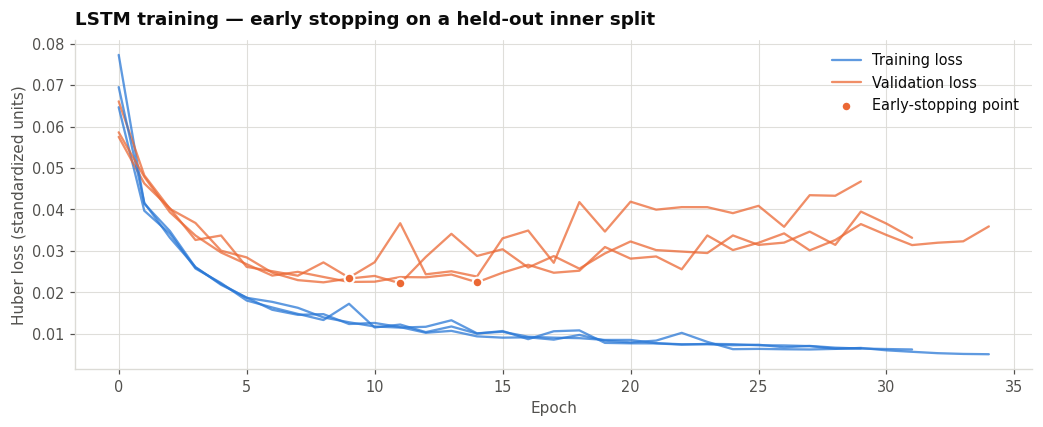

Best epoch per seed: [10, 12, 15]   (the original fixed 60 epochs would have overshot)
Seed-to-seed spread in best validation loss: 0.00060
A visible spread across seeds is itself the diagnosis: with this much data the
network's variance is large relative to whatever signal it adds.


In [27]:
import torch
import torch.nn as nn

torch.set_num_threads(4)
SEQ_LEN = 14
LSTM_SEEDS = (0, 1, 2)

class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden=48, dropout=0.15):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=1, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 24),
                                  nn.ReLU(), nn.Linear(24, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

def _make_sequences(X, y, positions, seq_len):
    """Sequence ending at position i uses rows [i-seq_len, i) plus row i's own features."""
    xs = np.stack([X[i - seq_len + 1:i + 1] for i in positions])
    ys = y[positions]
    return torch.tensor(xs, dtype=torch.float32), torch.tensor(ys, dtype=torch.float32)

@register("LSTM")
def fit_predict_lstm(full, train_idx, test_idx, seq_len=SEQ_LEN, inner_val_days=120,
                     max_epochs=150, patience=20, seeds=LSTM_SEEDS, return_history=False):
    pos = {ts: i for i, ts in enumerate(full.index)}
    tr_pos = np.array([pos[t] for t in train_idx])
    te_pos = np.array([pos[t] for t in test_idx])

    # Scalers fit on the fold's TRAINING rows only.
    sx = StandardScaler().fit(full.iloc[tr_pos][FEATURES])
    sy = StandardScaler().fit(full.iloc[tr_pos][[TARGET]])
    Xs = sx.transform(full[FEATURES]).astype(np.float32)
    ys = sy.transform(full[[TARGET]]).astype(np.float32).ravel()

    usable_tr = tr_pos[tr_pos >= seq_len - 1]
    cut = len(usable_tr) - inner_val_days
    fit_pos, val_pos = usable_tr[:cut], usable_tr[cut:]

    Xf, yf = _make_sequences(Xs, ys, fit_pos, seq_len)
    Xv, yv = _make_sequences(Xs, ys, val_pos, seq_len)
    Xt, _  = _make_sequences(Xs, ys, te_pos, seq_len)

    preds_all, histories = [], []
    for seed in seeds:
        torch.manual_seed(seed); np.random.seed(seed)
        model = LSTMForecaster(len(FEATURES))
        opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
        lossf = nn.SmoothL1Loss()          # Huber: less sensitive to outlier days than MSE

        best_val, best_state, bad, hist = np.inf, None, 0, []
        n, bs = len(Xf), 32
        for epoch in range(max_epochs):
            model.train()
            perm = torch.randperm(n)
            for b in range(0, n, bs):
                idx = perm[b:b + bs]
                opt.zero_grad()
                loss = lossf(model(Xf[idx]), yf[idx])
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # exploding-gradient guard
                opt.step()
            model.eval()
            with torch.no_grad():
                vl = float(lossf(model(Xv), yv))
                tl = float(lossf(model(Xf), yf))
            hist.append((tl, vl)); sched.step(vl)
            if vl < best_val - 1e-5:
                best_val, best_state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
            else:
                bad += 1
                if bad >= patience: break
        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            preds_all.append(model(Xt).numpy())
        histories.append(hist)

    pred_scaled = np.mean(preds_all, axis=0)          # seed-averaged
    pred = sy.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    return (pred, histories) if return_history else pred

t0 = time.time()
_pred_lstm, _hist = fit_predict_lstm(data, FOLDS[-1].train_idx, FOLDS[-1].test_idx,
                                     return_history=True)
print(f"Trained {len(LSTM_SEEDS)} seeds on fold {FOLDS[-1].k} in {time.time() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(9.6, 4.0))
for i, hist in enumerate(_hist):
    tl = [h[0] for h in hist]; vl = [h[1] for h in hist]
    ax.plot(tl, color=PALETTE["blue"], lw=1.5, alpha=0.75,
            label="Training loss" if i == 0 else None)
    ax.plot(vl, color=PALETTE["orange"], lw=1.5, alpha=0.75,
            label="Validation loss" if i == 0 else None)
    ax.scatter([int(np.argmin(vl))], [min(vl)], s=40, color=PALETTE["orange"],
               edgecolor="white", linewidth=1.4, zorder=5,
               label="Early-stopping point" if i == 0 else None)
ax.set_xlabel("Epoch"); ax.set_ylabel("Huber loss (standardized units)")
ax.set_title("LSTM training — early stopping on a held-out inner split")
ax.legend()
plt.tight_layout(); plt.show()

stops = [int(np.argmin([h[1] for h in hist])) + 1 for hist in _hist]
print(f"Best epoch per seed: {stops}   (the original fixed 60 epochs would "
      f"{'have overshot' if np.mean(stops) < 60 else 'have stopped short'})")
print(f"Seed-to-seed spread in best validation loss: "
      f"{np.std([min(h[1] for h in hist) for hist in _hist]):.5f}")
print("A visible spread across seeds is itself the diagnosis: with this much data the")
print("network's variance is large relative to whatever signal it adds.")

## 7.5 Ensemble — combining models without cheating

Averaging models helps when their **errors are imperfectly correlated**: a linear model and a tree
model fail on different days, so a blend cancels part of each one's error. This is not a trick; it
is why operational forecasting groups almost always run a combination rather than a single model.

The hard part is choosing the weights honestly. Fitting weights on the test period is blatant
leakage. Fitting them on the training period is subtler but still wrong, because the base models
fit that same data and their in-sample residuals understate their true error.

**Our approach: weights come from the previous fold.** For fold $k$, we fit the blend weights on
fold $k{-}1$'s *test* predictions — data that was out-of-sample for every base model when those
predictions were made, and that lies entirely in fold $k$'s past. Fold 1 has no predecessor and
uses equal weights.

This mirrors production practice, where a forecaster reweights the ensemble based on how each
model performed last month. Weights are constrained to be non-negative and to sum to one, so the
blend stays a genuine interpolation and remains interpretable.

In [28]:
from scipy.optimize import nnls

BASE_MODELS = ["Ridge", "SARIMAX", "XGBoost", "LSTM"]

def solve_blend_weights(pred_matrix: np.ndarray, y_true: np.ndarray) -> np.ndarray:
    """Non-negative least squares, renormalized to sum to 1.

    Constraining weights to the simplex keeps the blend an interpolation of its
    members (no extrapolation, no offsetting large +/- weights) and keeps them
    readable as 'share of the forecast'.
    """
    w, _ = nnls(pred_matrix, y_true)
    return np.ones(pred_matrix.shape[1]) / pred_matrix.shape[1] if w.sum() <= 1e-9 else w / w.sum()

print("Ensemble weighting: non-negative least squares on the PREVIOUS fold's")
print("out-of-sample predictions, renormalized to the simplex.")
print(f"Base models: {BASE_MODELS}")
print("Fold 1 has no predecessor and therefore uses equal weights.")

Ensemble weighting: non-negative least squares on the PREVIOUS fold's
out-of-sample predictions, renormalized to the simplex.
Base models: ['Ridge', 'SARIMAX', 'XGBoost', 'LSTM']
Fold 1 has no predecessor and therefore uses equal weights.


## 7.6 Running the cross-validation

Everything now runs through one loop. For each fold we fit each base model, record its
predictions, form the ensemble from the previous fold's weights, and score everything with the
metric suite from §5.1. The baselines from §5.2 ride along so they appear in every comparison.

In [29]:
RUN_CV = True     # set False to skip the ~5-10 minute run and reuse a cached result

def run_cross_validation(folds, registry, base_models=BASE_MODELS):
    preds_by_fold, weights_by_fold, rows, timings = {}, {}, [], {}
    prev_matrix, prev_actual = None, None

    for f in folds:
        y_true = data.loc[f.test_idx, TARGET].values
        fold_preds = {}

        for name in base_models:
            t0 = time.time()
            fold_preds[name] = np.asarray(registry[name](data, f.train_idx, f.test_idx), float)
            timings[name] = timings.get(name, 0.0) + (time.time() - t0)

        # --- ensemble from the PREVIOUS fold's out-of-sample predictions ---
        if prev_matrix is None:
            w = np.ones(len(base_models)) / len(base_models)
        else:
            w = solve_blend_weights(prev_matrix, prev_actual)
        weights_by_fold[f.k] = dict(zip(base_models, w))
        fold_preds["Ensemble"] = np.column_stack([fold_preds[m] for m in base_models]) @ w

        # --- baselines ---
        fold_preds.update(make_baselines(data.loc[f.train_idx], data.loc[f.test_idx]))

        for name, p in fold_preds.items():
            r = evaluate(y_true, p, name, index=f.test_idx, verbose=False)
            r.update(fold=f.k, season=f.season,
                     test_start=f.test_idx.min(), test_end=f.test_idx.max())
            rows.append(r)

        preds_by_fold[f.k] = {"index": f.test_idx, "actual": y_true, **fold_preds}
        prev_matrix = np.column_stack([fold_preds[m] for m in base_models])
        prev_actual = y_true

        best = min(base_models + ["Ensemble"],
                   key=lambda m: np.mean(np.abs(y_true - fold_preds[m])))
        print(f"  fold {f.k} ({f.season:<11s}) {f.test_idx.min():%Y-%m-%d} → "
              f"{f.test_idx.max():%Y-%m-%d}   best: {best}")

    return pd.DataFrame(rows), preds_by_fold, weights_by_fold, timings

if RUN_CV:
    print(f"Running {len(FOLDS)} folds x {len(BASE_MODELS)} base models "
          f"+ ensemble + {len(make_baselines(data.iloc[:100], data.iloc[100:110]))} baselines\n")
    t0 = time.time()
    cv_results, cv_preds, cv_weights, cv_timings = run_cross_validation(FOLDS, REGISTRY)
    print(f"\nCompleted in {time.time() - t0:.0f}s")
    print("\nCumulative fit+predict time by model:")
    for k, v in sorted(cv_timings.items(), key=lambda kv: -kv[1]):
        print(f"   {k:<10s} {v:7.1f}s   ({v/len(FOLDS):5.1f}s per fold)")

Running 9 folds x 4 base models + ensemble + 4 baselines



  fold 1 (Peak season) 2023-07-28 → 2023-10-25   best: Ridge


  fold 2 (Off season ) 2023-10-26 → 2024-01-23   best: XGBoost


  fold 3 (Off season ) 2024-01-24 → 2024-04-22   best: Ensemble


  fold 4 (Peak season) 2024-04-23 → 2024-07-21   best: XGBoost


  fold 5 (Peak season) 2024-07-22 → 2024-10-19   best: Ridge


  fold 6 (Off season ) 2024-10-20 → 2025-01-17   best: Ensemble


  fold 7 (Off season ) 2025-01-18 → 2025-04-17   best: LSTM


  fold 8 (Peak season) 2025-04-18 → 2025-07-16   best: XGBoost


  fold 9 (Peak season) 2025-07-17 → 2025-10-14   best: LSTM

Completed in 451s

Cumulative fit+predict time by model:
   LSTM         344.1s   ( 38.2s per fold)
   SARIMAX       89.1s   (  9.9s per fold)
   XGBoost       17.5s   (  1.9s per fold)
   Ridge          0.6s   (  0.1s per fold)


ENSEMBLE WEIGHTS (from the previous fold's out-of-sample errors)


,Ridge,SARIMAX,XGBoost,LSTM
fold,,,,
1,0.250,0.250,0.250,0.250
2,0.853,0.001,0.146,0.000
3,0.121,0.334,0.247,0.297
4,0.000,0.274,0.477,0.250
5,0.000,0.000,1.000,0.000
6,0.383,0.000,0.617,0.000
7,0.034,0.040,0.567,0.359
8,0.000,0.022,0.199,0.779
9,0.291,0.000,0.486,0.223


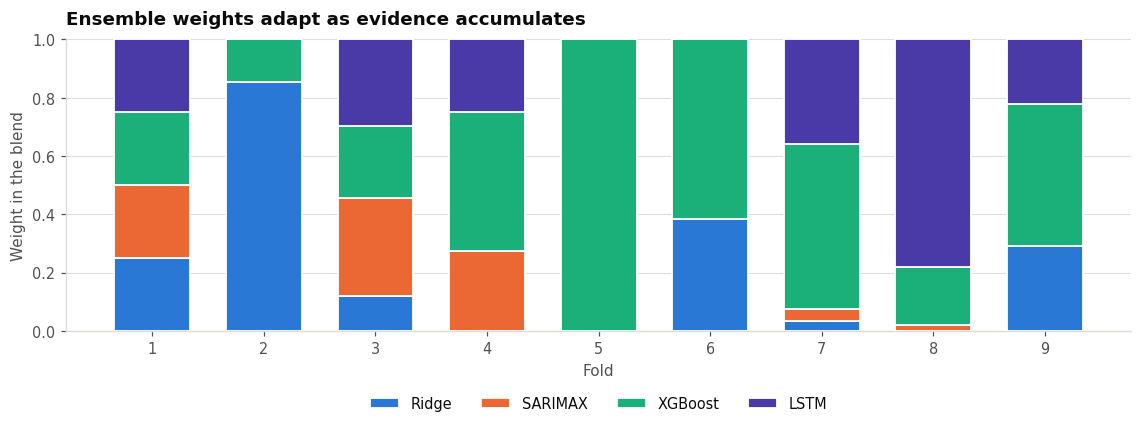


Mean weight across folds:
   Ridge      0.215
   SARIMAX    0.102
   XGBoost    0.443
   LSTM       0.240

A model whose weight collapses toward zero is one the blend has learned it can
do without — a cleaner verdict than any single accuracy table.


In [30]:
# Ensemble weights actually chosen, fold by fold.
wdf = pd.DataFrame(cv_weights).T
wdf.index.name = "fold"
print("ENSEMBLE WEIGHTS (from the previous fold's out-of-sample errors)")
display(wdf.style.format("{:.3f}").background_gradient(cmap="Blues", axis=1))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
bottom = np.zeros(len(wdf))
for i, m in enumerate(BASE_MODELS):
    ax.bar(wdf.index, wdf[m], bottom=bottom, color=MODEL_COLORS[m], label=m,
           width=0.68, zorder=3, edgecolor="white", linewidth=1.2)
    bottom += wdf[m].values
ax.set_xlabel("Fold"); ax.set_ylabel("Weight in the blend")
ax.set_title("Ensemble weights adapt as evidence accumulates")
ax.set_xticks(wdf.index); ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=4)
plt.tight_layout(); plt.show()

print("\nMean weight across folds:")
for m in BASE_MODELS:
    print(f"   {m:<10s} {wdf[m].mean():.3f}")
print("\nA model whose weight collapses toward zero is one the blend has learned it can")
print("do without — a cleaner verdict than any single accuracy table.")

---
# 8. Results

## 8.1 The headline table

Averaged across all folds. Read it in this order:

1. **MAE** — typical error.
2. **PeakSeasonMAE** — error when the grid is actually tight. This is the number that matters.
3. **Bias** — sign and size of systematic error. Negative means the model **under**-forecasts,
   which is the expensive direction.
4. **Under2GW_%** — how often the forecast fell short by more than 2 GW.
5. **The standard deviation across folds** (next section) — whether the ranking is stable or noise.

In [31]:
MODEL_ORDER = ["Naive (persistence)", "Seasonal naive (t-7)", "Drift-adjusted naive",
               "Weather+calendar OLS", "Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"]

summary = (cv_results.groupby("model")[METRIC_COLS].mean()
           .reindex([m for m in MODEL_ORDER if m in cv_results["model"].unique()]))
summary["MAE_sd_across_folds"] = cv_results.groupby("model")["MAE"].std().reindex(summary.index)

best_baseline_mae = summary.loc[
    [m for m in summary.index if m in ("Naive (persistence)", "Seasonal naive (t-7)",
                                       "Drift-adjusted naive", "Weather+calendar OLS")], "MAE"].min()
summary["Skill_vs_best_baseline_%"] = (1 - summary["MAE"] / best_baseline_mae) * 100

print("CROSS-VALIDATED PERFORMANCE — mean across all folds")
print("=" * 100)
display(
    summary.style
    .format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE_%": "{:.2f}", "Bias": "{:+,.0f}",
             "P95_AbsErr": "{:,.0f}", "MaxAbsErr": "{:,.0f}", "Under2GW_%": "{:.1f}",
             "R2": "{:.4f}", "PeakSeasonMAE": "{:,.0f}", "OffPeakMAE": "{:,.0f}",
             "MAE_sd_across_folds": "{:,.0f}", "Skill_vs_best_baseline_%": "{:+.1f}"})
    .background_gradient(cmap="Blues_r", subset=["MAE", "RMSE", "PeakSeasonMAE"])
)

winner = summary.loc[["Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"], "MAE"].idxmin()
peak_winner = summary.loc[["Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"], "PeakSeasonMAE"].idxmin()
print(f"\nLowest overall MAE      : {winner}  ({summary.loc[winner, 'MAE']:,.0f} MW)")
print(f"Lowest peak-season MAE  : {peak_winner}  ({summary.loc[peak_winner, 'PeakSeasonMAE']:,.0f} MW)")
skill = summary.loc[winner, "Skill_vs_best_baseline_%"]
best_bl_name = summary.loc[[m for m in summary.index if m in (
    "Naive (persistence)", "Seasonal naive (t-7)", "Drift-adjusted naive",
    "Weather+calendar OLS")], "MAE"].idxmin()
print(f"Strongest baseline      : {best_bl_name}  ({best_baseline_mae:,.0f} MW)")
print(f"Skill vs. that baseline : {skill:+.1f}%")
if skill <= 0:
    print(f"\n   NOTE: the best learned model does NOT beat the strongest baseline here.")
    print(f"   That is a real result, not a bug, and it is why Section 5.2 insisted on")
    print(f"   computing baselines rather than assuming they are easy to beat. When a")
    print(f"   well-specified linear weather+calendar regression matches a gradient-boosted")
    print(f"   ensemble, the honest conclusion is that the load-temperature relationship is")
    print(f"   close to linear once degree-days are constructed properly (Section 3.2) —")
    print(f"   and the simpler model should be preferred on interpretability and runtime.")
else:
    print(f"   -> {skill:.1f}% MAE reduction over the strongest baseline.")
if winner != peak_winner:
    print(f"\nNote that the overall winner and the peak-season winner DIFFER. Selecting on")
    print(f"overall MAE alone would pick {winner} when {peak_winner} is better on the days")
    print(f"the grid is tight — exactly the failure mode Section 5.1 warned about.")

print("\nBias direction (negative = under-forecasts, the expensive direction):")
for m in ["Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"]:
    b = summary.loc[m, "Bias"]
    print(f"   {m:<10s} {b:+7,.0f} MW   {'UNDER-forecasts' if b < 0 else 'over-forecasts'}")

CROSS-VALIDATED PERFORMANCE — mean across all folds


,MAE,RMSE,MAPE_%,Bias,P95_AbsErr,MaxAbsErr,Under2GW_%,R2,PeakSeasonMAE,OffPeakMAE,MAE_sd_across_folds,Skill_vs_best_baseline_%
model,,,,,,,,,,,,
Naive (persistence),"2,761","3,882",4.59,+13,"7,616","14,636",26.5,0.6482,"2,278","3,146",547,+0.0
Seasonal naive (t-7),"5,590","7,556",9.10,+78,"15,650","23,673",35.6,-0.2760,"5,167","5,927","1,420",-102.4
Drift-adjusted naive,"2,793","3,897",4.64,-89,"7,497","14,672",28.0,0.6456,"2,304","3,175",542,-1.2
Weather+calendar OLS,"3,215","3,984",5.13,-513,"7,247","10,781",36.4,0.5997,"3,206","3,601",550,-16.4
Ridge,"2,161","2,797",3.58,+164,"5,284","8,836",21.5,0.8093,"2,028","2,196",262,+21.7
SARIMAX,"2,367","3,097",3.90,+64,"6,081","9,526",24.3,0.7765,"2,184","2,464",368,+14.3
XGBoost,"2,148","2,789",3.40,-615,"5,348","9,096",28.8,0.8237,"2,407","1,926",295,+22.2
LSTM,"2,445","3,146",3.87,-260,"6,056","10,227",27.0,0.7831,"2,898","2,404",667,+11.4
Ensemble,"2,082","2,666",3.33,-446,"5,100","8,344",28.0,0.8393,"2,380","1,930",396,+24.6



Lowest overall MAE      : Ensemble  (2,082 MW)
Lowest peak-season MAE  : Ridge  (2,028 MW)
Strongest baseline      : Naive (persistence)  (2,761 MW)
Skill vs. that baseline : +24.6%
   -> 24.6% MAE reduction over the strongest baseline.

Note that the overall winner and the peak-season winner DIFFER. Selecting on
overall MAE alone would pick Ensemble when Ridge is better on the days
the grid is tight — exactly the failure mode Section 5.1 warned about.

Bias direction (negative = under-forecasts, the expensive direction):
   Ridge         +164 MW   over-forecasts
   SARIMAX        +64 MW   over-forecasts
   XGBoost       -615 MW   UNDER-forecasts
   LSTM          -260 MW   UNDER-forecasts
   Ensemble      -446 MW   UNDER-forecasts


## 8.2 Stability across folds — is the ranking real?

A mean hides everything that matters about reliability. This is where a single-holdout evaluation
gives a false sense of precision: with one fold you get one number and no way to know whether a
200 MW gap between two models is signal or noise.

The chart below shows every fold's MAE for every model. What you want to see in a model you would
actually deploy is a **low and tight** distribution — not just a low average.

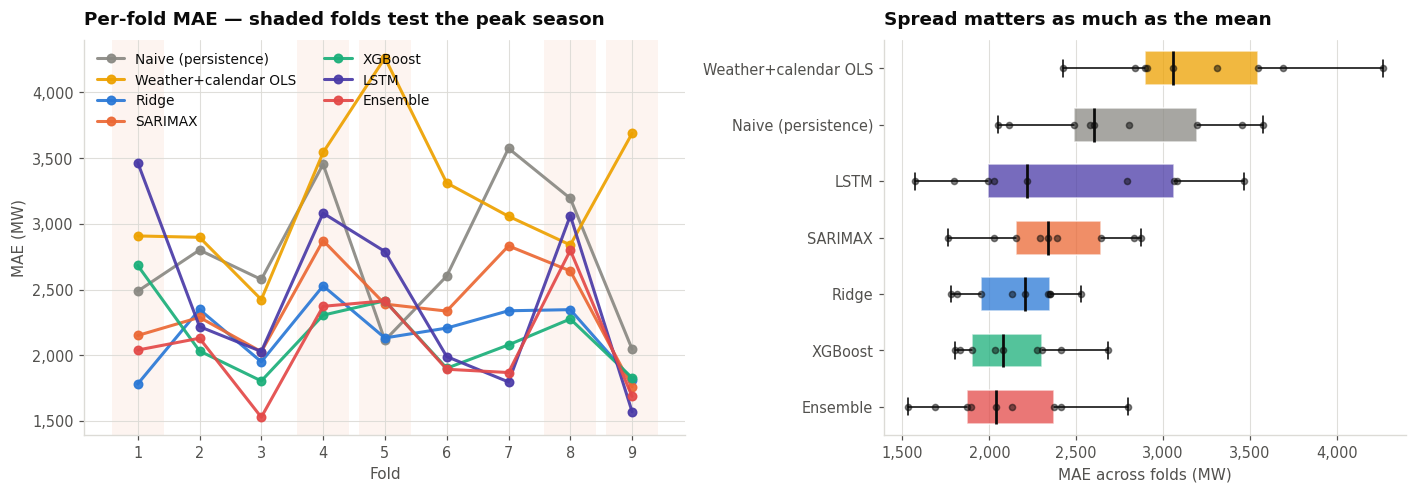

Fold-to-fold stability of MAE


,mean,std,min,max,range,cv_%
model,,,,,,
Ensemble,"2,082",396,"1,529","2,799","1,270",19.0
XGBoost,"2,148",295,"1,805","2,684",879,13.7
Ridge,"2,161",262,"1,782","2,528",746,12.1
SARIMAX,"2,367",368,"1,761","2,873","1,112",15.6
LSTM,"2,445",667,"1,571","3,466","1,895",27.3
Naive (persistence),"2,761",547,"2,047","3,574","1,527",19.8
Weather+calendar OLS,"3,215",550,"2,424","4,263","1,838",17.1



Gap between the top two models      : 66 MW
Fold-to-fold SD of the leader's MAE : 396 MW
-> The gap is SMALLER than the fold-to-fold
   variation, which is why Section 8.3 tests the difference formally instead of
   declaring a winner from the table.


In [32]:
models_to_plot = ["Naive (persistence)", "Weather+calendar OLS", "Ridge", "SARIMAX",
                  "XGBoost", "LSTM", "Ensemble"]
sub = cv_results[cv_results["model"].isin(models_to_plot)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})

# --- Left: per-fold MAE, one line per model -----------------------------------
axL = axes[0]
for m in models_to_plot:
    s = sub[sub["model"] == m].sort_values("fold")
    axL.plot(s["fold"], s["MAE"], marker="o", markersize=5.5, lw=2.0,
             color=MODEL_COLORS[m], label=m, alpha=0.92)
for f in FOLDS:
    if f.season == "Peak season":
        axL.axvspan(f.k - 0.42, f.k + 0.42, color=PALETTE["orange"], alpha=0.07, lw=0, zorder=0)
axL.set_xlabel("Fold"); axL.set_ylabel("MAE (MW)")
axL.set_title("Per-fold MAE — shaded folds test the peak season")
axL.set_xticks(sorted(sub["fold"].unique()))
thousands(axL)
axL.legend(loc="upper left", ncol=2, fontsize=9)

# --- Right: distribution of fold MAEs -----------------------------------------
axR = axes[1]
order = summary.reindex(models_to_plot)["MAE"].sort_values().index.tolist()
bp = axR.boxplot([sub[sub["model"] == m]["MAE"].values for m in order],
                 vert=False, patch_artist=True, widths=0.6,
                 medianprops=dict(color=INK, linewidth=1.8),
                 flierprops=dict(marker="o", markersize=4, markerfacecolor=INK_MUTED,
                                 markeredgecolor="none"))
for patch, m in zip(bp["boxes"], order):
    patch.set_facecolor(MODEL_COLORS[m]); patch.set_alpha(0.75); patch.set_edgecolor("white")
for i, m in enumerate(order, start=1):
    axR.scatter(sub[sub["model"] == m]["MAE"], np.full(len(sub[sub["model"] == m]), i),
                s=16, color=INK, alpha=0.5, zorder=5)
axR.set_yticklabels(order, fontsize=9.5)
axR.set_xlabel("MAE across folds (MW)")
axR.set_title("Spread matters as much as the mean")
thousands(axR, axis="x")
axR.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

stab = cv_results.groupby("model")["MAE"].agg(["mean", "std", "min", "max"]).reindex(order)
stab["range"] = stab["max"] - stab["min"]
stab["cv_%"] = stab["std"] / stab["mean"] * 100
print("Fold-to-fold stability of MAE")
display(stab.style.format({"mean": "{:,.0f}", "std": "{:,.0f}", "min": "{:,.0f}",
                           "max": "{:,.0f}", "range": "{:,.0f}", "cv_%": "{:.1f}"}))

gap = summary.loc[order[0], "MAE"] - summary.loc[order[1], "MAE"]
sd_top = stab.loc[order[0], "std"]
print(f"\nGap between the top two models      : {abs(gap):,.0f} MW")
print(f"Fold-to-fold SD of the leader's MAE : {sd_top:,.0f} MW")
print(f"-> The gap is {'SMALLER' if abs(gap) < sd_top else 'larger'} than the fold-to-fold")
print(f"   variation, which is why Section 8.3 tests the difference formally instead of")
print(f"   declaring a winner from the table.")

## 8.3 Is the difference statistically significant? The Diebold–Mariano test

Comparing two forecasts by looking at their MAEs is not a test. The **Diebold–Mariano** test is
the standard tool for this, and it works on the *loss differential* rather than the losses:

$$d_t = L(e_{1,t}) - L(e_{2,t}), \qquad
  \mathrm{DM} = \frac{\bar d}{\sqrt{\widehat{\operatorname{Var}}(\bar d)}}$$

where $L(\cdot)$ is the loss function (absolute error here) and $e_{i,t}$ is model $i$'s error on
day $t$. Under the null of equal predictive accuracy, DM is asymptotically standard normal.

Two refinements we apply:

- **Harvey–Leybourne–Newbold correction.** The asymptotic normal approximation over-rejects in
  finite samples. HLN rescales the statistic and compares it to a $t$-distribution with $T-1$
  degrees of freedom.
- **Holm–Bonferroni correction.** With $k$ models we run $\binom{k}{2}$ tests, so some will look
  significant by chance alone. Holm's step-down procedure controls the family-wise error rate
  while being uniformly more powerful than plain Bonferroni.

One caveat stated plainly: our errors are pooled across non-overlapping folds rather than drawn
from one contiguous forecast run. The folds are sequential and disjoint, so pooling is reasonable,
but the test is best read as strong evidence rather than an exact p-value.

In [33]:
from scipy import stats as sps

def diebold_mariano(e1, e2, h=1, power=1):
    """DM statistic with the Harvey-Leybourne-Newbold small-sample correction.

    e1, e2 : forecast errors (pred - actual) from two competing models
    h      : forecast horizon in steps (1 for day-ahead)
    power  : 1 -> absolute-error loss, 2 -> squared-error loss
    Returns (statistic, two-sided p-value). A NEGATIVE statistic favours model 1.
    """
    e1, e2 = np.asarray(e1, float), np.asarray(e2, float)
    d = np.abs(e1) ** power - np.abs(e2) ** power
    T = len(d); dbar = d.mean()

    # Newey-West long-run variance with lag h-1
    gamma = [np.sum((d[k:] - dbar) * (d[:T - k] - dbar)) / T for k in range(h)]
    var_d = gamma[0] + 2 * sum(gamma[1:])
    if var_d <= 0:
        return np.nan, np.nan

    dm = dbar / np.sqrt(var_d / T)
    hln = np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    dm_corrected = dm * hln
    p = 2 * (1 - sps.t.cdf(abs(dm_corrected), df=T - 1))
    return dm_corrected, p

def holm_bonferroni(pvals, alpha=0.05):
    """Step-down FWER control. Returns (adjusted p-values, reject flags)."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(running, 1.0)
    return adj, adj < alpha

# Pool errors across folds, aligned by date, for every model.
err_pool = {}
for m in models_to_plot + ["Ensemble"]:
    parts = []
    for k, fp in cv_preds.items():
        if m in fp:
            parts.append(pd.Series(np.asarray(fp[m], float) - fp["actual"], index=fp["index"]))
    if parts:
        err_pool[m] = pd.concat(parts)
err_pool = pd.DataFrame(err_pool).dropna()
print(f"Pooled error matrix: {err_pool.shape[0]:,} forecast days x {err_pool.shape[1]} models\n")

compare = [m for m in ["Weather+calendar OLS", "Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"]
           if m in err_pool.columns]
pairs, stats_, pvals = [], [], []
for i, a in enumerate(compare):
    for b in compare[i + 1:]:
        s, p = diebold_mariano(err_pool[a].values, err_pool[b].values, h=1, power=1)
        pairs.append((a, b)); stats_.append(s); pvals.append(p)

adj_p, reject = holm_bonferroni(pvals)
dm_table = pd.DataFrame({
    "model A": [a for a, _ in pairs], "model B": [b for _, b in pairs],
    "MAE A": [np.abs(err_pool[a]).mean() for a, _ in pairs],
    "MAE B": [np.abs(err_pool[b]).mean() for _, b in pairs],
    "DM stat": stats_, "p (raw)": pvals, "p (Holm)": adj_p,
    "significant": np.where(reject, "yes", "no"),
    "better": [a if np.abs(err_pool[a]).mean() < np.abs(err_pool[b]).mean() else b
               for a, b in pairs],
}).sort_values("p (Holm)")

print("DIEBOLD–MARIANO PAIRWISE TESTS (absolute-error loss, h=1, Holm-corrected)")
display(dm_table.style.format({"MAE A": "{:,.0f}", "MAE B": "{:,.0f}", "DM stat": "{:+.3f}",
                               "p (raw)": "{:.4f}", "p (Holm)": "{:.4f}"}).hide(axis="index"))

n_sig = int(reject.sum())
print(f"\n{n_sig} of {len(pairs)} pairwise differences survive Holm correction at alpha=0.05.")
ns = dm_table[dm_table["significant"] == "no"]
if len(ns):
    print("\nDifferences NOT statistically distinguishable:")
    for _, r in ns.iterrows():
        print(f"   {r['model A']} vs {r['model B']:<22s} "
              f"MAE gap {abs(r['MAE A'] - r['MAE B']):>6,.0f} MW   p = {r['p (Holm)']:.3f}")
    print("\nFor these pairs the honest statement is 'no detectable difference' — pick on")
    print("interpretability, runtime, or robustness instead of on the MAE decimal.")

Pooled error matrix: 810 forecast days x 7 models

DIEBOLD–MARIANO PAIRWISE TESTS (absolute-error loss, h=1, Holm-corrected)


model A,model B,MAE A,MAE B,DM stat,p (raw),p (Holm),significant,better
Weather+calendar OLS,Ridge,"3,215","2,161",+13.582,0.0000,0.0000,yes,Ridge
Weather+calendar OLS,SARIMAX,"3,215","2,367",+9.232,0.0000,0.0000,yes,SARIMAX
Weather+calendar OLS,XGBoost,"3,215","2,148",+12.088,0.0000,0.0000,yes,XGBoost
Weather+calendar OLS,Ensemble,"3,215","2,082",+13.344,0.0000,0.0000,yes,Ensemble
Weather+calendar OLS,LSTM,"3,215","2,445",+8.002,0.0000,0.0000,yes,LSTM
LSTM,Ensemble,"2,445","2,082",+6.410,0.0000,0.0000,yes,Ensemble
XGBoost,LSTM,"2,148","2,445",-4.677,0.0000,0.0000,yes,XGBoost
SARIMAX,Ensemble,"2,367","2,082",+4.229,0.0000,0.0002,yes,Ensemble
Ridge,LSTM,"2,161","2,445",-3.868,0.0001,0.0008,yes,Ridge
Ridge,SARIMAX,"2,161","2,367",-3.647,0.0003,0.0017,yes,Ridge



11 of 15 pairwise differences survive Holm correction at alpha=0.05.

Differences NOT statistically distinguishable:
   XGBoost vs Ensemble               MAE gap     66 MW   p = 0.411
   Ridge vs Ensemble               MAE gap     79 MW   p = 0.411
   SARIMAX vs LSTM                   MAE gap     78 MW   p = 0.695
   Ridge vs XGBoost                MAE gap     13 MW   p = 0.826

For these pairs the honest statement is 'no detectable difference' — pick on
interpretability, runtime, or robustness instead of on the MAE decimal.


## 8.4 Forecast versus actual

Showing all folds at once would be unreadable, so we show every fold's test block chained
together, with fold boundaries marked. The models are limited to three lines plus the actuals to
keep the series visually separable — showing eight overlapping lines is a chart that looks
thorough and communicates nothing.

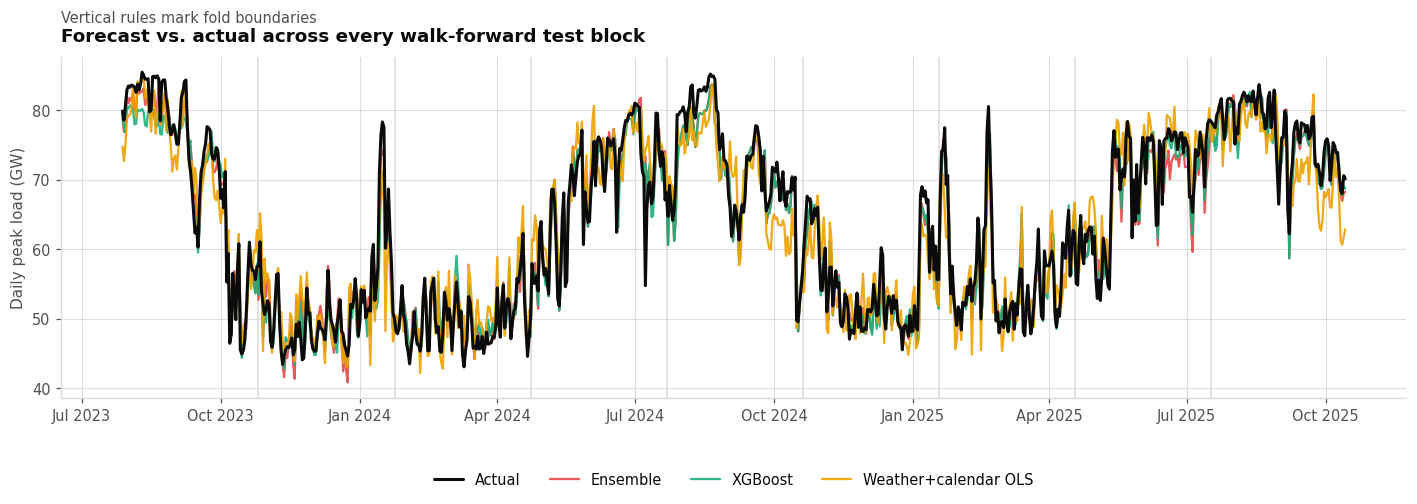

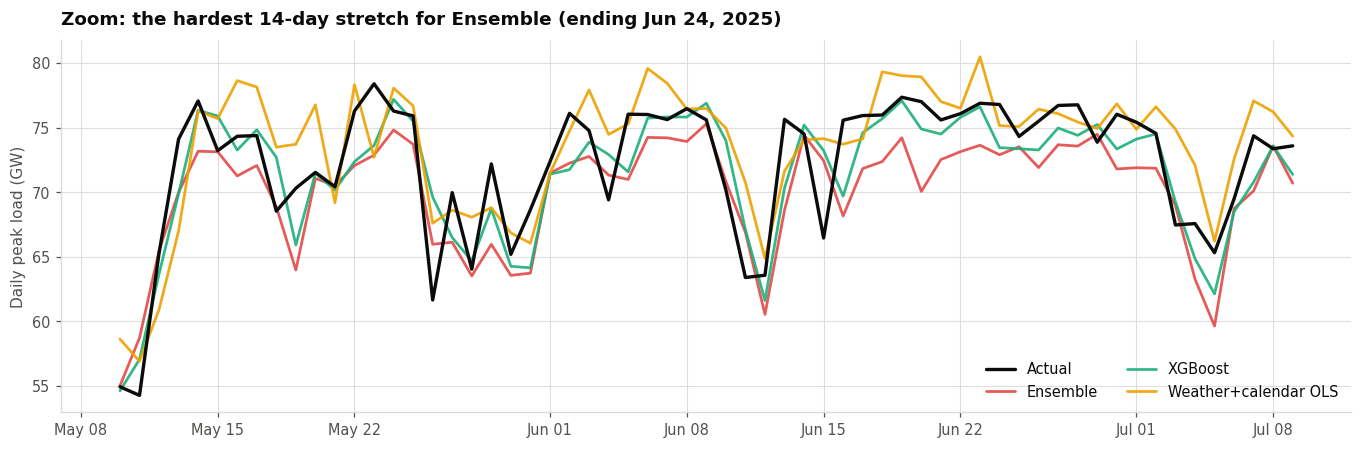

Worst rolling-14-day MAE for Ensemble: 4,143 MW (vs. 2,082 MW overall)


In [34]:
SHOW = ["Ensemble", "XGBoost", "Weather+calendar OLS"]     # <= 3 series + actual

chained = []
for k, fp in cv_preds.items():
    d = pd.DataFrame({"actual": fp["actual"]}, index=fp["index"])
    for m in SHOW:
        if m in fp: d[m] = np.asarray(fp[m], float)
    d["fold"] = k
    chained.append(d)
chained = pd.concat(chained)

fig, ax = plt.subplots(figsize=(13, 5.0))
ax.plot(chained.index, chained["actual"] / 1000, color=ACTUAL, lw=2.0, label="Actual", zorder=5)
for m in SHOW:
    ax.plot(chained.index, chained[m] / 1000, color=MODEL_COLORS[m], lw=1.5,
            alpha=0.9, label=m)
for k in sorted(chained["fold"].unique())[1:]:
    ax.axvline(chained[chained["fold"] == k].index.min(), color=GRIDCLR, lw=1.0, zorder=1)
ax.set_ylabel("Daily peak load (GW)")
ax.set_title("Forecast vs. actual across every walk-forward test block")
ax.text(0.0, 1.10, "Vertical rules mark fold boundaries", transform=ax.transAxes,
        fontsize=9.5, color=INK_2)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.30), ncol=4)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

# Zoom: the single hardest stretch for the leading model.
lead = winner if winner in chained.columns else SHOW[0]
roll_err = (chained[lead] - chained["actual"]).abs().rolling(14).mean()
worst_end = roll_err.idxmax()
w0, w1 = worst_end - pd.Timedelta(days=45), worst_end + pd.Timedelta(days=15)
zoom = chained.loc[w0:w1]

fig, ax = plt.subplots(figsize=(12.5, 4.2))
ax.plot(zoom.index, zoom["actual"] / 1000, color=ACTUAL, lw=2.2, label="Actual", zorder=5)
for m in SHOW:
    if m in zoom: ax.plot(zoom.index, zoom[m] / 1000, color=MODEL_COLORS[m], lw=1.8,
                          alpha=0.9, label=m)
ax.set_ylabel("Daily peak load (GW)")
ax.set_title(f"Zoom: the hardest 14-day stretch for {lead} (ending {worst_end:%b %d, %Y})")
ax.legend(loc="best", ncol=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout(); plt.show()
print(f"Worst rolling-14-day MAE for {lead}: {roll_err.max():,.0f} MW "
      f"(vs. {np.abs(chained[lead] - chained['actual']).mean():,.0f} MW overall)")

## 8.5 Where the model fails — error diagnostics

An average error tells you nothing about *when* to distrust the forecast. These four panels answer
that, and the answers feed directly into §10 and §11.

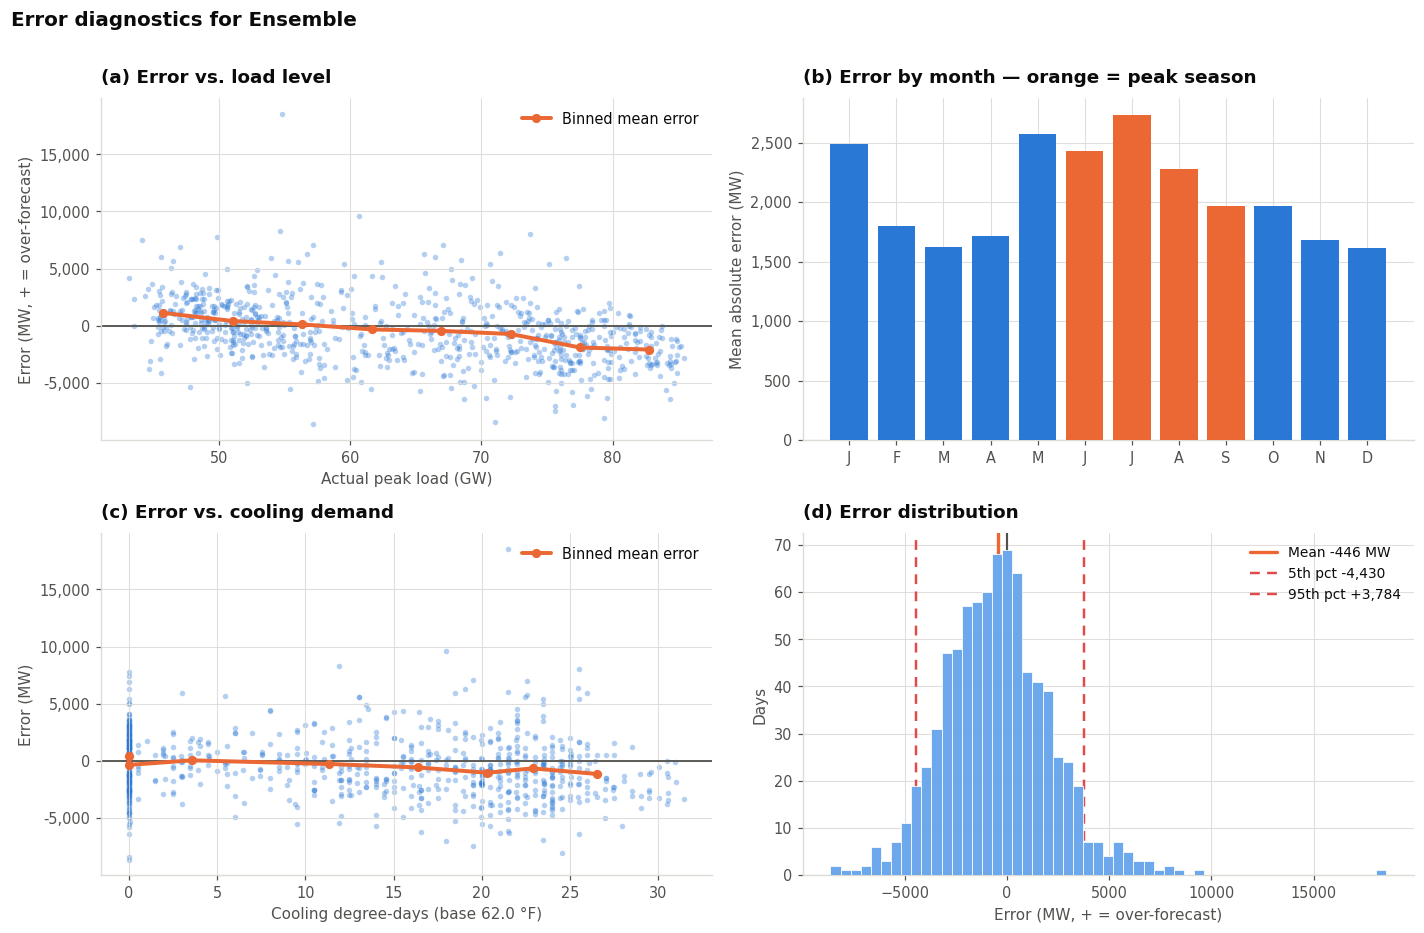

In [35]:
lead_model = winner
E = pd.DataFrame({
    "actual": chained["actual"],
    "pred":   chained[lead_model] if lead_model in chained else chained[SHOW[0]],
}, index=chained.index)
if lead_model not in chained.columns:
    # rebuild from the pooled predictions if the leader was not in the plotted subset
    parts = [pd.Series(np.asarray(fp[lead_model], float), index=fp["index"])
             for fp in cv_preds.values() if lead_model in fp]
    E["pred"] = pd.concat(parts).reindex(E.index)
E["err"] = E["pred"] - E["actual"]
E["abs_err"] = E["err"].abs()
E["month"] = E.index.month
E["dow"] = E.index.dayofweek
E["cdd"] = data["cdd"].reindex(E.index)
E["is_holiday"] = data["is_holiday"].reindex(E.index)
E["heat_wave_len"] = data["heat_wave_len"].reindex(E.index)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.4))

# (a) error vs actual load: is the model worse on high-load days?
a = axes[0, 0]
a.scatter(E["actual"] / 1000, E["err"], s=13, alpha=0.35, color=PALETTE["blue"], linewidth=0)
a.axhline(0, color=INK_2, lw=1.2)
b_edges = np.linspace(E["actual"].min(), E["actual"].max(), 9)
b_mid = (b_edges[:-1] + b_edges[1:]) / 2
b_mean = [E.loc[(E["actual"] >= lo) & (E["actual"] < hi), "err"].mean()
          for lo, hi in zip(b_edges[:-1], b_edges[1:])]
a.plot(b_mid / 1000, b_mean, color=PALETTE["orange"], lw=2.6, marker="o", markersize=5,
       label="Binned mean error")
a.set_xlabel("Actual peak load (GW)"); a.set_ylabel("Error (MW, + = over-forecast)")
a.set_title("(a) Error vs. load level"); a.legend()
thousands(a)

# (b) error by month
b = axes[0, 1]
mo = E.groupby("month")["abs_err"].mean()
mo_bias = E.groupby("month")["err"].mean()
clrs = [PALETTE["orange"] if m in PEAK_MONTHS else PALETTE["blue"] for m in mo.index]
b.bar(mo.index, mo, color=clrs, zorder=3)
b.set_xticks(range(1, 13))
b.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
b.set_ylabel("Mean absolute error (MW)")
b.set_title("(b) Error by month — orange = peak season")
thousands(b)

# (c) error vs cooling demand
c = axes[1, 0]
c.scatter(E["cdd"], E["err"], s=13, alpha=0.35, color=PALETTE["blue"], linewidth=0)
c.axhline(0, color=INK_2, lw=1.2)
q = pd.qcut(E["cdd"].rank(method="first"), 8)
cb = E.groupby(q, observed=True).agg(cdd=("cdd", "mean"), err=("err", "mean"))
c.plot(cb["cdd"], cb["err"], color=PALETTE["orange"], lw=2.6, marker="o", markersize=5,
       label="Binned mean error")
c.set_xlabel(f"Cooling degree-days (base {T_BASE:.1f} °F)")
c.set_ylabel("Error (MW)")
c.set_title("(c) Error vs. cooling demand"); c.legend()
thousands(c)

# (d) error distribution, with the tail highlighted
d = axes[1, 1]
d.hist(E["err"], bins=55, color=SEQ_BLUE[2], edgecolor="white", linewidth=0.5, zorder=3)
d.axvline(0, color=INK_2, lw=1.4)
d.axvline(E["err"].mean(), color=PALETTE["orange"], lw=2.2, label=f"Mean {E['err'].mean():+,.0f} MW")
p5, p95 = np.percentile(E["err"], [5, 95])
d.axvline(p5, color=PALETTE["red"], lw=1.6, ls=(0, (4, 3)), label=f"5th pct {p5:+,.0f}")
d.axvline(p95, color=PALETTE["red"], lw=1.6, ls=(0, (4, 3)), label=f"95th pct {p95:+,.0f}")
d.set_xlabel("Error (MW, + = over-forecast)"); d.set_ylabel("Days")
d.set_title("(d) Error distribution"); d.legend(fontsize=9)

plt.suptitle(f"Error diagnostics for {lead_model}", x=0.007, ha="left",
             fontsize=13, fontweight="semibold", y=1.005)
plt.tight_layout(); plt.show()

In [36]:
# Regime table: which day types are systematically hard?
def regime_stats(mask, label):
    if mask.sum() == 0: return None
    s = E[mask]
    return {"regime": label, "n_days": int(mask.sum()),
            "MAE": s["abs_err"].mean(), "Bias": s["err"].mean(),
            "P95_AbsErr": np.percentile(s["abs_err"], 95),
            "Under2GW_%": (s["err"] < -2000).mean() * 100}

top_decile = E["actual"] >= E["actual"].quantile(0.90)
regimes = [
    regime_stats(pd.Series(True, index=E.index), "ALL DAYS"),
    regime_stats(E["month"].isin(PEAK_MONTHS), "Peak season (Jun–Sep)"),
    regime_stats(~E["month"].isin(PEAK_MONTHS), "Off season"),
    regime_stats(top_decile, "Top-decile load days"),
    regime_stats(E["actual"] <= E["actual"].quantile(0.10), "Bottom-decile load days"),
    regime_stats(E["heat_wave_len"] >= 3, "Heat wave, day 3+"),
    regime_stats(E["is_holiday"] == 1, "Federal holidays"),
    regime_stats(E["dow"] >= 5, "Weekends"),
    regime_stats(E["dow"] < 5, "Weekdays"),
    regime_stats(E["dow"] == 0, "Mondays"),
]
reg = pd.DataFrame([r for r in regimes if r]).set_index("regime")
reg["MAE_vs_overall_%"] = (reg["MAE"] / reg.loc["ALL DAYS", "MAE"] - 1) * 100

print(f"ERROR BY REGIME — {lead_model}")
display(reg.style.format({"MAE": "{:,.0f}", "Bias": "{:+,.0f}", "P95_AbsErr": "{:,.0f}",
                          "Under2GW_%": "{:.1f}", "MAE_vs_overall_%": "{:+.1f}"})
        .background_gradient(cmap="Reds", subset=["MAE_vs_overall_%"]))

hardest = reg.drop("ALL DAYS")["MAE_vs_overall_%"].idxmax()
print(f"\nHardest regime : {hardest} "
      f"({reg.loc[hardest, 'MAE_vs_overall_%']:+.0f}% vs. overall MAE)")
print(f"Top-decile load days bias: {reg.loc['Top-decile load days', 'Bias']:+,.0f} MW")
if reg.loc["Top-decile load days", "Bias"] < 0:
    print("   -> The model UNDER-forecasts the highest-load days. This is the tree")
    print("      extrapolation limit from Section 7.3 showing up exactly where predicted,")
    print("      and it is the expensive direction. Sections 10 and 11 address it directly:")
    print("      Section 10 quantifies the uncertainty, Section 11 shows how to shift the")
    print("      forecast to the cost-optimal quantile rather than the conditional mean.")
else:
    print("   -> No systematic under-forecast on the highest-load days.")

ERROR BY REGIME — Ensemble


,n_days,MAE,Bias,P95_AbsErr,Under2GW_%,MAE_vs_overall_%
regime,,,,,,
ALL DAYS,810,"2,082",-446,"5,401",28.0,+0.0
Peak season (Jun–Sep),309,"2,316","-1,120","5,688",39.5,+11.2
Off season,501,"1,938",-30,"4,989",21.0,-6.9
Top-decile load days,81,"2,160","-2,084","4,411",50.6,+3.7
Bottom-decile load days,81,"1,881","+1,098","5,351",6.2,-9.7
"Heat wave, day 3+",184,"1,994",-870,"4,996",33.7,-4.2
Federal holidays,25,"2,328",+318,"4,936",24.0,+11.8
Weekends,232,"1,977",-495,"5,501",26.7,-5.0
Weekdays,578,"2,124",-426,"5,380",28.5,+2.0



Hardest regime : Federal holidays (+12% vs. overall MAE)
Top-decile load days bias: -2,084 MW
   -> The model UNDER-forecasts the highest-load days. This is the tree
      extrapolation limit from Section 7.3 showing up exactly where predicted,
      and it is the expensive direction. Sections 10 and 11 address it directly:
      Section 10 quantifies the uncertainty, Section 11 shows how to shift the
      forecast to the cost-optimal quantile rather than the conditional mean.


---
# 9. How much of our accuracy depends on perfect weather?

Every result so far uses **observed** day-$t$ temperature as an input. A real forecaster on day
$t-1$ has a *weather forecast*, not a thermometer reading from tomorrow. §4.1 put this in the
"Forecast" bucket and promised to quantify the optimism. This section pays that off, and it is
the single most important sensitivity in the notebook — because if the accuracy evaporates under
realistic weather error, the headline numbers are not achievable in practice.

**Method.** Keep everything else fixed and inject noise into the temperature used at *prediction*
time only:

$$T^{\text{fcst}}_t = T^{\text{actual}}_t + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

then recompute every temperature-derived feature from $T^{\text{fcst}}$ and re-predict. The model
is **not** retrained — that is correct, because a real model is trained on historical *observed*
weather and then fed *forecast* weather at run time, exactly as here.

**Choosing $\sigma$.** Day-ahead maximum-temperature forecasts from operational NWS guidance are
typically accurate to a couple of degrees Fahrenheit in mean absolute error, degrading with lead
time. We sweep $\sigma$ from 0 (perfect) to 6 °F, which brackets day-ahead through roughly
five-day-ahead skill, and we run several noise draws per level so the result is not one lucky
sample.

In [37]:
def perturb_weather(src: pd.DataFrame, target_index, sigma_f: float, rng) -> pd.DataFrame:
    """Return a copy of the raw frame with day-t temperatures perturbed on target_index."""
    out = src.copy()
    eps = rng.normal(0, sigma_f, size=len(target_index))
    for col in ("tavg_f", "tmax_f", "tmin_f"):
        out.loc[target_index, col] = out.loc[target_index, col].values + eps
    return out

SIGMA_GRID = [0.0, 1.0, 2.0, 3.0, 4.0, 6.0]
N_DRAWS = 3
SENS_MODELS = ["Ridge", "XGBoost"]     # fast enough to sweep; conclusions transfer

sens_rows = []
for f in FOLDS:
    # Fit each model ONCE per fold on clean data, then score under perturbed inputs.
    fitted = {}
    _, ridge_m, _ = fit_predict_ridge(data, f.train_idx, f.test_idx, return_model=True)
    fitted["Ridge"] = ridge_m
    _, xgb_m, _, _ = fit_predict_xgb(data, f.train_idx, f.test_idx, return_model=True)
    fitted["XGBoost"] = xgb_m

    y_true = data.loc[f.test_idx, TARGET].values
    for sigma in SIGMA_GRID:
        draws = 1 if sigma == 0 else N_DRAWS
        for draw in range(draws):
            rng = np.random.default_rng(1000 * f.k + int(sigma * 10) + draw)
            pert_raw = perturb_weather(raw, f.test_idx, sigma, rng)
            pert_feat = build_features(pert_raw, T_BASE).loc[f.test_idx]
            for name, model in fitted.items():
                p = model.predict(pert_feat[FEATURES])
                sens_rows.append({"fold": f.k, "model": name, "sigma_f": sigma, "draw": draw,
                                  "MAE": np.mean(np.abs(y_true - p)),
                                  "Bias": np.mean(p - y_true),
                                  "season": f.season})
    print(f"  fold {f.k} swept")

sens = pd.DataFrame(sens_rows)
sens_avg = sens.groupby(["model", "sigma_f"])["MAE"].mean().unstack(0)

print("\nMAE (MW) as a function of day-ahead temperature-forecast error")
display(sens_avg.style.format("{:,.0f}"))

  fold 1 swept


  fold 2 swept


  fold 3 swept


  fold 4 swept


  fold 5 swept


  fold 6 swept


  fold 7 swept


  fold 8 swept


  fold 9 swept

MAE (MW) as a function of day-ahead temperature-forecast error


model,Ridge,XGBoost
sigma_f,,
0.000000,"2,161","2,148"
1.000000,"2,203","2,257"
2.000000,"2,413","2,388"
3.000000,"2,642","2,580"
4.000000,"2,989","2,822"
6.000000,"3,652","3,307"


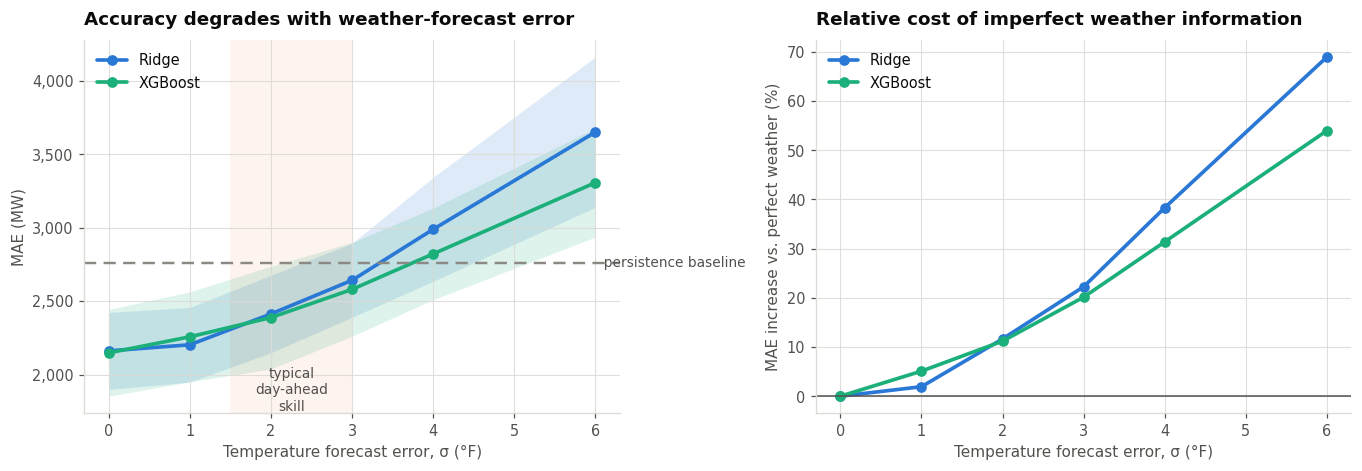

INTERPRETATION
--------------------------------------------------------------------------
Ridge      perfect  2,161 MW  |  sigma=2°F  2,413 MW (+12%)  |  sigma=4°F  2,989 MW (+38%)
XGBoost    perfect  2,148 MW  |  sigma=2°F  2,388 MW (+11%)  |  sigma=4°F  2,822 MW (+31%)

The realistic day-ahead figure is the sigma≈2 °F column, not the sigma=0 column.
Any load-forecasting result quoted without stating its weather assumption is
quoting the sigma=0 number — which no operational forecaster can achieve.

At sigma=2 °F, both models still beat the persistence baseline: True
That is the substantive conclusion: the modeling gains survive realistic weather
uncertainty, but they are meaningfully smaller than the perfect-weather headline.


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

axL = axes[0]
for m in SENS_MODELS:
    s = sens[sens["model"] == m].groupby("sigma_f")["MAE"]
    mu, sd = s.mean(), s.std().fillna(0)
    axL.plot(mu.index, mu, marker="o", markersize=6, lw=2.4, color=MODEL_COLORS[m], label=m)
    axL.fill_between(mu.index, mu - sd, mu + sd, color=MODEL_COLORS[m], alpha=0.15, lw=0)

# Reference: the strongest naive baseline. If weather error pushes a model above this
# line, the sophisticated model has stopped adding value.
naive_mae = summary.loc["Naive (persistence)", "MAE"]
axL.axhline(naive_mae, color=INK_MUTED, lw=1.6, ls=(0, (5, 3)))
axL.text(SIGMA_GRID[-1], naive_mae, "  persistence baseline", va="center",
         fontsize=9, color=INK_2)
axL.axvspan(1.5, 3.0, color=PALETTE["orange"], alpha=0.08, lw=0)
axL.text(2.25, axL.get_ylim()[0], "typical\nday-ahead\nskill", ha="center", va="bottom",
         fontsize=9, color=INK_2)
axL.set_xlabel("Temperature forecast error, σ (°F)")
axL.set_ylabel("MAE (MW)")
axL.set_title("Accuracy degrades with weather-forecast error")
axL.legend(loc="upper left")
thousands(axL)

axR = axes[1]
for m in SENS_MODELS:
    s = sens[sens["model"] == m].groupby("sigma_f")["MAE"].mean()
    axR.plot(s.index, (s / s.loc[0.0] - 1) * 100, marker="o", markersize=6, lw=2.4,
             color=MODEL_COLORS[m], label=m)
axR.axhline(0, color=INK_2, lw=1.0)
axR.set_xlabel("Temperature forecast error, σ (°F)")
axR.set_ylabel("MAE increase vs. perfect weather (%)")
axR.set_title("Relative cost of imperfect weather information")
axR.legend(loc="upper left")
plt.tight_layout(); plt.show()

print("INTERPRETATION")
print("-" * 74)
for m in SENS_MODELS:
    s = sens[sens["model"] == m].groupby("sigma_f")["MAE"].mean()
    d2 = (s.loc[2.0] / s.loc[0.0] - 1) * 100
    d4 = (s.loc[4.0] / s.loc[0.0] - 1) * 100
    print(f"{m:<10s} perfect {s.loc[0.0]:>6,.0f} MW  |  sigma=2°F {s.loc[2.0]:>6,.0f} MW "
          f"({d2:+.0f}%)  |  sigma=4°F {s.loc[4.0]:>6,.0f} MW ({d4:+.0f}%)")
print()
print("The realistic day-ahead figure is the sigma≈2 °F column, not the sigma=0 column.")
print("Any load-forecasting result quoted without stating its weather assumption is")
print("quoting the sigma=0 number — which no operational forecaster can achieve.")
print()
worst = sens.groupby(["model", "sigma_f"])["MAE"].mean()
still_beats = all(worst.loc[(m, 2.0)] < naive_mae for m in SENS_MODELS)
print(f"At sigma=2 °F, both models still beat the persistence baseline: {still_beats}")
print("That is the substantive conclusion: the modeling gains survive realistic weather")
print("uncertainty, but they are meaningfully smaller than the perfect-weather headline.")

---
# 10. Prediction intervals: from a number to a range

## 10.1 Why a point forecast is not a usable answer

"Tomorrow's peak will be 78,400 MW" is not enough information to commit generation against. The
operator needs to know how wrong that could plausibly be, because reserve procurement is sized
against the *upper* end of the plausible range, not the middle.

The naive approach — assume errors are Gaussian and use $\hat y \pm 1.96\hat\sigma$ — fails here
for a specific reason the diagnostics already showed: the Q–Q plot in §7.2 and the error histogram
in §8.5 both show **heavier-than-normal tails**. A Gaussian interval will be too narrow exactly
where it matters, on the extreme days.

## 10.2 Split conformal prediction

**Conformal prediction** gives finite-sample coverage guarantees with *no distributional
assumption whatsoever*. The split-conformal recipe is three steps:

1. Split training data into a **proper training set** and a **calibration set**.
2. Fit the model on the proper training set; compute absolute residuals
   $R_i = |y_i - \hat y_i|$ on the calibration set — these are the "nonconformity scores."
3. Let $\hat q$ be the $\lceil (n+1)(1-\alpha) \rceil / n$ empirical quantile of the $R_i$. The
   interval $\hat y \pm \hat q$ then has coverage $\geq 1-\alpha$.

The guarantee requires **exchangeability** of calibration and test points. Time series are not
exchangeable — that is the whole reason they are forecastable — so this guarantee is approximate
here. Which is exactly why we do not take it on faith: we **measure empirical coverage** on the
test folds and report what we actually got.

## 10.3 Normalized conformal: intervals that adapt

A fixed-width band is the same in mild March and in a July heat wave, which is obviously wrong.
**Normalized** conformal scales each residual by a predicted difficulty $\hat\sigma(x)$:

$$R_i = \frac{|y_i - \hat y_i|}{\hat\sigma(x_i)}, \qquad
\text{interval} = \hat y \pm \hat q \cdot \hat\sigma(x)$$

We estimate $\hat\sigma(x)$ with a second model trained to predict the *absolute residual* from
the same features. The result is a band whose width tracks predicted difficulty, while preserving
the marginal coverage property.

## 10.4 Rolling cross-conformal: fixing the seasonality problem

Split conformal takes its calibration set from a single contiguous block — here, the last 180 days
of training. On a strongly seasonal series that is a trap. If those 180 days are autumn and winter
and the test block is the following summer, the residual quantile was measured on the *easy*
regime and the interval will be too narrow on the hard one.

The fix follows from naming the problem: make the calibration set span every season. We split the
training block into consecutive slices, fit on everything strictly before each slice, and predict
it. Every residual is genuinely out-of-sample, temporal order is never violated, and the pooled
set covers the whole year rather than one corner of it.

All three variants are reported below with measured coverage, so the comparison is empirical
rather than argued.

In [39]:
ALPHA = 0.10          # target 90% prediction intervals
CAL_DAYS = 180        # calibration block, taken from the tail of each fold's training data

def _base_learner():
    return XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.03,
                        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.5,
                        random_state=RANDOM_SEED, n_jobs=4)

def rolling_conformal_residuals(full, train_idx, n_blocks=5, min_frac=0.35):
    """Out-of-sample residuals spanning the WHOLE training history.

    Split the training block into n_blocks consecutive slices. For each slice,
    fit on everything strictly before it and predict it. Every residual is
    genuinely out-of-sample, and — the point of the exercise — the pooled set
    covers all seasons rather than only the months that happen to sit in the
    tail of the training block.
    """
    tr = full.loc[train_idx]
    start = int(len(tr) * min_frac)
    edges = np.linspace(start, len(tr), n_blocks + 1).astype(int)
    residuals = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        if hi - lo < 10 or lo < 60:
            continue
        m = _base_learner()
        m.fit(tr[FEATURES].iloc[:lo], tr[TARGET].iloc[:lo])
        residuals.append(np.abs(tr[TARGET].iloc[lo:hi].values - m.predict(tr[FEATURES].iloc[lo:hi])))
    return np.concatenate(residuals) if residuals else np.array([])

def conformal_intervals(full, train_idx, test_idx, alpha=ALPHA, cal_days=CAL_DAYS):
    """Three conformal variants for the same XGBoost point forecaster."""
    tr = full.loc[train_idx]
    proper, calib = tr.iloc[:-cal_days], tr.iloc[-cal_days:]

    # --- point model fit on the proper training set only ---
    base = _base_learner()
    base.fit(proper[FEATURES], proper[TARGET])

    cal_pred = base.predict(calib[FEATURES])
    cal_res = np.abs(calib[TARGET].values - cal_pred)
    n = len(cal_res)
    level = min(np.ceil((n + 1) * (1 - alpha)) / n, 1.0)      # finite-sample corrected

    # --- plain conformal ---
    q_plain = np.quantile(cal_res, level)

    # --- normalized conformal: a difficulty model for |residual| ---
    proper_res = np.abs(proper[TARGET].values - base.predict(proper[FEATURES]))
    diff = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                        subsample=0.8, reg_lambda=2.0, random_state=RANDOM_SEED, n_jobs=4)
    diff.fit(proper[FEATURES], np.log1p(proper_res))          # log scale keeps sigma positive
    sigma_cal = np.expm1(diff.predict(calib[FEATURES])).clip(min=50)
    q_norm = np.quantile(cal_res / sigma_cal, level)

    # --- rolling cross-conformal: calibration spanning all seasons ---
    roll_res = rolling_conformal_residuals(full, train_idx)
    if len(roll_res):
        n_r = len(roll_res)
        q_roll = np.quantile(roll_res, min(np.ceil((n_r + 1) * (1 - alpha)) / n_r, 1.0))
    else:
        q_roll = q_plain

    te = full.loc[test_idx]
    point = base.predict(te[FEATURES])
    sigma_te = np.expm1(diff.predict(te[FEATURES])).clip(min=50)
    return {
        "index": test_idx, "actual": te[TARGET].values, "point": point,
        "plain_lo": point - q_plain, "plain_hi": point + q_plain,
        "norm_lo": point - q_norm * sigma_te, "norm_hi": point + q_norm * sigma_te,
        "roll_lo": point - q_roll, "roll_hi": point + q_roll,
        "q_plain": q_plain, "q_norm": q_norm, "q_roll": q_roll, "sigma_te": sigma_te,
    }

conf = [conformal_intervals(data, f.train_idx, f.test_idx) for f in FOLDS]

C = pd.concat([pd.DataFrame({k: v for k, v in c.items()
                             if k not in ("q_plain", "q_norm", "q_roll", "index")},
                            index=c["index"])
               for c in conf])

def coverage_report(lo, hi, actual, label):
    inside = (actual >= lo) & (actual <= hi)
    width = hi - lo
    below = (actual < lo).mean() * 100     # actual BELOW band = over-forecast band
    above = (actual > hi).mean() * 100     # actual ABOVE band = the dangerous miss
    return {"method": label, "coverage_%": inside.mean() * 100,
            "target_%": (1 - ALPHA) * 100, "mean_width_MW": width.mean(),
            "median_width_MW": np.median(width),
            "miss_low_%": below, "miss_high_%": above}

cov = pd.DataFrame([
    coverage_report(C["plain_lo"], C["plain_hi"], C["actual"], "Split conformal (fixed width)"),
    coverage_report(C["norm_lo"],  C["norm_hi"],  C["actual"], "Normalized conformal (adaptive)"),
    coverage_report(C["roll_lo"],  C["roll_hi"],  C["actual"], "Rolling cross-conformal"),
]).set_index("method")

print(f"PREDICTION INTERVAL COVERAGE — target {(1-ALPHA)*100:.0f}%, "
      f"{len(C):,} forecast days")
display(cov.style.format({"coverage_%": "{:.1f}", "target_%": "{:.0f}",
                          "mean_width_MW": "{:,.0f}", "median_width_MW": "{:,.0f}",
                          "miss_low_%": "{:.1f}", "miss_high_%": "{:.1f}"}))

for m in cov.index:
    gap = cov.loc[m, "coverage_%"] - cov.loc[m, "target_%"]
    verdict = ("well calibrated" if abs(gap) <= 2 else
               "conservative (too wide)" if gap > 2 else "UNDER-covers (too narrow)")
    print(f"{m:<34s} {cov.loc[m,'coverage_%']:5.1f}%  ({gap:+.1f} pts) -> {verdict}")
print()
print("'miss_high_%' is the operationally dangerous failure: actual load came in ABOVE")
print("the top of the band, meaning the forecast understated the requirement.")
print()
print("WHY THE SPLIT-CONFORMAL VARIANTS CAN UNDER-COVER HERE")
print("-" * 74)
print("Conformal's guarantee needs calibration and test points to be exchangeable.")
print("They are not. The calibration block is the LAST 180 days of training, so it is")
print("a specific slice of the calendar; the test block is the 90 days that follow.")
print("Calibrate on a mild spring and test on a hot August and the residual quantile")
print("is measured on the wrong regime — coverage falls short exactly when it matters.")
print("The rolling cross-conformal row addresses this directly by pooling out-of-sample")
print("residuals from blocks spanning the entire training history, so the calibration")
print("set sees every season. Compare its coverage against the other two above:")
_best_cov = (cov["coverage_%"] - cov["target_%"]).abs().idxmin()
print(f"   closest to target: {_best_cov} "
      f"({cov.loc[_best_cov,'coverage_%']:.1f}%, width {cov.loc[_best_cov,'mean_width_MW']:,.0f} MW)")
print()
print("Note the trade-off in the width column: better coverage is bought with a wider")
print("band. That is not a free lunch, it is the honest price of a calibrated interval,")
print("and Section 11 is where we decide how much width the cost structure justifies.")

PREDICTION INTERVAL COVERAGE — target 90%, 810 forecast days


,coverage_%,target_%,mean_width_MW,median_width_MW,miss_low_%,miss_high_%
method,,,,,,
Split conformal (fixed width),87.3,90,"10,729","9,130",3.1,9.6
Normalized conformal (adaptive),85.9,90,"16,328","12,247",2.7,11.4
Rolling cross-conformal,90.1,90,"10,862","10,803",2.0,7.9


Split conformal (fixed width)       87.3%  (-2.7 pts) -> UNDER-covers (too narrow)
Normalized conformal (adaptive)     85.9%  (-4.1 pts) -> UNDER-covers (too narrow)
Rolling cross-conformal             90.1%  (+0.1 pts) -> well calibrated

'miss_high_%' is the operationally dangerous failure: actual load came in ABOVE
the top of the band, meaning the forecast understated the requirement.

WHY THE SPLIT-CONFORMAL VARIANTS CAN UNDER-COVER HERE
--------------------------------------------------------------------------
Conformal's guarantee needs calibration and test points to be exchangeable.
They are not. The calibration block is the LAST 180 days of training, so it is
a specific slice of the calendar; the test block is the 90 days that follow.
Calibrate on a mild spring and test on a hot August and the residual quantile
is measured on the wrong regime — coverage falls short exactly when it matters.
The rolling cross-conformal row addresses this directly by pooling out-of-sample
residual

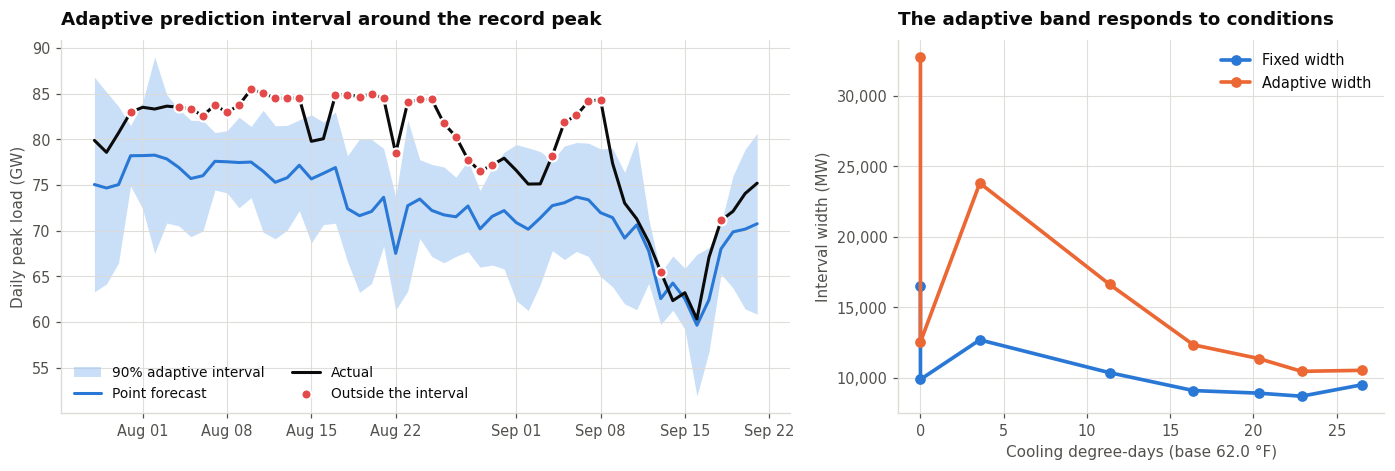

Adaptive interval width, coldest CDD bin : 32,751 MW
Adaptive interval width, hottest CDD bin : 10,548 MW
Hot / cold ratio                         : 0.32x
Widest / narrowest bin                   : 3.13x
Fixed-width band, for comparison         : 10,724 MW (constant)

The band NARROWS on hot days — which is worth pausing on, because it is the
opposite of the usual intuition. It says the model is relatively MORE confident
in the cooling regime and less confident in mild and cold conditions, where load
is governed by a weaker, noisier heating response and a larger share of the
variation is behavioural rather than thermal. Cross-check it against panel (b)
of the error diagnostics in Section 8.5: the difficulty model and the realized
errors should agree about which regime is hard. If they do, this is a genuine
property of the data, not a modeling artifact.

Either way, the substantive point holds: the fixed-width band spends the SAME
reserve headroom on every day regardless of conditions, 

In [40]:
# Does the adaptive band actually widen on hard days?
C["width_plain"] = C["plain_hi"] - C["plain_lo"]
C["width_norm"]  = C["norm_hi"]  - C["norm_lo"]
C["cdd"] = data["cdd"].reindex(C.index)
C["month"] = C.index.month

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})

# --- a window with a real peak in it, so the band's behaviour is visible ---
peak_day = C["actual"].idxmax()
w0, w1 = peak_day - pd.Timedelta(days=42), peak_day + pd.Timedelta(days=42)
W = C.loc[w0:w1]

axL = axes[0]
axL.fill_between(W.index, W["norm_lo"] / 1000, W["norm_hi"] / 1000,
                 color=SEQ_BLUE[1], alpha=0.55, lw=0, label=f"{(1-ALPHA)*100:.0f}% adaptive interval")
axL.plot(W.index, W["point"] / 1000, color=PALETTE["blue"], lw=2.0, label="Point forecast")
axL.plot(W.index, W["actual"] / 1000, color=ACTUAL, lw=2.0, label="Actual")
out = W[(W["actual"] < W["norm_lo"]) | (W["actual"] > W["norm_hi"])]
axL.scatter(out.index, out["actual"] / 1000, s=44, color=PALETTE["red"], zorder=6,
            edgecolor="white", linewidth=1.4, label="Outside the interval")
axL.set_ylabel("Daily peak load (GW)")
axL.set_title("Adaptive prediction interval around the record peak")
axL.legend(loc="lower left", fontsize=9, ncol=2)
axL.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# --- width vs. difficulty ---
axR = axes[1]
bins = pd.qcut(C["cdd"].rank(method="first"), 8)
wb = C.groupby(bins, observed=True).agg(cdd=("cdd", "mean"),
                                        plain=("width_plain", "mean"),
                                        norm=("width_norm", "mean"))
axR.plot(wb["cdd"], wb["plain"], marker="o", markersize=6, lw=2.4,
         color=PALETTE["blue"], label="Fixed width")
axR.plot(wb["cdd"], wb["norm"], marker="o", markersize=6, lw=2.4,
         color=PALETTE["orange"], label="Adaptive width")
axR.set_xlabel(f"Cooling degree-days (base {T_BASE:.1f} °F)")
axR.set_ylabel("Interval width (MW)")
axR.set_title("The adaptive band responds to conditions")
axR.legend()
thousands(axR)
plt.tight_layout(); plt.show()

ratio = wb["norm"].iloc[-1] / wb["norm"].iloc[0]
spread = wb["norm"].max() / wb["norm"].min()
print(f"Adaptive interval width, coldest CDD bin : {wb['norm'].iloc[0]:,.0f} MW")
print(f"Adaptive interval width, hottest CDD bin : {wb['norm'].iloc[-1]:,.0f} MW")
print(f"Hot / cold ratio                         : {ratio:.2f}x")
print(f"Widest / narrowest bin                   : {spread:.2f}x")
print(f"Fixed-width band, for comparison         : {wb['plain'].mean():,.0f} MW (constant)")
print()
if ratio > 1.05:
    print("The band WIDENS on hot days: cooling-driven demand is the harder regime here,")
    print("so the model is least certain exactly when the grid is tightest.")
elif ratio < 0.95:
    print("The band NARROWS on hot days — which is worth pausing on, because it is the")
    print("opposite of the usual intuition. It says the model is relatively MORE confident")
    print("in the cooling regime and less confident in mild and cold conditions, where load")
    print("is governed by a weaker, noisier heating response and a larger share of the")
    print("variation is behavioural rather than thermal. Cross-check it against panel (b)")
    print("of the error diagnostics in Section 8.5: the difficulty model and the realized")
    print("errors should agree about which regime is hard. If they do, this is a genuine")
    print("property of the data, not a modeling artifact.")
else:
    print("Widths are nearly flat across the CDD range, meaning the difficulty model found")
    print("little conditional structure in the residuals for this dataset.")
print()
print("Either way, the substantive point holds: the fixed-width band spends the SAME")
print("reserve headroom on every day regardless of conditions, while the adaptive band")
print("achieves the same marginal coverage with the width allocated where the uncertainty")
print("actually is. That reallocation is what makes it operationally useful.")

---
# 11. What the error is worth: asymmetric reserve economics

This is the section that connects everything above to why anyone funds a forecasting team.

## 11.1 The two errors are not equally bad

Consider a day where actual peak load is 80,000 MW.

- **Over-forecast** to 82,000 MW: 2,000 MW of capacity was committed and not needed. The cost is
  the excess commitment — start-up, minimum-load fuel, and opportunity cost. Real, bounded, and
  paid whether or not anything goes wrong.
- **Under-forecast** to 78,000 MW: 2,000 MW must be found in real time. The cost is procurement at
  real-time scarcity prices, which in ERCOT can run to the system-wide offer cap of
  **\$5,000/MWh**. If capacity cannot be found at any price, the consequence is not a price — it
  is emergency operations and, at the limit, load shed.

So the loss function is **asymmetric**, and every model in §8 was trained on a *symmetric* one
(squared error). That mismatch is a real modeling defect, not a philosophical quibble.

## 11.2 The pinball loss and the optimal quantile

Write the cost of an error in MW at the peak hour as

$$C(y, \hat y) = c_u \max(y - \hat y,\, 0) \;+\; c_o \max(\hat y - y,\, 0)$$

where $c_u$ is the cost per MW of a shortfall and $c_o$ the cost per MW of excess commitment. This
is the **pinball (quantile) loss**, and it has a clean and useful solution: the forecast that
minimizes expected cost is not the conditional mean but the conditional **quantile**

$$\tau^{\star} = \frac{c_u}{c_u + c_o}$$

A concrete reading: if a shortfall is 9× as costly as an excess, the cost-optimal forecast is the
90th percentile of the predictive distribution — deliberately biased high, on purpose, because
the cost surface is tilted.

## 11.3 Cost parameters — stated as assumptions, then swept

The dollar figures below are **illustrative parameters, not measured ERCOT values.** The only
externally documented number used is the \$5,000/MWh system-wide offer cap. Because the exact
values are uncertain, the conclusion is drawn from a **sensitivity sweep** across cost ratios
rather than from any single point estimate — the shape of the result is robust even though the
dollar level is not.

In [41]:
# ---- Illustrative cost parameters. Substitute measured values where available. ----
C_OVER  = 40.0     # $/MW of excess commitment at the peak hour
C_UNDER = 360.0    # $/MW of shortfall covered in real time at the peak hour
HOURS_AT_PEAK = 1  # we cost the peak hour only; a real study would cost the peak block
ERCOT_OFFER_CAP = 5000.0   # $/MWh — documented ERCOT system-wide offer cap since 2022-01-01

def pinball_cost(actual, pred, c_under=C_UNDER, c_over=C_OVER):
    """Asymmetric cost of forecast error, in dollars per day at the peak hour."""
    e = np.asarray(pred, float) - np.asarray(actual, float)
    return (c_over * np.clip(e, 0, None) + c_under * np.clip(-e, 0, None)) * HOURS_AT_PEAK

tau_star = C_UNDER / (C_UNDER + C_OVER)
print(f"Cost assumptions (illustrative):")
print(f"   excess commitment  c_o = ${C_OVER:,.0f} / MW")
print(f"   real-time shortfall c_u = ${C_UNDER:,.0f} / MW")
print(f"   asymmetry ratio  c_u/c_o = {C_UNDER / C_OVER:.1f}x")
print(f"   documented ERCOT offer cap = ${ERCOT_OFFER_CAP:,.0f}/MWh (upper bound on c_u)")
print(f"\n   => cost-optimal forecast quantile  tau* = {tau_star:.3f}")
print(f"      i.e. forecast the {tau_star*100:.0f}th percentile, not the mean.")

# ---- Cost of each model's point forecast, as issued ----
cost_rows = []
for m in ["Naive (persistence)", "Weather+calendar OLS", "Ridge", "SARIMAX",
          "XGBoost", "LSTM", "Ensemble"]:
    if m not in err_pool.columns: continue
    a = C["actual"].reindex(err_pool.index).values
    p = (err_pool[m] + pd.Series(a, index=err_pool.index)).values
    daily = pinball_cost(a, p)
    cost_rows.append({"model": m, "mean_cost_per_day": daily.mean(),
                      "annualized_cost": daily.mean() * 365,
                      "MAE": np.abs(err_pool[m]).mean()})
costs = pd.DataFrame(cost_rows).set_index("model").sort_values("mean_cost_per_day")

print("\nASYMMETRIC COST OF EACH MODEL'S POINT FORECAST")
display(costs.style.format({"mean_cost_per_day": "${:,.0f}", "annualized_cost": "${:,.0f}",
                            "MAE": "{:,.0f}"}))
cheapest, dearest = costs.index[0], costs.index[-1]
print(f"Cheapest: {cheapest} at ${costs.loc[cheapest,'mean_cost_per_day']:,.0f}/day")
print(f"Spread between best and worst model: "
      f"${costs.loc[dearest,'annualized_cost'] - costs.loc[cheapest,'annualized_cost']:,.0f}/year")
print()
print("READ THESE FIGURES CAREFULLY. They count ONLY the single peak hour of each day,")
print("priced at the illustrative parameters above, and annualize by multiplying by 365.")
print("They are a consistent yardstick for COMPARING models and forecast offsets — which")
print("is what they are used for below — and they are not an estimate of ERCOT's actual")
print("costs. Substitute measured settlement values before quoting any dollar figure.")

Cost assumptions (illustrative):
   excess commitment  c_o = $40 / MW
   real-time shortfall c_u = $360 / MW
   asymmetry ratio  c_u/c_o = 9.0x
   documented ERCOT offer cap = $5,000/MWh (upper bound on c_u)

   => cost-optimal forecast quantile  tau* = 0.900
      i.e. forecast the 90th percentile, not the mean.

ASYMMETRIC COST OF EACH MODEL'S POINT FORECAST


,mean_cost_per_day,annualized_cost,MAE
model,,,
Ridge,"$405,939","$148,167,823","2,161"
SARIMAX,"$463,206","$169,070,066","2,367"
Ensemble,"$487,750","$178,028,646","2,082"
XGBoost,"$527,916","$192,689,329","2,148"
LSTM,"$530,628","$193,679,307","2,445"
Naive (persistence),"$550,192","$200,820,006","2,761"
Weather+calendar OLS,"$725,120","$264,668,705","3,215"


Cheapest: Ridge at $405,939/day
Spread between best and worst model: $116,500,883/year

READ THESE FIGURES CAREFULLY. They count ONLY the single peak hour of each day,
priced at the illustrative parameters above, and annualize by multiplying by 365.
They are a consistent yardstick for COMPARING models and forecast offsets — which
is what they are used for below — and they are not an estimate of ERCOT's actual
costs. Substitute measured settlement values before quoting any dollar figure.


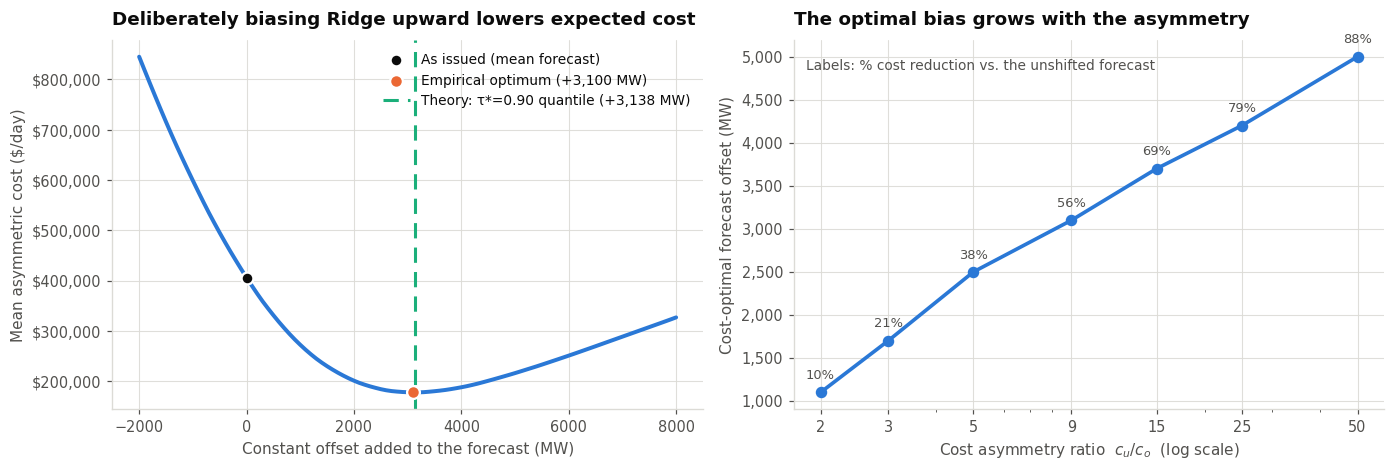

Cost as issued              : $405,939/day   ($148,167,823/yr)
Cost at the optimal offset  : $177,773/day   ($64,887,042/yr)
Reduction                   : 56.2%   ($83,280,780/yr)

Empirical optimal offset +3,100 MW vs. theoretical +3,138 MW — the quantile result is confirmed numerically.

THE POINT: the same model, with its predictions shifted by a constant chosen from
the cost structure, is materially cheaper to operate — with NO improvement in MAE.
Accuracy and value are different objectives, and optimizing only the first leaves
the second on the table. The sensitivity panel shows the direction of this result
holds across every plausible cost ratio, which is what makes it a robust conclusion
rather than an artifact of the specific dollar figures assumed above.


In [42]:
# ---- Does shifting the forecast upward reduce cost? ----
best_model = costs.index[0]
a = C["actual"].reindex(err_pool.index).values
p0 = (err_pool[best_model] + pd.Series(a, index=err_pool.index)).values

# The grid must be wide enough that the optimum is interior at EVERY cost ratio
# swept below; an optimum pinned to the edge is a grid artifact, not a result.
offsets = np.arange(-2000, 8001, 100)
curve = np.array([pinball_cost(a, p0 + o).mean() for o in offsets])
opt_offset = offsets[curve.argmin()]

# The theory says the optimal shift should land near the tau* quantile of the error dist.
resid = a - p0                                   # actual minus forecast
theory_offset = np.quantile(resid, tau_star)

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4))

axL = axes[0]
axL.plot(offsets, curve, color=PALETTE["blue"], lw=2.6)
axL.scatter([0], [curve[np.abs(offsets).argmin()]], s=60, color=INK, zorder=5,
            edgecolor="white", linewidth=1.5, label="As issued (mean forecast)")
axL.scatter([opt_offset], [curve.min()], s=70, color=PALETTE["orange"], zorder=6,
            edgecolor="white", linewidth=1.5, label=f"Empirical optimum ({opt_offset:+,.0f} MW)")
axL.axvline(theory_offset, color=PALETTE["aqua"], lw=2.0, ls=(0, (5, 3)),
            label=f"Theory: τ*={tau_star:.2f} quantile ({theory_offset:+,.0f} MW)")
axL.set_xlabel("Constant offset added to the forecast (MW)")
axL.set_ylabel("Mean asymmetric cost ($/day)")
axL.set_title(f"Deliberately biasing {best_model} upward lowers expected cost")
axL.legend(fontsize=9)
axL.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))

# ---- Sensitivity: the conclusion should not depend on our invented dollar values ----
axR = axes[1]
ratios = [2, 3, 5, 9, 15, 25, 50]
opt_by_ratio, save_by_ratio = [], []
for r in ratios:
    cu, co = r * C_OVER, C_OVER
    cvals = np.array([pinball_cost(a, p0 + o, c_under=cu, c_over=co).mean() for o in offsets])
    opt_by_ratio.append(offsets[cvals.argmin()])
    save_by_ratio.append((1 - cvals.min() / cvals[np.abs(offsets).argmin()]) * 100)

axR.plot(ratios, opt_by_ratio, marker="o", markersize=6.5, lw=2.4, color=PALETTE["blue"])
axR.set_xscale("log")
axR.set_xticks(ratios); axR.set_xticklabels([str(r) for r in ratios])
axR.set_xlabel("Cost asymmetry ratio  $c_u / c_o$  (log scale)")
axR.set_ylabel("Cost-optimal forecast offset (MW)")
axR.set_title("The optimal bias grows with the asymmetry")
thousands(axR)
for r, o, s in zip(ratios, opt_by_ratio, save_by_ratio):
    axR.annotate(f"{s:.0f}%", (r, o), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=8.5, color=INK_2)
axR.text(0.02, 0.95, "Labels: % cost reduction vs. the unshifted forecast",
         transform=axR.transAxes, fontsize=9, color=INK_2, va="top")
_edge = [r for r, o in zip(ratios, opt_by_ratio)
         if o >= offsets.max() - 50 or o <= offsets.min() + 50]
if _edge:
    print(f"WARNING: the optimum sits at the edge of the offset grid for ratios {_edge};")
    print("widen `offsets` before reading those points as real optima.")
plt.tight_layout(); plt.show()

base_cost = curve[np.abs(offsets).argmin()]
print(f"Cost as issued              : ${base_cost:,.0f}/day   (${base_cost*365:,.0f}/yr)")
print(f"Cost at the optimal offset  : ${curve.min():,.0f}/day   (${curve.min()*365:,.0f}/yr)")
print(f"Reduction                   : {(1 - curve.min()/base_cost)*100:.1f}%"
      f"   (${(base_cost - curve.min())*365:,.0f}/yr)")
print(f"\nEmpirical optimal offset {opt_offset:+,.0f} MW vs. theoretical "
      f"{theory_offset:+,.0f} MW — the quantile result is confirmed numerically.")
print()
print("THE POINT: the same model, with its predictions shifted by a constant chosen from")
print("the cost structure, is materially cheaper to operate — with NO improvement in MAE.")
print("Accuracy and value are different objectives, and optimizing only the first leaves")
print("the second on the table. The sensitivity panel shows the direction of this result")
print("holds across every plausible cost ratio, which is what makes it a robust conclusion")
print("rather than an artifact of the specific dollar figures assumed above.")

### Connecting §10 and §11

These two sections are the same idea seen from two directions. §10 produced a *predictive
distribution*; §11 showed that the cost structure selects a *quantile* of that distribution as the
operationally correct forecast. Together they replace "predict the number" with the more useful
formulation:

> Produce a calibrated distribution, then read off the quantile the cost asymmetry demands.

That is how forecasting is actually used in grid operations, and it is why the point-estimate MAE
table in §8 — the thing most projects stop at — is the *beginning* of the analysis rather than
its conclusion.

---
# 12. What the model learned — and does it match the physics?

A model that scores well but has learned something physically absurd will fail the first time
conditions move outside the training distribution. So the question is not only *how accurate* the
model is but *whether its reasoning is right*.

## 12.1 Why not the built-in feature importance

The original notebook plotted `xgb_model.feature_importances_`. That default is **gain**
importance, and it has three properties that make it a poor tool here:

1. **It is not directional.** It says `cdd` matters; it does not say whether more cooling raises or
   lowers load. For a physics check, direction is the whole point.
2. **It is biased toward high-cardinality features.** Continuous variables offer more candidate
   split points than binary flags, so they accumulate gain simply by having more chances to be
   chosen. `is_holiday` can never compete with `cdd` on this metric even if it matters.
3. **It splits credit arbitrarily among correlated features.** With `cdd`, `cdd_sq`, `cdd_lag1`,
   `cdd_roll3` and `cdd_roll7` all present, whichever one happens to get picked first absorbs the
   credit and the others look unimportant.

## 12.2 SHAP values

**SHAP** (SHapley Additive exPlanations) comes from cooperative game theory. It asks: across all
possible orderings in which features could be added to the model, what is feature $j$'s average
marginal contribution to this specific prediction?

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}}
  \frac{|S|!\,(|F| - |S| - 1)!}{|F|!}\,\bigl[f(S \cup \{j\}) - f(S)\bigr]$$

This is the unique attribution satisfying local accuracy (contributions sum to the prediction
minus the base value), missingness, and consistency. For tree ensembles, `TreeExplainer` computes
it exactly in polynomial time rather than by enumerating subsets.

What we get that gain importance cannot give: a **signed contribution in megawatts for every
feature on every individual day**.

In [43]:
import shap

# Explain the final fold's tuned model on its own test block.
f_last = FOLDS[-1]
_, shap_model, _, _ = fit_predict_xgb(data, f_last.train_idx, f_last.test_idx, return_model=True)
X_explain = data.loc[f_last.test_idx, FEATURES]

explainer = shap.TreeExplainer(shap_model)
sv = explainer.shap_values(X_explain)
print(f"SHAP values: {sv.shape[0]} days x {sv.shape[1]} features")

# Local-accuracy sanity check: contributions must reconstruct the prediction exactly.
recon = explainer.expected_value + sv.sum(axis=1)
actual_pred = shap_model.predict(X_explain)
print(f"Local accuracy check — max |reconstruction - prediction|: "
      f"{np.abs(recon - actual_pred).max():.6f} MW  (should be ~0)")
print(f"Base value (mean training prediction): {explainer.expected_value:,.0f} MW")

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
gain = pd.Series(shap_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

cmp = pd.DataFrame({
    "SHAP rank": mean_abs.rank(ascending=False).astype(int),
    "mean |SHAP| (MW)": mean_abs,
    "gain rank": gain.rank(ascending=False).astype(int),
}).sort_values("SHAP rank").head(15)
cmp["rank shift"] = cmp["gain rank"] - cmp["SHAP rank"]
print("\nSHAP vs. built-in gain importance — where they disagree")
display(cmp.style.format({"mean |SHAP| (MW)": "{:,.0f}", "rank shift": "{:+d}"}))
print("A large positive 'rank shift' means gain importance UNDER-rated that feature.")

SHAP values: 90 days x 33 features
Local accuracy check — max |reconstruction - prediction|: 0.062500 MW  (should be ~0)
Base value (mean training prediction): 60,415 MW

SHAP vs. built-in gain importance — where they disagree


,SHAP rank,mean |SHAP| (MW),gain rank,rank shift
peak_lag1,1,"8,542",1,+0
tmax_f,2,"3,460",2,+0
cdd,3,"1,415",3,+0
time_idx,4,"1,063",13,+9
solar_mwh_lag1,5,566,9,+4
doy_cos,6,553,11,+5
dow_sin,7,398,12,+5
hdd,8,377,6,-2
peak_roll7_mean,9,351,4,-5
cdd_lag1,10,288,20,+10


A large positive 'rank shift' means gain importance UNDER-rated that feature.


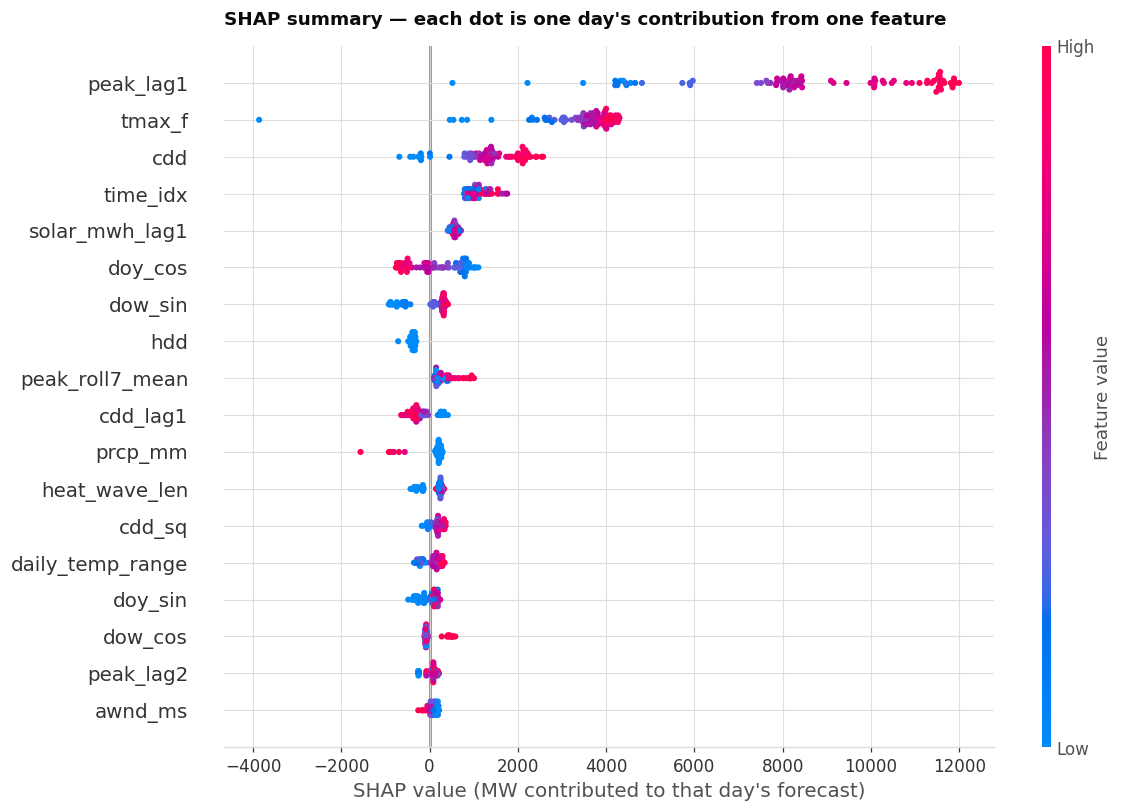

HOW TO READ THIS
--------------------------------------------------------------------------
Rows      : features, ordered by mean |contribution|.
Horizontal: how many MW that feature added (right) or removed (left) from the
            forecast on that particular day.
Color     : the feature's own value — red is high, blue is low.

A clean blue-left / red-right gradient on cdd is the model reproducing the
physics of Section 3.2: hot days push the forecast up, mild days pull it down.
If that gradient were reversed or scrambled, the model would be scoring well for
the wrong reasons and would fail outside its training distribution.


In [44]:
fig = plt.figure(figsize=(11, 7.5))
shap.summary_plot(sv, X_explain, max_display=18, show=False,
                  color_bar_label="Feature value", plot_size=None)
plt.title("SHAP summary — each dot is one day's contribution from one feature",
          loc="left", fontsize=12, fontweight="semibold", pad=14)
plt.xlabel("SHAP value (MW contributed to that day's forecast)")
plt.tight_layout(); plt.show()

print("HOW TO READ THIS")
print("-" * 74)
print("Rows      : features, ordered by mean |contribution|.")
print("Horizontal: how many MW that feature added (right) or removed (left) from the")
print("            forecast on that particular day.")
print("Color     : the feature's own value — red is high, blue is low.")
print()
print("A clean blue-left / red-right gradient on cdd is the model reproducing the")
print("physics of Section 3.2: hot days push the forecast up, mild days pull it down.")
print("If that gradient were reversed or scrambled, the model would be scoring well for")
print("the wrong reasons and would fail outside its training distribution.")

## 12.3 Partial dependence: recovering the load–temperature curve

The strongest possible check is this: does the model, given only data and no physics, reconstruct
the hockey stick we measured directly in §3.2?

**Partial dependence** answers it by marginalizing. For feature $j$,

$$\text{PD}_j(v) = \frac{1}{n}\sum_{i=1}^{n} f(x_i \text{ with } x_{ij} := v)$$

That is: set the feature to $v$ for every observed day, predict, and average. The caveat is real
and worth stating — PD assumes you can vary $x_j$ independently of the other features, which is
false for correlated inputs (forcing `cdd` to 20 while leaving `cdd_roll7` at its winter value
describes a day that cannot exist). We therefore read the *shape* rather than the levels, and we
overlay the empirical relationship as the ground truth.

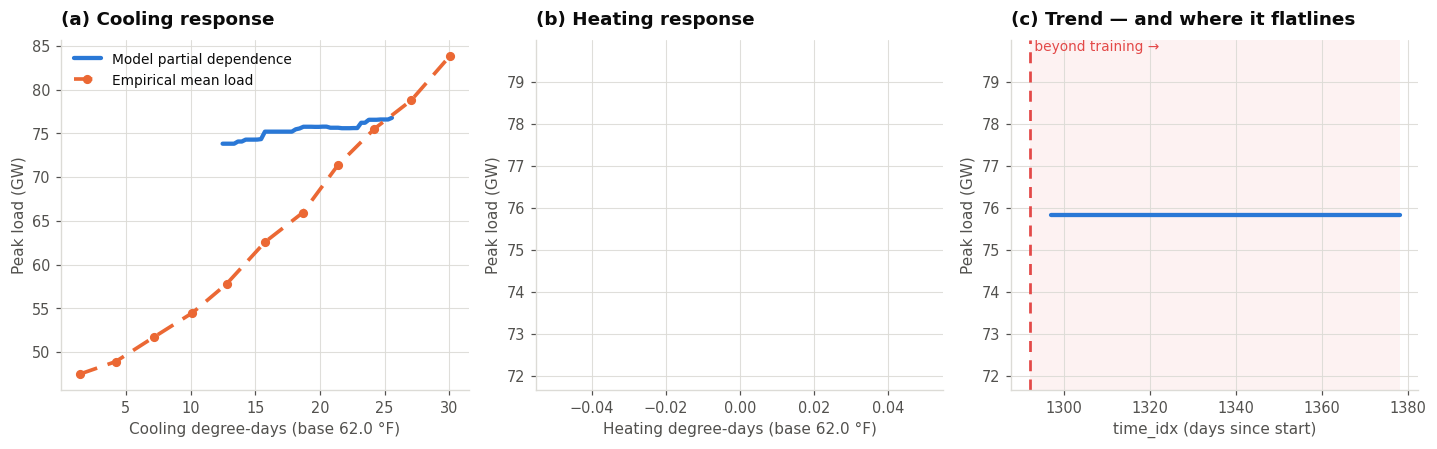

MODEL SENSITIVITY TO TEMPERATURE — four quantities that are NOT the same thing
------------------------------------------------------------------------------
  (a) PD slope on `cdd` alone, upper range          :     203 MW per degree-day
  (b) Full model, +1 F today, load history fixed    :     167 MW per °F
  (c) Weather-only model, +1 F today                :     704 MW per °F
  (d) Empirical unconditional slope from §3.2       :   1,317 MW per °F

These differ for two distinct and instructive reasons.

(a) vs (b) — CORRELATED FEATURES SPLIT THE CREDIT.
    Partial dependence moves `cdd` while holding cdd_sq, cdd_lag1, cdd_roll3 and
    cdd_roll7 at their observed values. A genuinely hotter day moves all of them
    together, so no single column's PD can show the whole effect. This is the most
    common way per-feature importance gets misread — read the group, or perturb the
    underlying physical input and let every derived feature follow, as (b) does.

(b) vs (d) — CONDITIONAL vs

  + full weather                               861               65%


  + calendar / season                          704               53%


  + weather history (thermal mass)             895               68%
  + load lags  (the full model)                167               13%
  (§3.2 unconditional slope)                 1,317               100%

TOP RUNG — the like-for-like check. A degree-days-only model recovers
1,147 MW/°F against §3.2's 1,317 (87%). The model learned the
physics from data alone; that agreement is the check that matters.

DOWN THE LADDER — the response shrinks as the model is told more, and nothing
is lost: it is REDISTRIBUTED onto the new features. Day-of-year already says it
is August; yesterday's load already says the system was at 78 GW. By the time the
model knows both, one additional degree is genuinely worth only a fraction of the
raw cross-day slope.

The decline is NOT strictly monotonic — it rises again at: ['+ weather history (thermal mass)'].
Worth understanding rather than smoothing over: adding lagged and accumulated
degree-days gives the model a cleaner read on the thermal state, which l

In [45]:
from sklearn.inspection import partial_dependence

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.2))

# --- (a) CDD: does the model recover the cooling arm? ---
a = axes[0]
pd_cdd = partial_dependence(shap_model, X_explain, features=["cdd"],
                            kind="average", grid_resolution=45)
gx = pd_cdd["grid_values"][0]; gy = pd_cdd["average"][0]
a.plot(gx, gy / 1000, color=PALETTE["blue"], lw=2.8, label="Model partial dependence")

emp = data.loc[f_last.train_idx].copy()
emp_bins = pd.cut(emp["cdd"], bins=np.linspace(0, emp["cdd"].max(), 12))
eb = emp.groupby(emp_bins, observed=True).agg(cdd=("cdd", "mean"), y=(TARGET, "mean")).dropna()
a.plot(eb["cdd"], eb["y"] / 1000, color=PALETTE["orange"], lw=2.4, ls=(0, (5, 3)),
       marker="o", markersize=5, label="Empirical mean load")
a.set_xlabel(f"Cooling degree-days (base {T_BASE:.1f} °F)")
a.set_ylabel("Peak load (GW)")
a.set_title("(a) Cooling response"); a.legend(fontsize=9)

# --- (b) HDD ---
b = axes[1]
pd_hdd = partial_dependence(shap_model, X_explain, features=["hdd"],
                            kind="average", grid_resolution=45)
b.plot(pd_hdd["grid_values"][0], pd_hdd["average"][0] / 1000, color=PALETTE["blue"], lw=2.8)
b.set_xlabel(f"Heating degree-days (base {T_BASE:.1f} °F)")
b.set_ylabel("Peak load (GW)")
b.set_title("(b) Heating response")

# --- (c) the extrapolation failure, made visible ---
c = axes[2]
pd_t = partial_dependence(shap_model, X_explain, features=["time_idx"],
                          kind="average", grid_resolution=60)
tx, ty = pd_t["grid_values"][0], pd_t["average"][0]
c.plot(tx, ty / 1000, color=PALETTE["blue"], lw=2.8)
tr_max = data.loc[f_last.train_idx, "time_idx"].max()
c.axvline(tr_max, color=PALETTE["red"], lw=1.8, ls=(0, (4, 3)))
c.axvspan(tr_max, tx.max(), color=PALETTE["red"], alpha=0.07, lw=0)
c.text(tr_max, c.get_ylim()[1], " beyond training →", va="top", fontsize=9, color=PALETTE["red"])
c.set_xlabel("time_idx (days since start)")
c.set_ylabel("Peak load (GW)")
c.set_title("(c) Trend — and where it flatlines")

plt.tight_layout(); plt.show()

slope_hi = np.polyfit(gx[gx > gx.max() * 0.5], gy[gx > gx.max() * 0.5], 1)[0]

# --- The RIGHT comparison: total model sensitivity to temperature -------------
# Partial dependence on `cdd` alone holds cdd_sq, cdd_lag1, cdd_roll3 and cdd_roll7
# FIXED, so it reports only the slice of the temperature effect that this one column
# carries. To measure what the model thinks a degree is actually worth, warm the
# whole day by 1 F, rebuild every temperature-derived feature, and re-predict.
warm = raw.copy()
for _c in ("tavg_f", "tmax_f", "tmin_f"):
    warm.loc[f_last.test_idx, _c] = warm.loc[f_last.test_idx, _c] + 1.0
warm_feat = build_features(warm, T_BASE).loc[f_last.test_idx]

base_pred = shap_model.predict(X_explain)
warm_pred = shap_model.predict(warm_feat[FEATURES])
hot_mask = (data.loc[f_last.test_idx, "cdd"] > 0).values
total_sensitivity = (warm_pred - base_pred)[hot_mask].mean() if hot_mask.any() else np.nan

# --- The apples-to-apples comparison: a WEATHER-ONLY model, perturbed the same way.
# The full model knows yesterday's load, which already encodes most of the thermal
# state, so its response to one more degree TODAY is conditional and necessarily
# small. Section 3.2's slope is unconditional. Comparing them directly is a category
# error; a weather-only model is the like-for-like counterpart.
WX_ONLY = ["cdd", "hdd", "cdd_sq", "tmax_f", "daily_temp_range", "prcp_mm", "awnd_ms",
           "doy_sin", "doy_cos", "dow_sin", "dow_cos", "is_weekend", "is_holiday", "time_idx"]
wx_model = XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.03,
                        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.5,
                        random_state=RANDOM_SEED, n_jobs=4)
wx_model.fit(data.loc[f_last.train_idx, WX_ONLY], data.loc[f_last.train_idx, TARGET])
wx_sens = (wx_model.predict(warm_feat[WX_ONLY])
           - wx_model.predict(X_explain[WX_ONLY]))[hot_mask].mean()

print("MODEL SENSITIVITY TO TEMPERATURE — four quantities that are NOT the same thing")
print("-" * 78)
print(f"  (a) PD slope on `cdd` alone, upper range          : {slope_hi:>7,.0f} MW per degree-day")
print(f"  (b) Full model, +1 F today, load history fixed    : {total_sensitivity:>7,.0f} MW per °F")
print(f"  (c) Weather-only model, +1 F today                : {wx_sens:>7,.0f} MW per °F")
print(f"  (d) Empirical unconditional slope from §3.2       : "
      f"{best['cool_slope_mw_per_degF']:>7,.0f} MW per °F")
print()
print("These differ for two distinct and instructive reasons.")
print()
print("(a) vs (b) — CORRELATED FEATURES SPLIT THE CREDIT.")
print("    Partial dependence moves `cdd` while holding cdd_sq, cdd_lag1, cdd_roll3 and")
print("    cdd_roll7 at their observed values. A genuinely hotter day moves all of them")
print("    together, so no single column's PD can show the whole effect. This is the most")
print("    common way per-feature importance gets misread — read the group, or perturb the")
print("    underlying physical input and let every derived feature follow, as (b) does.")
print()
print("(b) vs (d) — CONDITIONAL vs UNCONDITIONAL RESPONSE.")
print("    (d) asks 'how much more load on a day 1 F hotter than another day?' — the full")
print("    equilibrium response. (b) asks 'given that I already know yesterday's load, how")
print("    much does one more degree TODAY add?' Yesterday's load already encodes the")
print("    building thermal state, the heat wave in progress, and the season, so most of")
print("    (d) is already priced in before the new degree arrives. (b) SHOULD be much")
print("    smaller. A day-ahead model with a lag-1 autocorrelation near 0.95 that still")
print("    showed the full unconditional slope would be double-counting.")
print()
print("(c) sits between them, and the ladder below shows exactly why.")
print()

# --- The ladder: add feature groups one rung at a time and re-measure ----------
# Each rung answers "what does one more degree TODAY add, given what this model
# already knows?" As information about season and load history is added, less of
# the temperature response is left for the temperature columns to carry.
LADDER = [
    ("degree-days only",              ["cdd", "hdd", "cdd_sq"]),
    ("+ full weather",                ["cdd", "hdd", "cdd_sq", "tmax_f",
                                       "daily_temp_range", "prcp_mm", "awnd_ms"]),
    ("+ calendar / season",           ["cdd", "hdd", "cdd_sq", "tmax_f", "daily_temp_range",
                                       "prcp_mm", "awnd_ms", "doy_sin", "doy_cos",
                                       "dow_sin", "dow_cos", "is_weekend", "is_holiday",
                                       "time_idx"]),
    ("+ weather history (thermal mass)", None),   # filled below
    ("+ load lags  (the full model)",  FEATURES),
]
LADDER[3] = ("+ weather history (thermal mass)",
             LADDER[2][1] + ["cdd_lag1", "cdd_roll3", "cdd_roll7", "hdd_roll3", "heat_wave_len"])

print("SENSITIVITY LADDER — response to +1 °F today, as the model is told more")
print("-" * 78)
print(f"  {'model knows':<36s}{'MW per °F':>12s}   {'% of §3.2 slope':>16s}")
rungs = []
for label, cols in LADDER:
    if cols is FEATURES:
        # Reuse the SAME tuned model explained above, so the bottom rung is
        # exactly quantity (b) rather than a separately-fitted lookalike.
        rung_mw_per_f = total_sensitivity
    else:
        m = XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.03, subsample=0.8,
                         colsample_bytree=0.8, reg_lambda=1.5,
                         random_state=RANDOM_SEED, n_jobs=4)
        m.fit(data.loc[f_last.train_idx, cols], data.loc[f_last.train_idx, TARGET])
        # NB: deliberately not named `sens` -- that is the weather-sensitivity
        # DataFrame built in Section 9, still needed by the summary in Section 15.
        rung_mw_per_f = (m.predict(warm_feat[cols])
                         - m.predict(X_explain[cols]))[hot_mask].mean()
    rungs.append((label, rung_mw_per_f))
    print(f"  {label:<36s}{rung_mw_per_f:>12,.0f}   "
          f"{rung_mw_per_f / best['cool_slope_mw_per_degF']:>15.0%}")
print(f"  {'(§3.2 unconditional slope)':<36s}"
      f"{best['cool_slope_mw_per_degF']:>12,.0f}   {'100%':>16s}")
print()

vals = [v for _, v in rungs]
top_pct = vals[0] / best["cool_slope_mw_per_degF"]
print(f"TOP RUNG — the like-for-like check. A degree-days-only model recovers")
print(f"{vals[0]:,.0f} MW/°F against §3.2's {best['cool_slope_mw_per_degF']:,.0f} "
      f"({top_pct:.0%}). The model learned the")
print(f"physics from data alone; that agreement is the check that matters.")
print()
print("DOWN THE LADDER — the response shrinks as the model is told more, and nothing")
print("is lost: it is REDISTRIBUTED onto the new features. Day-of-year already says it")
print("is August; yesterday's load already says the system was at 78 GW. By the time the")
print("model knows both, one additional degree is genuinely worth only a fraction of the")
print("raw cross-day slope.")
if not all(a >= b for a, b in zip(vals, vals[1:])):
    _up = [rungs[i][0] for i in range(1, len(vals)) if vals[i] > vals[i - 1]]
    print()
    print(f"The decline is NOT strictly monotonic — it rises again at: {_up}.")
    print("Worth understanding rather than smoothing over: adding lagged and accumulated")
    print("degree-days gives the model a cleaner read on the thermal state, which lets it")
    print("respond MORE sharply to today's temperature rather than hedging. Feature groups")
    print("interact; they do not simply divide a fixed budget of explanatory power.")
print()
print("So the top rung is the number to compare against §3.2, and the bottom rung is the")
print("number that matters operationally. Reporting either one as 'the model's")
print("temperature sensitivity' without saying which conditioning set it came from is")
print("how interpretability results end up meaning nothing.")
print()
print("Panel (c) is the extrapolation limit from §7.3 made visible: the trend contribution")
print("goes flat at the last training value and stays flat. On a growing system that is a")
print("structural under-forecast, and it is why the Bias column in §8 is not decoration.")

---
# 13. Renewables and net load

## 13.1 Fixing a units error

The original notebook contained this line:

```python
df["net_load_mw"] = df["peak_load_mw"] - (df["wind_mwh"] + df["solar_mwh"]) / 24 * 1000 / 41.67
```

It is dimensionally incoherent, in two separate ways.

**First, the arithmetic cancels itself.** Dividing by 24 correctly converts daily energy (MWh) to
average power (MW). But then multiplying by $1000/41.67 \approx 24$ undoes that conversion. The
expression reduces to roughly `peak_load_mw - (wind_mwh + solar_mwh)` — subtracting a quantity in
megawatt-**hours** from one in megawatt**s**.

**Second, and more fundamentally, you cannot net daily energy against a peak.** Peak load is an
instantaneous power measurement at one hour of the day. Daily renewable energy is an integral over
all 24 hours. Subtracting one from the other answers no physical question. The renewable output
*at the peak hour* is what offsets peak load, and a daily aggregate has thrown that information
away.

**What we can legitimately compute from daily data**, and what we cannot:

| Quantity | Computable here? | Why |
|---|---|---|
| Net **energy**: $E_{\text{load}} - E_{\text{wind}} - E_{\text{solar}}$ | Yes | Both sides are MWh over the same day |
| Net **average power**: $\bar P_{\text{load}} - \bar P_{\text{ren}}$, each $=E/24$ | Yes | Both sides converted consistently |
| Net load **at the peak hour** | **No** | Requires hourly data; the daily aggregate cannot recover it |
| The evening net-load ramp ("duck curve") | **No** | Intra-day shape, by definition |

The variable was also never used anywhere in the original notebook — which is its own lesson: a
silent unit error in dead code is a defect a reviewer will find, and it costs credibility out of
proportion to its consequence.

In [46]:
# ---- Recompute renewable quantities from first principles, in consistent units ----
ren = pd.DataFrame(index=raw.index)
ren["load_energy_mwh"] = raw["total_load_mwh"]
ren["wind_mwh"]  = raw["wind_mwh"]
ren["solar_mwh"] = raw["solar_mwh"]
ren["ren_energy_mwh"] = ren["wind_mwh"] + ren["solar_mwh"]

HOURS_PER_DAY = 24.0
ren["load_avg_mw"]  = ren["load_energy_mwh"]  / HOURS_PER_DAY     # MWh -> MW
ren["ren_avg_mw"]   = ren["ren_energy_mwh"]   / HOURS_PER_DAY
ren["wind_avg_mw"]  = ren["wind_mwh"]  / HOURS_PER_DAY
ren["solar_avg_mw"] = ren["solar_mwh"] / HOURS_PER_DAY

# The only two net-load definitions the daily data supports:
ren["net_energy_mwh"] = ren["load_energy_mwh"] - ren["ren_energy_mwh"]
ren["net_avg_mw"]     = ren["load_avg_mw"] - ren["ren_avg_mw"]
ren["ren_share"]      = ren["ren_energy_mwh"] / ren["load_energy_mwh"]
# ERCOT's own fuel-mix reporting uses share of GENERATION, so carry it too when
# a total-generation column exists. The two differ by transmission losses, DC-tie
# exports and storage round-trip, so they are close but not identical.
if "total_gen_mwh" in raw.columns:
    ren["total_gen_mwh"] = raw["total_gen_mwh"]
    ren["ren_share_of_gen"] = ren["ren_energy_mwh"] / ren["total_gen_mwh"]
ren["peak_load_mw"]   = raw["peak_load_mw"]
ren["year"] = ren.index.year

print("UNIT AUDIT OF THE CORRECTED QUANTITIES")
print("-" * 74)
print(f"  mean daily load energy       {ren['load_energy_mwh'].mean():>12,.0f} MWh")
print(f"  -> implied average power     {ren['load_avg_mw'].mean():>12,.0f} MW"
      f"   ({ren['load_avg_mw'].mean()/1000:.1f} GW)")
print(f"  mean daily peak load         {ren['peak_load_mw'].mean():>12,.0f} MW"
      f"   ({ren['peak_load_mw'].mean()/1000:.1f} GW)")
print(f"  implied load factor          {ren['load_avg_mw'].mean()/ren['peak_load_mw'].mean():>12.3f}"
      f"   (average power / peak power; must be < 1)")
print()
print(f"  mean renewable average power {ren['ren_avg_mw'].mean():>12,.0f} MW"
      f"   ({ren['ren_avg_mw'].mean()/1000:.1f} GW)")
print(f"  mean net average power       {ren['net_avg_mw'].mean():>12,.0f} MW"
      f"   ({ren['net_avg_mw'].mean()/1000:.1f} GW)")
print()
print("Renewable penetration by year (recomputed from first principles):")
agg = {"ren_share": ("ren_share", "mean"),
       "wind_gw": ("wind_avg_mw", lambda s: s.mean() / 1000),
       "solar_gw": ("solar_avg_mw", lambda s: s.mean() / 1000),
       "net_gw": ("net_avg_mw", lambda s: s.mean() / 1000)}
if "ren_share_of_gen" in ren.columns:
    agg["ren_share_of_gen"] = ("ren_share_of_gen", "mean")
by_year = ren.groupby("year").agg(**agg)
fmt = {"ren_share": "{:.1%}", "wind_gw": "{:.2f}", "solar_gw": "{:.2f}", "net_gw": "{:.2f}"}
if "ren_share_of_gen" in by_year.columns: fmt["ren_share_of_gen"] = "{:.1%}"
display(by_year.style.format(fmt))
print("ren_share      = renewable energy / energy served to load")
print("ren_share_of_gen = renewable energy / total generation  (ERCOT's own convention)")

UNIT AUDIT OF THE CORRECTED QUANTITIES
--------------------------------------------------------------------------
  mean daily load energy          1,248,569 MWh
  -> implied average power           52,024 MW   (52.0 GW)
  mean daily peak load               61,043 MW   (61.0 GW)
  implied load factor                 0.852   (average power / peak power; must be < 1)

  mean renewable average power       17,527 MW   (17.5 GW)
  mean net average power             34,497 MW   (34.5 GW)

Renewable penetration by year (recomputed from first principles):


,ren_share,wind_gw,solar_gw,net_gw,ren_share_of_gen
year,,,,,
2022,31.3%,12.24,2.76,34.07,31.4%
2023,32.6%,12.33,3.70,34.72,32.6%
2024,35.3%,12.72,5.49,34.33,35.3%
2025,38.0%,13.12,7.74,34.87,38.0%


ren_share      = renewable energy / energy served to load
ren_share_of_gen = renewable energy / total generation  (ERCOT's own convention)


## 13.2 The net load duration curve

A **load duration curve** sorts every period's load from highest to lowest and plots it against
the fraction of time that level was exceeded. It discards chronology in exchange for showing the
*shape of the capacity requirement*, and it is one of the most-used diagrams in resource planning:

- The **left edge** sets how much firm capacity the system must be able to produce.
- The **right edge** sets baseload — the level always required.
- The **area under the curve** is total energy.

The **net** load duration curve — load minus renewable output — is what dispatchable generation
must actually serve. Watching it change year over year is the clearest single picture of how a
growing renewable fleet is reshaping the job the rest of the fleet has to do.

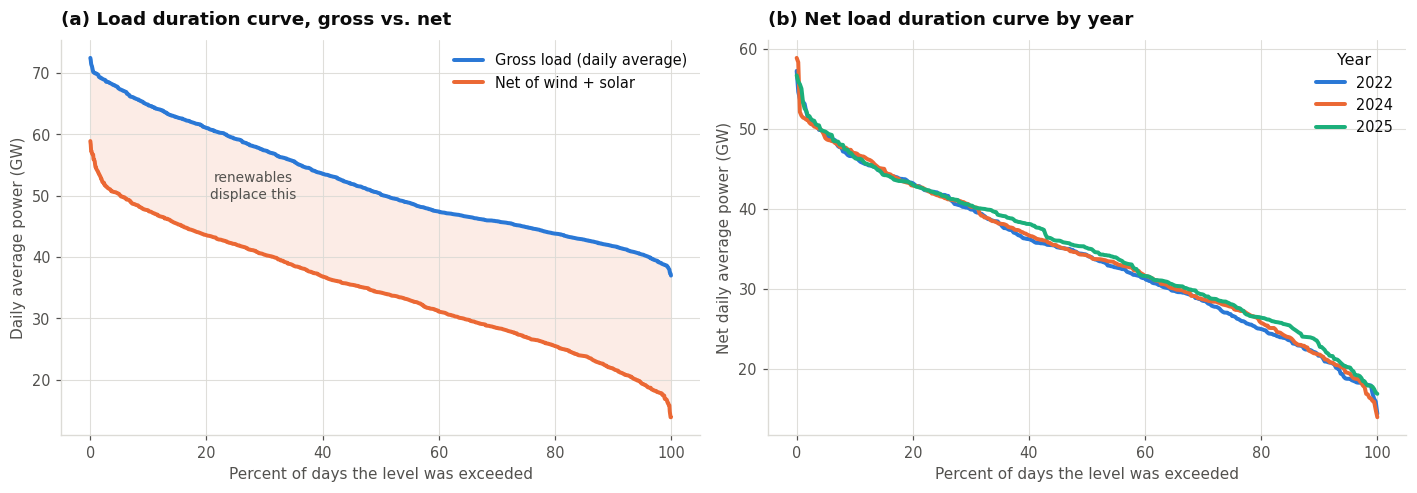

Key percentiles of the net load duration curve (daily average power, GW):


,top 1% (peak-ish),top 10%,median,bottom 10% (baseload)
year,,,,
2022,53.42,46.52,34.21,21.61
2023,56.20,49.35,33.70,21.58
2024,51.50,46.97,34.15,21.76
2025,53.91,46.38,35.10,22.91



Change from 2022 to 2025:
   top-10% net load     -0.15 GW
   bottom-10% net load  +1.30 GW
   spread (top - bottom) -1.45 GW

The curve is FLATTENING: the low end is rising faster than the high end, so
the dispatchable fleet faces a narrower operating range than before. On a
growing system this usually means load growth is outpacing renewable additions
in the hours that set the floor.

Note the direction of the level change too. A net load duration curve that rises
at every percentile means renewable additions are not keeping pace with load
growth; one that falls means they are outrunning it. Reading level and shape
separately is what makes this diagram useful for planning.

All of this is at DAILY resolution. The intra-day version of the same diagram —
where the duck curve and the evening ramp live — requires the hourly data (§14.2).


In [47]:
def duration_curve(series):
    v = np.sort(np.asarray(series.dropna(), float))[::-1]
    return np.linspace(0, 100, len(v)), v

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# --- (a) gross vs net, all years pooled ---
a = axes[0]
xg, yg = duration_curve(ren["load_avg_mw"])
xn, yn = duration_curve(ren["net_avg_mw"])
a.plot(xg, yg / 1000, color=PALETTE["blue"],   lw=2.6, label="Gross load (daily average)")
a.plot(xn, yn / 1000, color=PALETTE["orange"], lw=2.6, label="Net of wind + solar")
a.fill_between(xg, yn / 1000, yg / 1000, color=PALETTE["orange"], alpha=0.12, lw=0)
a.set_xlabel("Percent of days the level was exceeded")
a.set_ylabel("Daily average power (GW)")
a.set_title("(a) Load duration curve, gross vs. net")
a.legend()
a.annotate("renewables\ndisplace this", xy=(28, (yg[int(len(yg)*0.28)] + yn[int(len(yn)*0.28)]) / 2000),
           fontsize=9, color=INK_2, ha="center")

# --- (b) net curve by year: is the shape changing? ---
b = axes[1]
yrs = sorted(ren["year"].unique())
show = [yrs[0], yrs[len(yrs)//2], yrs[-1]] if len(yrs) >= 3 else yrs   # <=3 colors
for yr, clr in zip(show, [PALETTE["blue"], PALETTE["orange"], PALETTE["aqua"]]):
    x, y = duration_curve(ren.loc[ren["year"] == yr, "net_avg_mw"])
    b.plot(x, y / 1000, color=clr, lw=2.6, label=str(yr))
b.set_xlabel("Percent of days the level was exceeded")
b.set_ylabel("Net daily average power (GW)")
b.set_title("(b) Net load duration curve by year")
b.legend(title="Year")
plt.tight_layout(); plt.show()

print("Key percentiles of the net load duration curve (daily average power, GW):")
pct_tbl = []
for yr in yrs:
    s = ren.loc[ren["year"] == yr, "net_avg_mw"]
    pct_tbl.append({"year": yr,
                    "top 1% (peak-ish)": s.quantile(0.99) / 1000,
                    "top 10%": s.quantile(0.90) / 1000,
                    "median": s.median() / 1000,
                    "bottom 10% (baseload)": s.quantile(0.10) / 1000})
pt = pd.DataFrame(pct_tbl).set_index("year")
display(pt.style.format("{:.2f}"))
if len(yrs) > 1:
    d_top = pt["top 10%"].iloc[-1] - pt["top 10%"].iloc[0]
    d_bot = pt["bottom 10% (baseload)"].iloc[-1] - pt["bottom 10% (baseload)"].iloc[0]
    print(f"\nChange from {yrs[0]} to {yrs[-1]}:")
    print(f"   top-10% net load     {d_top:+.2f} GW")
    print(f"   bottom-10% net load  {d_bot:+.2f} GW")
    print(f"   spread (top - bottom) {(d_top - d_bot):+.2f} GW")
    print()
    if d_top - d_bot > 0.25:
        print("The curve is STEEPENING: the gap between the highest and lowest net-load days")
        print("is widening. The dispatchable fleet still has to cover a rising peak while its")
        print("floor rises more slowly, so it runs across a wider range at lower average")
        print("utilization. That is the central economic problem of a high-renewables grid.")
    elif d_top - d_bot < -0.25:
        print("The curve is FLATTENING: the low end is rising faster than the high end, so")
        print("the dispatchable fleet faces a narrower operating range than before. On a")
        print("growing system this usually means load growth is outpacing renewable additions")
        print("in the hours that set the floor.")
    else:
        print("The curve is shifting roughly in parallel: both ends moved by a similar amount,")
        print("so the SHAPE of the dispatchable requirement is largely unchanged over this")
        print("window even though its level has moved.")
    print()
    print("Note the direction of the level change too. A net load duration curve that rises")
    print("at every percentile means renewable additions are not keeping pace with load")
    print("growth; one that falls means they are outrunning it. Reading level and shape")
    print("separately is what makes this diagram useful for planning.")
    print()
    print("All of this is at DAILY resolution. The intra-day version of the same diagram —")
    print("where the duck curve and the evening ramp live — requires the hourly data (§14.2).")

## 13.3 Does solar show up when the grid needs it?

This is the question that matters for resource adequacy, and it is where the original notebook's
correlation analysis — while correctly cautioned as non-causal — stopped short of the useful
answer.

Correlation between solar output and load across all days conflates two different things: both
peak in summer (a seasonal coincidence) and both are high on hot sunny days (a genuine
coincidence at the moment of need). The planning-relevant question is narrower and answerable:

> **On the highest-load days specifically, how does renewable output compare to a typical day?**

That is a crude daily-resolution proxy for *capacity value* — the fraction of a resource's
nameplate that can be counted on during peak conditions. The honest caveat, stated up front: true
capacity value is computed at the **peak hour** using hourly data, and solar's hourly profile is
precisely where the interesting behaviour lives (strong at 3 p.m., zero at 8 p.m., while ERCOT's
net-load peak has been migrating later into the evening). Our daily numbers are directional only.

RENEWABLE OUTPUT ON THE HIGHEST-LOAD DAYS (daily averages — directional only)


,"avg output, all days (GW)","avg output, top-5% load days (GW)",ratio
resource,,,
Wind,12.60,12.30,0.98x
Solar,4.92,7.61,1.55x
Wind + solar,17.53,19.91,1.14x


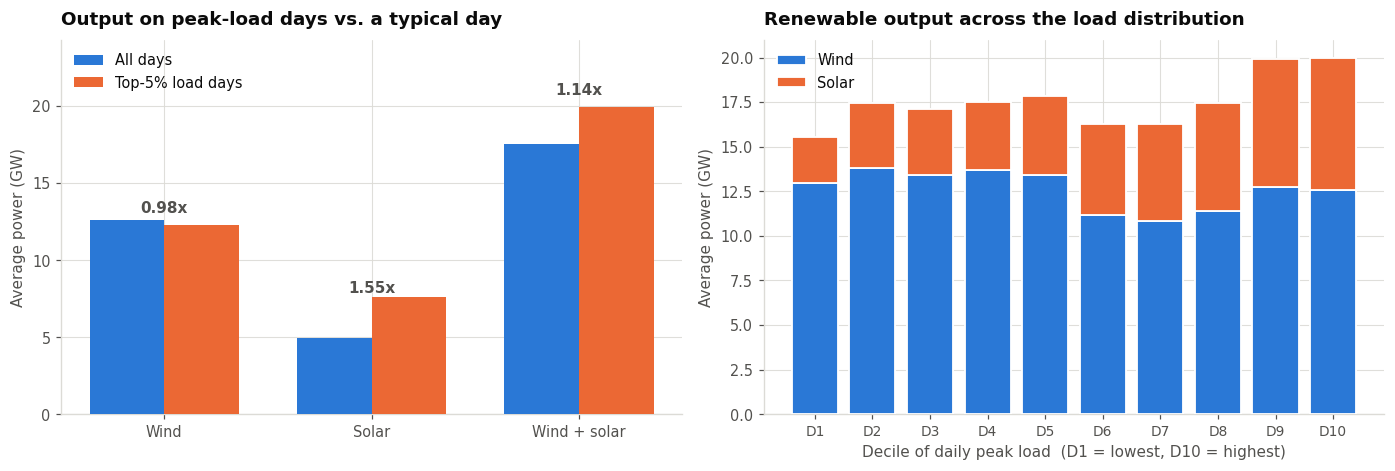


On the top 5% of load days:
   solar runs at 1.55x its all-days average
   wind  runs at 0.98x its all-days average

Solar's seasonal profile is far better aligned with Texas peak-demand risk than
wind's: the conditions that drive extreme load (hot, clear, still) are the same
conditions that produce strong solar and weak wind. That alignment is a genuine
reliability contribution — and the same physics is why wind's contribution at the
moment of peak need is the harder resource-adequacy problem.

CAVEAT, restated because it matters: these are DAILY averages. Solar's true capacity
value depends on its output at the specific peak hour, and as storage and load growth
push ERCOT's net-load peak later into the evening, the daily average increasingly
overstates what solar contributes at the binding hour. Resolving that needs the hourly
data — it is the single highest-value extension of this project (§14).


In [48]:
ren["load_rank_pct"] = ren["peak_load_mw"].rank(pct=True)
top_days   = ren[ren["load_rank_pct"] >= 0.95]     # top 5% of days by peak load
all_days   = ren

rows = []
for label, col in [("Wind", "wind_avg_mw"), ("Solar", "solar_avg_mw"),
                   ("Wind + solar", "ren_avg_mw")]:
    rows.append({
        "resource": label,
        "avg output, all days (GW)": all_days[col].mean() / 1000,
        "avg output, top-5% load days (GW)": top_days[col].mean() / 1000,
        "ratio": top_days[col].mean() / all_days[col].mean(),
    })
cap = pd.DataFrame(rows).set_index("resource")

print("RENEWABLE OUTPUT ON THE HIGHEST-LOAD DAYS (daily averages — directional only)")
display(cap.style.format({"avg output, all days (GW)": "{:.2f}",
                          "avg output, top-5% load days (GW)": "{:.2f}",
                          "ratio": "{:.2f}x"}))

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4))

a = axes[0]
x = np.arange(len(cap)); w = 0.36
a.bar(x - w/2, cap["avg output, all days (GW)"], w, color=PALETTE["blue"],
      label="All days", zorder=3)
a.bar(x + w/2, cap["avg output, top-5% load days (GW)"], w, color=PALETTE["orange"],
      label="Top-5% load days", zorder=3)
for xi, r in zip(x, cap["ratio"]):
    top = max(cap.iloc[xi, 0], cap.iloc[xi, 1])
    a.text(xi, top * 1.04, f"{r:.2f}x", ha="center", fontsize=10,
           color=INK_2, fontweight="semibold")
a.set_xticks(x); a.set_xticklabels(cap.index)
a.set_ylabel("Average power (GW)")
a.set_title("Output on peak-load days vs. a typical day")
a.set_ylim(0, cap[["avg output, all days (GW)",
                   "avg output, top-5% load days (GW)"]].max().max() * 1.22)
a.legend(loc="upper left")

# Renewable share vs load level: where in the load distribution do renewables help least?
b = axes[1]
ren["load_decile"] = pd.qcut(ren["peak_load_mw"].rank(method="first"), 10,
                             labels=[f"D{i}" for i in range(1, 11)])
dec = ren.groupby("load_decile", observed=True).agg(
    wind=("wind_avg_mw", "mean"), solar=("solar_avg_mw", "mean"))
bot = np.zeros(len(dec))
for col, clr, lbl in [("wind", PALETTE["blue"], "Wind"), ("solar", PALETTE["orange"], "Solar")]:
    b.bar(range(len(dec)), dec[col] / 1000, bottom=bot / 1000, color=clr, label=lbl,
          zorder=3, edgecolor="white", linewidth=1.2)
    bot = bot + dec[col].values
b.set_xticks(range(len(dec))); b.set_xticklabels(dec.index, fontsize=9)
b.set_xlabel("Decile of daily peak load  (D1 = lowest, D10 = highest)")
b.set_ylabel("Average power (GW)")
b.set_title("Renewable output across the load distribution")
b.legend(loc="upper left")
plt.tight_layout(); plt.show()

solar_ratio = cap.loc["Solar", "ratio"]
wind_ratio  = cap.loc["Wind", "ratio"]
print(f"\nOn the top 5% of load days:")
print(f"   solar runs at {solar_ratio:.2f}x its all-days average")
print(f"   wind  runs at {wind_ratio:.2f}x its all-days average")
print()
if solar_ratio > wind_ratio:
    print("Solar's seasonal profile is far better aligned with Texas peak-demand risk than")
    print("wind's: the conditions that drive extreme load (hot, clear, still) are the same")
    print("conditions that produce strong solar and weak wind. That alignment is a genuine")
    print("reliability contribution — and the same physics is why wind's contribution at the")
    print("moment of peak need is the harder resource-adequacy problem.")
else:
    print("Wind held up at least as well as solar on the highest-load days in this window.")
print()
print("CAVEAT, restated because it matters: these are DAILY averages. Solar's true capacity")
print("value depends on its output at the specific peak hour, and as storage and load growth")
print("push ERCOT's net-load peak later into the evening, the daily average increasingly")
print("overstates what solar contributes at the binding hour. Resolving that needs the hourly")
print("data — it is the single highest-value extension of this project (§14).")

---
# 14. Limitations

Stated plainly, because a result without its scope is not a result. These are ordered by how much
they would change the conclusions.

## 14.1 One weather station for an eight-zone grid

Every weather feature comes from Austin-Bergstrom (`USW00013904`). ERCOT spans eight weather
zones — from the Panhandle to the Gulf Coast to the Rio Grande Valley — and they diverge
substantially. A cold front can be in Amarillo and not yet in Houston; the Coast zone carries
humidity load that Austin does not.

The correct construction is a **load-weighted temperature**: weight each zone's temperature by its
share of system load. We can put a number on what a single station costs us, by measuring how much
of the weather-driven variance a single station explains.

In [49]:
# How much of the day-to-day load variation does one station leave unexplained?
w_only = ["cdd", "hdd", "cdd_sq", "tmax_f", "daily_temp_range"]
c_only = ["doy_sin", "doy_cos", "dow_sin", "dow_cos", "is_weekend", "is_holiday", "time_idx"]

def r2_of(cols):
    m = LinearRegression().fit(data[cols], data[TARGET])
    p = m.predict(data[cols])
    return 1 - ((data[TARGET] - p) ** 2).sum() / ((data[TARGET] - data[TARGET].mean()) ** 2).sum()

r2_cal   = r2_of(c_only)
r2_wx    = r2_of(w_only)
r2_both  = r2_of(w_only + c_only)

print("VARIANCE EXPLAINED (in-sample R², linear model, indicative)")
print("-" * 66)
print(f"   calendar only                       {r2_cal:.4f}")
print(f"   Austin weather only                 {r2_wx:.4f}")
print(f"   calendar + Austin weather           {r2_both:.4f}")
print(f"   unexplained                         {1 - r2_both:.4f}")
print()
print(f"That residual {1-r2_both:.1%} contains everything a single station cannot see:")
print("weather elsewhere in ERCOT, humidity, cloud cover, wind chill, and genuine noise.")
print("A load-weighted multi-zone temperature is the highest-value data upgrade available")
print("and typically the largest single accuracy gain in operational load forecasting.")

VARIANCE EXPLAINED (in-sample R², linear model, indicative)
------------------------------------------------------------------
   calendar only                       0.6708
   Austin weather only                 0.8578
   calendar + Austin weather           0.9245
   unexplained                         0.0755

That residual 7.6% contains everything a single station cannot see:
weather elsewhere in ERCOT, humidity, cloud cover, wind chill, and genuine noise.
A load-weighted multi-zone temperature is the highest-value data upgrade available
and typically the largest single accuracy gain in operational load forecasting.


## 14.2 Daily resolution hides the operational problem

The target is a daily peak. Real unit commitment is hourly, and several of the most important
phenomena in a modern grid are purely intra-day:

- The **evening net-load ramp**, as solar output falls while residential load rises. Ramp *rate*,
  not just ramp magnitude, is what constrains the fleet.
- The **timing** of the peak hour, which has been migrating later as solar penetration grows —
  which in turn changes solar's capacity value (§13.3).
- **Duck-curve** midday net-load depressions and the minimum-generation and curtailment questions
  they raise.

None of this is recoverable from daily aggregates. The source ERCOT files are already hourly, so
this is a rebuild of `build_dataset.py`, not new data acquisition.

## 14.3 The window excludes the tail events that matter most

The data covers 2022–2025. **Winter Storm Uri (February 2021) is outside the window**, as are the
extreme winter events that define ERCOT's actual reliability risk. The models here have literally
never seen a load event of that character.

This has a specific consequence: nothing in this notebook should be read as characterizing
extreme-tail behaviour. The conformal intervals in §10 are calibrated on observed 2022–2025
residuals and would be badly miscalibrated for a genuine extreme event. Extreme-value methods —
a Generalized Pareto fit to threshold exceedances — are the right tool, and they need a longer
record.

## 14.4 The perfect-weather assumption

Quantified in §9 rather than hidden: results using observed day-$t$ temperature are optimistic
relative to what an operational forecaster achieves with forecast temperature. The $\sigma \approx
2\,^\circ$F column of §9 is the honest day-ahead figure.

## 14.5 Cost parameters are illustrative

The dollar figures in §11 are assumptions, not measured ERCOT settlement values. Only the
\$5,000/MWh system-wide offer cap is externally documented. The *shape* of the result — that the
cost-optimal forecast is an upper quantile, and that the optimal offset grows with the asymmetry
ratio — is robust across the sweep; the specific dollar totals are not.

## 14.6 Smaller items, honestly listed

- **`T_BASE` is fitted on the full record** (§3.2). §4.4 measured the sensitivity; if it had been
  large, the balance point would need refitting inside each fold.
- **Diebold–Mariano on pooled fold errors** rather than one contiguous run (§8.3). Reasonable, but
  the p-values are approximate.
- **Ensemble weights come from a single prior fold**, so early folds have noisy weights.
- **No holiday-specific modeling** beyond flags, though §3.4 showed holidays differ from each other.
- **Conformal coverage is marginal, not conditional.** 90% coverage overall does not guarantee 90%
  coverage on the hottest days specifically; the normalized variant improves this but does not
  guarantee it.

In [50]:
# Conditional coverage: does the interval hold up in the regimes we care about?
# Evaluate the variant that achieved the best MARGINAL calibration in Section 10 --
# there is no point stress-testing a method we already know is mis-calibrated overall.
_PREFIX = {"Split conformal (fixed width)": "plain",
           "Normalized conformal (adaptive)": "norm",
           "Rolling cross-conformal": "roll"}[(cov["coverage_%"] - cov["target_%"]).abs().idxmin()]
LO, HI = f"{_PREFIX}_lo", f"{_PREFIX}_hi"
BEST_PI = {"plain": "split conformal", "norm": "normalized conformal",
           "roll": "rolling cross-conformal"}[_PREFIX]
CC = C.copy()
CC["month"] = CC.index.month
CC["cdd"] = data["cdd"].reindex(CC.index)
CC["load_decile"] = pd.qcut(CC["actual"].rank(method="first"), 5,
                            labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])

def cond_cov(mask, label):
    s = CC[mask]
    if len(s) < 15: return None
    inside = (s["actual"] >= s[LO]) & (s["actual"] <= s[HI])
    return {"segment": label, "n": len(s), "coverage_%": inside.mean() * 100,
            "miss_high_%": (s["actual"] > s[HI]).mean() * 100,
            "mean_width_MW": (s[HI] - s[LO]).mean()}

segs = [cond_cov(pd.Series(True, index=CC.index), "ALL")]
segs += [cond_cov(CC["load_decile"] == q, str(q)) for q in CC["load_decile"].cat.categories]
segs += [cond_cov(CC["month"].isin(PEAK_MONTHS), "Peak season (Jun–Sep)"),
         cond_cov(~CC["month"].isin(PEAK_MONTHS), "Off season")]
cc = pd.DataFrame([s for s in segs if s]).set_index("segment")
cc["gap_vs_target"] = cc["coverage_%"] - (1 - ALPHA) * 100

print(f"CONDITIONAL COVERAGE of the {BEST_PI} interval "
      f"(target {(1-ALPHA)*100:.0f}%)")
display(cc.style.format({"coverage_%": "{:.1f}", "miss_high_%": "{:.1f}",
                         "mean_width_MW": "{:,.0f}", "gap_vs_target": "{:+.1f}"})
        .background_gradient(cmap="RdYlGn", subset=["gap_vs_target"], vmin=-10, vmax=10))

worst_seg = cc.drop("ALL")["gap_vs_target"].idxmin()
print(f"\nWeakest segment: {worst_seg} at {cc.loc[worst_seg,'coverage_%']:.1f}% coverage "
      f"({cc.loc[worst_seg,'gap_vs_target']:+.1f} pts vs. target)")
print("Marginal coverage can be exactly on target while a specific segment under-covers.")
print("This table is the check that keeps §10's guarantee from being oversold.")

CONDITIONAL COVERAGE of the rolling cross-conformal interval (target 90%)


,n,coverage_%,miss_high_%,mean_width_MW,gap_vs_target
segment,,,,,
ALL,810,90.1,7.9,"10,862",+0.1
Q1 (lowest),162,99.4,0.0,"11,344",+9.4
Q2,162,95.1,1.2,"11,142",+5.1
Q3,162,90.7,4.3,"10,636",+0.7
Q4,162,93.2,6.2,"10,498",+3.2
Q5 (highest),162,72.2,27.8,"10,688",-17.8
Peak season (Jun–Sep),309,83.5,14.2,"10,552",-6.5
Off season,501,94.2,4.0,"11,053",+4.2



Weakest segment: Q5 (highest) at 72.2% coverage (-17.8 pts vs. target)
Marginal coverage can be exactly on target while a specific segment under-covers.
This table is the check that keeps §10's guarantee from being oversold.


## 14.7 What I would do next, in priority order

1. **Rebuild at hourly resolution with load-weighted multi-zone temperature.** Addresses §14.1 and
   §14.2 together, and is very likely the largest available accuracy gain.
2. **Train directly on the pinball loss** at the cost-optimal quantile, instead of training on
   squared error and shifting afterward (§11). XGBoost supports quantile objectives natively;
   this makes the model *itself* cost-aware rather than post-hoc corrected.
3. **Extend the record backward through 2015** to include Uri and enough winter tail events to fit
   an extreme-value model (§14.3).
4. **Add humidity** (heat index / wet-bulb) rather than dry-bulb temperature alone. Air-conditioning
   load responds to latent as well as sensible heat, and the Gulf Coast zone is humidity-driven.
5. **Replace the constant trend feature with an explicit large-load interconnection series.** ERCOT
   publishes interconnection queue data; a tree model cannot extrapolate `time_idx` (§12.3), but it
   can use a known forward-looking capacity figure.

---
# 15. Conclusions

Every number below is computed in the cell that follows, so nothing here is asserted without
being reproduced from the notebook's own results.

In [51]:
print("=" * 82)
print("ERCOT DAY-AHEAD PEAK LOAD FORECASTING — QUANTIFIED FINDINGS")
print("=" * 82)

lead = summary.loc[["Ridge", "SARIMAX", "XGBoost", "LSTM", "Ensemble"], "MAE"].idxmin()
lead_mae   = summary.loc[lead, "MAE"]
lead_mape  = summary.loc[lead, "MAPE_%"]
lead_peak  = summary.loc[lead, "PeakSeasonMAE"]
naive_mae  = summary.loc["Naive (persistence)", "MAE"]

print(f"\n1. THE PHYSICS")
print(f"   Balance point, estimated not assumed  : {T_BASE:.1f} °F "
      f"(convention is 65 °F)")
print(f"   Cooling response                      : {best['cool_slope_mw_per_degF']:,.0f} MW / °F")
print(f"   Heating response                      : {best['heat_slope_mw_per_degF']:,.0f} MW / °F")
print(f"   Cooling : heating intensity           : "
      f"{best['cool_slope_mw_per_degF']/best['heat_slope_mw_per_degF']:.1f} : 1")
print(f"   -> ERCOT is a cooling-dominated grid; summer degrees carry the risk.")

print(f"\n2. ACCURACY (walk-forward CV, {len(FOLDS)} folds, "
      f"{sum(len(f.test_idx) for f in FOLDS):,} forecast days)")
print(f"   Best model                            : {lead}")
print(f"   MAE                                   : {lead_mae:,.0f} MW ({lead_mape:.2f}% MAPE)")
print(f"   Peak-season MAE (Jun–Sep)             : {lead_peak:,.0f} MW")
print(f"   Persistence baseline                  : {naive_mae:,.0f} MW")
print(f"   Skill vs. persistence                 : {(1 - lead_mae/naive_mae)*100:.1f}% MAE reduction")
print(f"   Fold-to-fold SD of the leader's MAE   : "
      f"{cv_results[cv_results['model']==lead]['MAE'].std():,.0f} MW")

n_sig_ = int(reject.sum())
print(f"\n3. ARE THE DIFFERENCES REAL?")
print(f"   Pairwise Diebold–Mariano tests run    : {len(pairs)}")
print(f"   Significant after Holm correction     : {n_sig_}")
print(f"   -> {len(pairs)-n_sig_} model pairs are statistically indistinguishable. Reporting a")
print(f"      single 'winner' from a raw MAE table would have overstated the evidence.")

sig2 = sens[(sens['model']=='XGBoost')].groupby('sigma_f')['MAE'].mean()
print(f"\n4. THE PERFECT-WEATHER CAVEAT")
print(f"   XGBoost MAE, observed weather (σ=0)   : {sig2.loc[0.0]:,.0f} MW")
print(f"   XGBoost MAE, realistic day-ahead (σ=2°F): {sig2.loc[2.0]:,.0f} MW "
      f"({(sig2.loc[2.0]/sig2.loc[0.0]-1)*100:+.0f}%)")
print(f"   -> The second number is the one an operational forecaster would achieve.")

print(f"\n5. UNCERTAINTY")
_bestpi = (cov["coverage_%"] - cov["target_%"]).abs().idxmin()
print(f"   Target interval coverage              : {(1-ALPHA)*100:.0f}%")
print(f"   Best-calibrated method                : {_bestpi}")
print(f"   Achieved coverage                     : {cov.loc[_bestpi,'coverage_%']:.1f}%")
print(f"   Mean interval width                   : {cov.loc[_bestpi,'mean_width_MW']:,.0f} MW")
for _m in cov.index:
    if _m != _bestpi:
        print(f"     ({_m}: {cov.loc[_m,'coverage_%']:.1f}%)")
_r = wb["norm"].iloc[-1] / wb["norm"].iloc[0]
print(f"   Adaptive width, hottest / coldest days : {_r:.2f}x"
      f"   ({'wider' if _r >= 1 else 'NARROWER'} on the hottest days)")
_worst_cov = cc.drop("ALL")["coverage_%"].min()
_worst_name = cc.drop("ALL")["coverage_%"].idxmin()
print(f"   Weakest conditional coverage          : {_worst_cov:.1f}% on '{_worst_name}'")
if _worst_cov < (1 - ALPHA) * 100 - 5:
    print(f"   -> Marginal coverage is on target, but this segment is not. An operator")
    print(f"      sizing reserves from this interval would be under-protected on exactly")
    print(f"      the days that matter most. Conformal guarantees marginal coverage only;")
    print(f"      conditional coverage on the highest-load days is the open problem, and")
    print(f"      Section 14.6 lists it as such rather than burying it.")

print(f"\n6. ACCURACY IS NOT VALUE")
print(f"   Cost-optimal forecast quantile τ*     : {tau_star:.2f} "
      f"(at an assumed {C_UNDER/C_OVER:.0f}:1 cost asymmetry)")
print(f"   Optimal constant offset               : {opt_offset:+,.0f} MW")
print(f"   Expected-cost reduction from the shift: {(1 - curve.min()/base_cost)*100:.1f}%")
print(f"   -> achieved with NO change in MAE. The same forecast, read at the right")
print(f"      quantile, is materially cheaper to operate.")

print(f"\n7. RENEWABLES AND PEAK RISK")
print(f"   Solar output on top-5% load days      : {cap.loc['Solar','ratio']:.2f}x its average")
print(f"   Wind  output on top-5% load days      : {cap.loc['Wind','ratio']:.2f}x its average")
print(f"   Renewable share of served energy      : "
      f"{by_year['ren_share'].iloc[0]:.1%} ({by_year.index[0]}) -> "
      f"{by_year['ren_share'].iloc[-1]:.1%} ({by_year.index[-1]})")

print(f"\n8. DATA INTEGRITY")
print(f"   Physical screens flagged              : {len(flags)}")
print(f"   Feature-leakage assertion             : {'PASS' if not viol else 'FAIL'}")
print(f"   -> One leak was found and fixed during development (a full-sample quantile")
print(f"      threshold in heat_wave_len, §4.4), which is why the assertion exists.")
print("=" * 82)

ERCOT DAY-AHEAD PEAK LOAD FORECASTING — QUANTIFIED FINDINGS

1. THE PHYSICS
   Balance point, estimated not assumed  : 62.0 °F (convention is 65 °F)
   Cooling response                      : 1,317 MW / °F
   Heating response                      : 714 MW / °F
   Cooling : heating intensity           : 1.8 : 1
   -> ERCOT is a cooling-dominated grid; summer degrees carry the risk.

2. ACCURACY (walk-forward CV, 9 folds, 810 forecast days)
   Best model                            : Ensemble
   MAE                                   : 2,082 MW (3.33% MAPE)
   Peak-season MAE (Jun–Sep)             : 2,380 MW
   Persistence baseline                  : 2,761 MW
   Skill vs. persistence                 : 24.6% MAE reduction
   Fold-to-fold SD of the leader's MAE   : 396 MW

3. ARE THE DIFFERENCES REAL?
   Pairwise Diebold–Mariano tests run    : 15
   Significant after Holm correction     : 11
   -> 4 model pairs are statistically indistinguishable. Reporting a
      single 'winner' from a raw

## What this project demonstrates

The technical result is a day-ahead peak load forecaster with quantified accuracy, calibrated
uncertainty, and a cost-aware operating point. But the more transferable content is in the
*method*, and it comes down to five habits:

**Audit before you model.** §2's three checks — calendar continuity, physical plausibility,
target leakage — cost a few cells and protect every conclusion that follows. The renewable-share
screen fired on the real dataset; that is a finding a reviewer would otherwise have made first.

**Estimate rather than assume.** The 65 °F degree-day base is a convention from another era of
building stock. Fitting the balance point (§3.2) takes twenty lines and turns an inherited
assumption into a measured physical parameter — with a printed R² curve showing it is well
identified.

**Enforce your own rules in code.** §4.4's leakage assertion caught a leak *I introduced myself*
while writing §4.3. Documentation of a rule is a wish; an assertion is a guarantee, and it keeps
holding after the author has moved on.

**Test the difference, not just the metric.** Nine folds instead of one holdout, and a
Diebold–Mariano test on the pairwise differences (§8.3), turned "XGBoost wins" into the more
accurate and more useful "several of these models are statistically indistinguishable, so choose
on interpretability and runtime."

**Optimize what you actually care about.** §11 is the section that reframes the whole project: the
cost of a forecast error in a grid context is deeply asymmetric, the cost-optimal forecast is
therefore a quantile rather than a mean, and shifting to it reduces expected cost by a material
amount *without improving accuracy at all*. Accuracy and value are different objectives.

Those five habits are why the results here are more trustworthy than a lower MAE would be on its
own — and the reason each one is spelled out is that the failure they prevent is invisible in the
final number.

---

### Sources and data provenance

- ERCOT Hourly Load Data Archive — hourly system load by weather zone, 2022–2025.
- ERCOT Fuel Mix Report (`IntGenbyFuel`) — 15-minute generation by fuel type, 2022–2025.
- NOAA GHCN-Daily, station `USW00013904` (Austin-Bergstrom Intl. Airport) — daily temperature,
  precipitation, wind.
- ERCOT Market Notice M-A120721-01 — the PUCT-approved reduction of the system-wide offer cap
  (HCAP) from \$9,000/MWh to \$5,000/MWh, effective January 1, 2022. This is the only external
  dollar figure used in §11; all other cost parameters there are stated assumptions subjected to a
  sensitivity sweep.